# Génération de QCM avec validation automatique
**TALN — Sujet 11 — Filière IA & Science des Données, 5e année — EMSI Rabat — 2026/2027**

## Objectif
Le système lit un **support de cours** et produit des **questions à choix multiples (QCM)** : une question, **une** bonne réponse et **trois distracteurs** plausibles mais faux.
Les modèles de langage produisent des QCM rapidement, mais souvent défectueux : question sans réponse dans le cours, deux bonnes réponses, distracteur en réalité vrai…
Le cœur du projet est donc un **validateur automatique**, qui rejette les QCM défectueux, et la **mesure de ce qu'il apporte**.

## Plan du notebook
| Étape | Contenu |
|---|---|
| 0 | Configuration, reproductibilité |
| 1 | Collecte des 6 supports de cours (langage C) |
| 2 | Extraction et nettoyage du texte |
| 3 | Découpage en passages |
| 4 | Base de référence : questions à trous + distracteurs par embeddings (échantillon commun de 120 passages) |
| 5 | Modèle avancé : **LLM ouvert** (prompt few-shot, sortie JSON) |
| 6 | Contrôles de forme |
| 7 | Validateur : V1 répondabilité, V2 bonne réponse unique, V3 distracteurs faux |
| 8 | Filtrage et mesure de l'apport du filtre |
| 9 | Évaluation humaine (60 QCM) et accord entre évaluateurs |
| 10 | Ablations et sensibilité |
| 11 | Analyse des erreurs, limites, éthique |

## Choix du modèle avancé : un LLM ouvert plutôt qu'un modèle seq2seq fine-tuné
L'énoncé laisse le choix entre « un modèle de langage ou un modèle fine-tuné ». Nous retenons un **LLM ouvert instruit** (par exemple Qwen3-4B-Instruct, quantifié en 4 bits pour tenir sur le GPU de Colab), pour quatre raisons :
1. **Il produit tout le QCM.** Un modèle seq2seq (mT5, BARThez) fine-tuné sur FQuAD ou PIAF apprend seulement à produire une *question* à partir d'une réponse. Ces jeux de données ne contiennent **pas de distracteurs**, il faudrait donc un second système pour les créer. Le LLM génère question, bonne réponse et distracteurs en un seul appel.
2. **Pas de données d'entraînement de QCM en français.** Il n'existe pas de grand corpus public de QCM annotés en français. Le LLM fonctionne en *few-shot* : quelques exemples dans le prompt suffisent.
3. **Meilleurs distracteurs.** Un bon distracteur exige de comprendre le sens (une notion voisine mais fausse). Un LLM le fait bien mieux qu'un petit modèle seq2seq.
4. **Faisable sur Colab.** Un modèle d'environ 7 milliards de paramètres quantifié en 4 bits occupe environ 5 Go de mémoire GPU (une T4 en a 15).

Contrepartie assumée : un LLM **hallucine** parfois (fausse bonne réponse, distracteur vrai). C'est précisément ce que le validateur de l'étape 7 doit détecter, ce qui rend le volet avancé indispensable.

---
# Étape 0 — Configuration et reproductibilité

**À quoi sert cette étape ?**
- Installer les bibliothèques manquantes (sur Colab).
- Définir **en un seul endroit** tous les chemins et hyperparamètres du projet (dictionnaire `CONFIG`). Pour une ablation, on modifie une valeur ici sans chercher dans tout le notebook.
- **Fixer les graines aléatoires.** Le barème exige des résultats reproductibles : deux exécutions doivent donner les mêmes passages, le même échantillonnage et les mêmes QCM.

**Pourquoi ces choix ?**
- On fixe les graines de `random`, `numpy` **et** `torch`. Chaque bibliothèque a son propre générateur aléatoire : fixer seulement `random` laisserait `torch` (utilisé par le LLM) non déterministe.
- On utilise `pathlib.Path` plutôt que des chaînes de caractères. Les chemins fonctionnent alors pareil sous Windows, Linux et Colab.

**Exécution sur Google Colab.** L'étape 5 (LLM) a besoin d'un GPU, d'où Colab (*Exécution → Modifier le type d'exécution → GPU T4*). Deux façons d'amener le dépôt, au choix :

- **sans accès GitHub** : construire `taln-colab.zip` avec `make archive-colab`, le téléverser dans Colab et le décompresser dans `/content/TALN`. La première cellule détecte le dépôt et ne clone rien ;
- **avec GitHub** : le dépôt est privé, la cellule le clone avec un jeton personnel enregistré dans les **secrets Colab** (icône 🔑, nom `GITHUB_TOKEN`). On ne l'écrit jamais en clair dans le notebook.

En local, cette cellule ne fait rien.

In [3]:
# Sur Colab : utiliser le dépôt déjà téléversé (zip), sinon cloner le dépôt privé.
# Aucun accès GitHub n'est nécessaire si l'archive du dépôt est décompressée dans /content.
import os
from pathlib import Path

try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    DEPOT = "doaemalak/G-n-ration-de-QCM-avec-validation-automatique"
    dossier = "/content/" + DEPOT.split("/")[1]
    if not os.path.exists(dossier):
        # 1) archive téléversée puis décompressée : /content/TALN/ ou directement /content/
        for candidat in [Path("/content"), *sorted(Path("/content").glob("*"))]:
            if (candidat / "notebooks" / "QCM_generation_validation.ipynb").exists():
                dossier = str(candidat)
                print("Dépôt local trouvé :", dossier)
                break
        else:
            # 2) clone du dépôt privé (jeton GitHub dans les secrets Colab)
            from google.colab import userdata
            jeton = userdata.get("GITHUB_TOKEN")
            os.system(f"git clone -q https://{jeton}@github.com/{DEPOT}.git {dossier}")
    os.chdir(dossier)
print("Colab :", EN_COLAB, "| dossier courant :", os.getcwd())


Dépôt local trouvé : /content/TALN
Colab : True | dossier courant : /content/TALN


In [4]:
# Installation des dépendances absentes ou trop anciennes de Colab (sans effet ailleurs)
import subprocess, sys
from importlib.metadata import version, PackageNotFoundError

def installer(paquet, minimum=None):
    """Installe le paquet s'il manque, ou le met à jour s'il est plus ancien que `minimum`."""
    try:
        actuelle = version(paquet)
    except PackageNotFoundError:
        actuelle = None
    trop_vieux = bool(minimum) and actuelle is not None and \
        tuple(int(x) for x in actuelle.split(".")[:2]) < tuple(int(x) for x in minimum.split(".")[:2])
    if actuelle is None or trop_vieux:
        cible = paquet + (f">={minimum}" if minimum else "")
        print(f"installation de {cible} (actuel : {actuelle or 'absent'})…")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", cible], check=True)

# transformers >= 4.53 : Qwen3-2507 et SmolLM3 (sinon KeyError 'qwen3')
for paquet, minimum in [("pdfplumber", None), ("sentence-transformers", None),
                        ("transformers", "4.53"), ("accelerate", None)]:
    installer(paquet, minimum)


installation de pdfplumber (actuel : absent)…


In [5]:
import os, re, json, random, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

# --- Racine du dépôt : le notebook peut être lancé depuis notebooks/ ou depuis la racine ---
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

CONFIG = {
    "seed": 42,
    # Chemins
    "raw_dir":       ROOT / "data" / "raw",
    "processed_dir": ROOT / "data" / "processed",
    "annot_dir":     ROOT / "data" / "annotations",
    "qcm_dir":       ROOT / "outputs" / "qcm",
    "fig_dir":       ROOT / "outputs" / "figures",
    # Découpage en passages (étape 3)
    "chunk_min_words": 150,
    "chunk_max_words": 300,
    "chunk_drop_below": 60,      # un reste de moins de 60 mots est trop pauvre pour une question
    # Tokenizer de référence pour calibrer la longueur des passages (le modèle QA du validateur est choisi à l'étape 7)
    "qa_tokenizer": "almanach/camembert-base",
    "qa_max_tokens": 512,
}
for k, v in CONFIG.items():
    if k.endswith("_dir"):
        v.mkdir(parents=True, exist_ok=True)

def set_seed(seed: int) -> None:
    # Fixe toutes les sources d'aléa utilisées dans le projet.
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass

set_seed(CONFIG["seed"])

# Versions affichées dans le notebook pour la reproductibilité
print("Racine du projet :", ROOT)
print("Python :", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__)
try:
    import torch
    print("torch", torch.__version__, "| GPU disponible :", torch.cuda.is_available())
except ImportError:
    print("torch non installé")

Racine du projet : /content/TALN
Python : 3.13.16 | pandas 2.2.3 | numpy 2.4.6
torch 2.14.1+cu130 | GPU disponible : True


---
# Étape 1 — Collecte des supports de cours

**À quoi sert cette étape ?** L'énoncé exige **au moins cinq supports de cours publics ou fournis par l'enseignant**. Ce sont le texte d'entrée du générateur et la référence du validateur : un QCM n'est valide que s'il est répondable **à partir de ce texte**.

**Notre corpus : 6 supports de cours PDF sur la programmation en langage C**, écrits par 6 auteurs ou établissements différents.

| id | Fichier | Titre | Auteur / établissement | Format |
|---|---|---|---|---|
| C1 | `cours.pdf` | Programmation en langage C | Anne Canteaut (INRIA) | polycopié LaTeX |
| C2 | `LelangageC_rgww.pdf` | Le langage C | Patrick Trau | polycopié |
| C3 | `cours_programmation_c.pdf` | Programmation C | M. E. Elhdhili, H. Boucetta | polycopié Word |
| C4 | `annexe_08_2_cours_programmation en langage C.pdf` | Programmation en langage C | M. Qbadou (ENSET Mohammedia), 2022/2023 | polycopié Word |
| C5 | `coursC.pdf` | Initiation au langage C | auteur non indiqué | polycopié LaTeX |
| C6 | `support-C-JacquelinCharbonnel.pdf` | Cours de langage C | Jacquelin Charbonnel (CNRS) | diapositives |

**Pourquoi un seul sujet (le langage C) et 6 auteurs, plutôt que 6 matières différentes ?**
- **Cas d'usage réaliste.** Un enseignant veut des QCM sur **sa** matière. Le corpus correspond à ce scénario.
- **Une même notion, plusieurs rédactions.** Les pointeurs, les boucles ou les opérateurs sont expliqués 6 fois, avec des styles différents. On pourra vérifier si la qualité des QCM dépend du **style de rédaction** (polycopié détaillé contre diapositives télégraphiques) plutôt que du contenu.
- **Vocabulaire technique.** Le C mêle français et termes de code (`int`, `printf`, `malloc`). C'est un vrai défi pour le générateur, et surtout pour le validateur, dont les modèles sont entraînés sur du français général.
- **Plusieurs formats PDF** (LaTeX, Word, diapositives). Le nettoyage de l'étape 2 doit être robuste, et cette difficulté est documentée.

**Droits d'auteur.** Ces supports sont accessibles publiquement, mais leurs auteurs en gardent les droits. On les cite dans `sources.csv` et dans l'article, et on **ne redistribue pas les PDF** : ils sont exclus du dépôt GitHub par `.gitignore`. Pour exécuter le notebook, on dépose les PDF dans `data/raw/`. Sur Colab, la cellule ci-dessous propose de les téléverser s'ils manquent.

**Exécution sans intervention sur Colab.** Déposer les six PDF dans un dossier
`MyDrive/TALN/pdf` (ou indiquer un autre dossier avec la variable `QCM_PDF_DIR`) :
la cellule ci-dessous les copie, et « Tout exécuter » va jusqu'au bout sans prompt
d'upload. Une seule autorisation Google Drive est à cliquer. En fin d'exécution, la
dernière cellule du notebook range caches, scores, figures et grilles dans
`MyDrive/TALN/sorties_taln.zip`.

**Données personnelles.** Deux PDF contiennent l'adresse e-mail de leur auteur. Ces adresses sont supprimées à l'étape 2. Seuls les noms des auteurs sont conservés, car ils sont nécessaires pour citer les sources.

In [6]:
COURS = [
    {"id": "C1", "fichier": "cours.pdf",                   "titre": "Programmation en langage C",
     "auteur": "Anne Canteaut (INRIA)",                    "format": "polycopié LaTeX"},
    {"id": "C2", "fichier": "LelangageC_rgww.pdf",         "titre": "Le langage C",
     "auteur": "Patrick Trau",                             "format": "polycopié"},
    {"id": "C3", "fichier": "cours_programmation_c.pdf",   "titre": "Programmation C",
     "auteur": "M. E. Elhdhili, H. Boucetta",              "format": "polycopié Word"},
    {"id": "C4", "fichier": "annexe_08_2_cours_programmation en langage C.pdf",
     "titre": "Programmation en langage C",
     "auteur": "M. Qbadou (ENSET Mohammedia), 2022/2023",  "format": "polycopié Word"},
    {"id": "C5", "fichier": "coursC.pdf",                  "titre": "Initiation au langage C",
     "auteur": "non indiqué",                              "format": "polycopié LaTeX"},
    {"id": "C6", "fichier": "support-C-JacquelinCharbonnel.pdf", "titre": "Cours de langage C",
     "auteur": "Jacquelin Charbonnel (CNRS)",              "format": "diapositives"},
]

# Les PDF ne sont pas versionnés : on les cherche (1) dans data/raw, (2) dans un dossier
# Google Drive, (3) sinon on les demande. Le dossier Drive évite toute intervention
# manuelle : « Tout exécuter » va alors jusqu'au bout sans prompt d'upload.
PDF_DRIVE = Path(os.environ.get("QCM_PDF_DIR", "/content/drive/MyDrive/TALN/pdf"))
if EN_COLAB and not all((CONFIG["raw_dir"] / c["fichier"]).exists() for c in COURS) \
        and not PDF_DRIVE.exists():
    try:
        from google.colab import drive
        drive.mount("/content/drive")     # une autorisation à cliquer, une seule fois
    except Exception as e:                # Drive refusé : on retombe sur le téléversement
        print("Drive non monté :", e)

for c in COURS:
    destination = CONFIG["raw_dir"] / c["fichier"]
    if not destination.exists() and (PDF_DRIVE / c["fichier"]).exists():
        destination.write_bytes((PDF_DRIVE / c["fichier"]).read_bytes())

manquants = [c["fichier"] for c in COURS if not (CONFIG["raw_dir"] / c["fichier"]).exists()]
if manquants:
    try:                                   # Sur Colab : téléversement des PDF manquants
        from google.colab import files
        print("PDF manquants, à téléverser (ou à déposer dans", PDF_DRIVE, ") :", manquants)
        for nom, contenu in files.upload().items():
            (CONFIG["raw_dir"] / nom).write_bytes(contenu)
    except ImportError:
        raise FileNotFoundError(f"Déposer ces PDF dans {CONFIG['raw_dir']} : {manquants}")

import pdfplumber
for c in COURS:
    with pdfplumber.open(CONFIG["raw_dir"] / c["fichier"]) as pdf:
        c["n_pages"] = len(pdf.pages)
    c["taille_Ko"] = round((CONFIG["raw_dir"] / c["fichier"]).stat().st_size / 1024)
    c["licence"] = "droits réservés à l'auteur — usage pédagogique, non redistribué"

sources = pd.DataFrame(COURS)
assert len(sources) >= 5, "L'énoncé exige au moins 5 supports de cours."
sources[["id", "titre", "auteur", "format", "n_pages", "taille_Ko"]]

,id,titre,auteur,format,n_pages,taille_Ko
0,C1,Programmation en langage C,Anne Canteaut (INRIA),polycopié LaTeX,133,432
1,C2,Le langage C,Patrick Trau,polycopié,71,336
2,C3,Programmation C,"M. E. Elhdhili, H. Boucetta",polycopié Word,76,724
3,C4,Programmation en langage C,"M. Qbadou (ENSET Mohammedia), 2022/2023",polycopié Word,68,1379
4,C5,Initiation au langage C,non indiqué,polycopié LaTeX,52,287
5,C6,Cours de langage C,Jacquelin Charbonnel (CNRS),diapositives,60,635


---
# Étape 2 — Extraction et nettoyage du texte

**À quoi sert cette étape ?** Transformer chaque PDF en **texte propre, découpé par section**. Le texte extrait brut d'un PDF contient beaucoup d'éléments inutiles, voire nuisibles, pour générer des questions. Nous les avons repérés en lisant l'extraction brute des 6 cours :

| Problème observé | Exemple | Traitement |
|---|---|---|
| Accents LaTeX détachés (C1, C5) | `´et´e`, `con¸cu`, `syst`eme` | Recollage de l'accent sur sa voyelle, puis normalisation Unicode |
| Espaces manquants (C5) | `Lefichiersourcecontient…` | Tolérance d'espacement de `pdfplumber` réduite (`x_tolerance=1.5`) |
| Ligatures typographiques | `aﬁn` (ﬁ = 1 caractère) | Normalisation Unicode NFKC → `afin` |
| Table des matières | `1.4 Les types ........ 13` | Ligne supprimée si elle contient des points de conduite |
| En-têtes et pieds de page | `Le langage C − cours P.TRAU`, `1.3. Présentation du langage 9` | Ligne en haut ou en bas de page répétée sur plusieurs pages, ou titre suivi d'un numéro de page |
| **Code source** | `int main() {`, `printf("%d", x);` | Ligne supprimée (voir ci-dessous) |
| Sections non pédagogiques | Exercices, corrigés, index, bibliographie | Section entière supprimée |
| Tableaux de valeurs | table ASCII : `46 56 2e N 78 116 4e n …` | Ligne supprimée si moins de 40 % de ses éléments sont des mots |
| Mots coupés en fin de ligne | `préproces-\nseur` | Recollés |
| Adresses e-mail, URL | adresse d'un auteur | Supprimées (données personnelles) |

On **conserve le titre de section** de chaque bloc de texte. Il sert à l'étape 3 (on ne découpe pas à travers deux sections) puis à l'analyse des erreurs (quelles sections produisent de mauvais QCM ?).

**Pourquoi supprimer le code source ?** C'est le choix le plus discutable, alors justifions-le :
1. Le **validateur** repose sur un modèle de questions-réponses et un modèle d'inférence (NLI) entraînés sur du **français en prose**. Ils ne savent pas vérifier une question du type « que affiche ce programme ? », qui demande d'*exécuter* mentalement le code.
2. Une fois aplati en texte par l'extraction PDF, le code perd son indentation et ses retours à la ligne. Il devient illisible pour le générateur.
3. Les **notions** (rôle de `printf`, différence entre `while` et `do…while`, arithmétique des pointeurs) restent expliquées **en prose** autour du code. Les mots-clés cités dans une phrase sont donc conservés.

*Limite assumée* : on ne génère pas de QCM de lecture de code. Ce point sera discuté dans l'article. Ce serait une extension possible, avec un validateur qui exécute le code.

**Pourquoi des règles et pas un modèle pour nettoyer ?** Les défauts sont **réguliers et identifiés** (motifs d'accents, points de conduite, syntaxe du C). Des règles sont transparentes, rapides, et on **compte** ce que chacune supprime (tableau plus bas). Un modèle pourrait supprimer du contenu utile sans qu'on le voie.

**Pourquoi `pdfplumber` plutôt que PyMuPDF ?** Nous avons comparé les deux. PyMuPDF sépare les numéros de section de leur titre (`1.1` puis `Historique` sur deux lignes), ce qui empêche de repérer les sections. `pdfplumber` garde `1.1 Historique` sur une ligne et permet de régler l'espacement entre les mots.

In [7]:
import unicodedata
from collections import Counter

# ---------- 1. Réparation des accents LaTeX : "´et´e" -> "été" ----------
ACCENT_COMBINANT = {"´": "\u0301", "`": "\u0300", "ˆ": "\u0302", "¨": "\u0308", "˜": "\u0303"}
VOYELLES = "aeiouyAEIOUYı"

def reparer_accents(t: str) -> str:
    t = re.sub(r"¸\s?([cC])", "\\1\u0327", t)          # cédille avant le c : "con¸cu"
    t = re.sub(r"([cC])¸", "\\1\u0327", t)             # cédille après le c : "plac¸ons"
    # accent placé AVANT sa voyelle : "´e" -> "é"
    t = re.sub(r"([´`ˆ¨˜])\s?([" + VOYELLES + r"])", lambda m: m.group(2) + ACCENT_COMBINANT[m.group(1)], t)
    # accent restant, placé APRÈS sa voyelle : "Pre´sentation", "ou`" -> "é", "ù"
    t = re.sub(r"([" + VOYELLES + r"])([´`ˆ¨˜])", lambda m: m.group(1) + ACCENT_COMBINANT[m.group(2)], t)
    t = t.replace("ı\u0302", "î").replace("ı\u0308", "ï").replace("ı", "i")
    # NFC fusionne lettre + accent combinant ; NFKC remplace les ligatures ("ﬁ" -> "fi")
    return unicodedata.normalize("NFKC", unicodedata.normalize("NFC", t))

# ---------- 2. Règles de repérage des lignes ----------
RE_SOMMAIRE = re.compile(r"(\.\s?){4,}|…{2,}")
RE_CODE = re.compile(r"^\s*(\d+\s+)?(#\s*(include|define|if|endif|else)|int\s|char\s|float\s|double\s|void\s"
                     r"|long\s|struct\s|typedef\s|return\b|printf\s*\(|scanf\s*\(|for\s*\(|while\s*\(|if\s*\("
                     r"|else\b|switch\s*\(|case\s|[{}])")
SYMBOLES_CODE = set("{}();=<>[]#&|%*")

def est_tableau(l: str) -> bool:
    # Ligne de tableau (codes ASCII, valeurs numériques) : moins de 40 % de vrais mots
    elements = l.split()
    mots = [e for e in elements if re.fullmatch(r"[A-Za-zÀ-ÿ'’\-]{3,}[.,:;]?", e)]
    return len(elements) >= 4 and len(mots) / len(elements) < 0.4

def est_code(l: str) -> bool:
    # Ligne de code C : commence par un mot-clé ou une accolade, finit par ; { }, ou est riche en symboles
    if RE_CODE.match(l) or l.rstrip().endswith((";", "{", "}")):
        return True
    return sum(c in SYMBOLES_CODE for c in l) / max(len(l), 1) > 0.08

RE_TITRE = re.compile(r"^(CHAPITRE|Chapitre)\s+\d+\b.*$|^(\d{1,2}(\.\d{1,2}){0,3})\.?\s+([A-ZÀÂÉÈÊÎÔÛÇ].{2,80})$")

def titre_de(l: str):
    # Renvoie le titre si la ligne est un titre numéroté ("1.2 La compilation", "CHAPITRE 3 : …")
    m = RE_TITRE.match(l)
    if not m or len(l.split()) > 10 or l.rstrip().endswith((",", "-", ";", ".")):
        return None
    return l.strip()

RE_EXCLURE = re.compile(r"\b(exercices?|corrections?|corrigés?|solutions?|bibliographie|index|annexes?|"
                        r"sommaire|table des matières|références|travaux pratiques|objectifs pédagogiques)\b")
RE_PERSO = re.compile(r"\S+@\S+|https?://\S+|www\.\S+")

def nettoyer_pdf(chemin: Path, x_tol: float = 1.5):
    # Renvoie (liste de {section, texte}, compteur de lignes par traitement, nb de mots bruts)
    with pdfplumber.open(chemin) as pdf:
        pages = [reparer_accents(p.extract_text(x_tolerance=x_tol) or "").splitlines() for p in pdf.pages]
    pages = [[l.strip() for l in p if l.strip()] for p in pages]
    n_mots_brut = sum(len(l.split()) for p in pages for l in p)

    # En-têtes / pieds : lignes des bords de page qui reviennent sur ≥ 3 pages (chiffres ignorés)
    cle = lambda l: re.sub(r"\d+", "#", l)
    bords = Counter(cle(l) for p in pages for l in set(p[:2] + p[-2:]))
    repetes = {k for k, n in bords.items() if n >= 3}

    stats, flux, section, exclure = Counter(), {}, "Début", False
    for p in pages:
        for i, l in enumerate(p):
            au_bord = i < 2 or i >= len(p) - 2
            if au_bord and (cle(l) in repetes or re.fullmatch(r"[\d\s\-–/]+", l)
                            or (titre_de(l) and re.search(r"\s\d{1,3}$", l))):
                stats["en-tête / pied de page"] += 1; continue
            if RE_SOMMAIRE.search(l):
                stats["table des matières"] += 1; continue
            t = titre_de(l)
            if t:
                nom = re.sub(r"^(CHAPITRE|Chapitre)?\s*[\d.]*\s*:?\s*", "", t).strip(" :") or t
                exclure = bool(RE_EXCLURE.search(nom.lower()))
                section = nom
                stats["titre de section"] += 1; continue
            if exclure:
                stats["section exclue"] += 1; continue
            if est_code(l):
                stats["code source"] += 1; continue
            if est_tableau(l):
                stats["tableau"] += 1; continue
            flux.setdefault(section, []).append(RE_PERSO.sub("", l))
            stats["conservée"] += 1

    paragraphes = []
    for s, lignes in flux.items():
        texte = "\n".join(lignes)
        texte = re.sub(r"(\w)-\n(\w)", r"\1\2", texte)      # mots coupés en fin de ligne
        texte = re.sub(r"\s*\n\s*", " ", texte)             # une section = un texte continu
        texte = re.sub(r"\s+", " ", texte).strip()
        texte = re.sub(r"\s+([,.;:!?)])", r"\1", texte)
        if len(texte.split()) >= 30:                        # section quasi vide (titre seul) : ignorée
            paragraphes.append({"section": s, "texte": texte})
    return paragraphes, stats, n_mots_brut

corpus, stats_lignes = {}, {}
for c in COURS:
    corpus[c["id"]], stats_lignes[c["id"]], c["n_mots_brut"] = nettoyer_pdf(CONFIG["raw_dir"] / c["fichier"])

sources = pd.DataFrame(COURS)
sources["n_mots_nettoye"] = [sum(len(p["texte"].split()) for p in corpus[i]) for i in sources["id"]]
sources["n_sections"] = [len(corpus[i]) for i in sources["id"]]
sources["%_retire"] = (100 * (1 - sources["n_mots_nettoye"] / sources["n_mots_brut"])).round(1)
sources.to_csv(CONFIG["raw_dir"] / "sources.csv", index=False)

# Sauvegarde du texte nettoyé (traçabilité : on peut relire ce que le modèle a reçu)
with open(CONFIG["processed_dir"] / "corpus_nettoye.jsonl", "w", encoding="utf-8") as f:
    for cid, pars in corpus.items():
        for p in pars:
            f.write(json.dumps({"cours_id": cid, **p}, ensure_ascii=False) + "\n")

sources[["id", "titre", "format", "n_pages", "n_mots_brut", "n_mots_nettoye", "%_retire", "n_sections"]]

,id,titre,format,n_pages,n_mots_brut,n_mots_nettoye,%_retire,n_sections
0,C1,Programmation en langage C,polycopié LaTeX,133,36361,23243,36.1,85
1,C2,Le langage C,polycopié,71,20292,12452,38.6,57
2,C3,Programmation C,polycopié Word,76,21115,13247,37.3,103
3,C4,Programmation en langage C,polycopié Word,68,11764,5663,51.9,64
4,C5,Initiation au langage C,polycopié LaTeX,52,14726,8145,44.7,58
5,C6,Cours de langage C,diapositives,60,10126,3730,63.2,41


**Que supprime chaque règle ?** On compte, pour chaque cours, le nombre de lignes traitées par chaque règle. Ce graphique justifie le nettoyage dans l'article et révèle les différences de format. Par exemple, les diapositives (C6) et le polycopié de C4 sont très riches en code.

,conservée,code source,tableau,section exclue,table des matières,en-tête / pied de page,titre de section
C1,2734,1646,207,4,141,172,110
C2,981,536,52,1073,104,130,67
C3,1438,863,77,0,154,157,136
C4,703,969,58,25,93,147,106
C5,773,473,52,6,74,71,84
C6,540,691,60,39,94,128,81


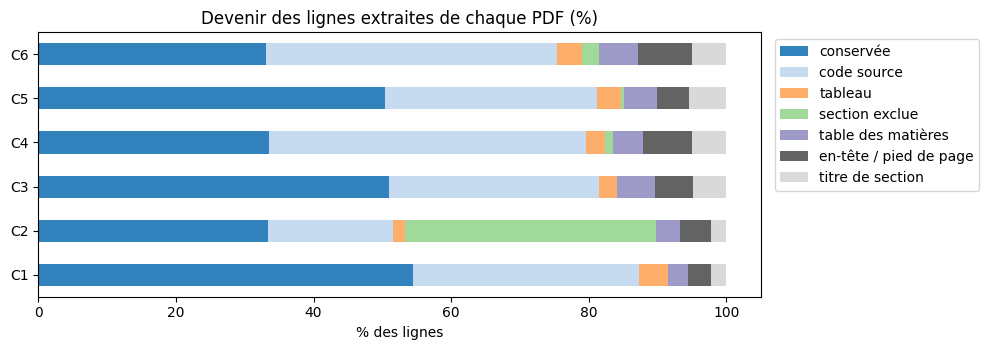

In [8]:
df_lignes = pd.DataFrame(stats_lignes).T.fillna(0).astype(int)
ordre_cols = ["conservée", "code source", "tableau", "section exclue", "table des matières",
              "en-tête / pied de page", "titre de section"]
df_lignes = df_lignes[[c for c in ordre_cols if c in df_lignes.columns]]
display(df_lignes)

(df_lignes.div(df_lignes.sum(axis=1), axis=0) * 100).plot.barh(
    stacked=True, figsize=(10, 3.6), colormap="tab20c",
    title="Devenir des lignes extraites de chaque PDF (%)")
plt.xlabel("% des lignes"); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.savefig(CONFIG["fig_dir"] / "nettoyage_lignes.png", dpi=150); plt.show()

**Vérification visuelle.** On affiche les sections retenues pour un cours et un extrait de texte nettoyé. On contrôle ainsi que les accents sont réparés (C1 est un PDF LaTeX), qu'il ne reste ni code ni sommaire, et que les titres de section ont du sens.

In [9]:
cid = "C1"
print("Sections conservées :", [p["section"] for p in corpus[cid]][:30], "…\n")
ex = next(p for p in corpus[cid] if p["section"].lower().startswith("la compilation"))
print(f"[{ex['section']}]\n{ex['texte'][:900]}")

Sections conservées : ['Historique', 'La compilation', 'Les composants élémentaires du C', 'Les identificateurs', 'Les mots-clefs', 'Les commentaires', 'Structure d’un programme C', 'Les types prédéfinis', 'Le type caractère', 'Les types entiers', 'Les types flottants', 'Les constantes', 'Les constantes entières', 'Les constantes réelles', 'Les constantes caractères', 'Les constantes chaînes de caractères', 'L’affectation', 'Les opérateurs arithmétiques', 'Les opérateurs relationnels', 'Les opérateurs logiques booléens', 'Les opérateurs logiques bit à bit', 'Les opérateurs d’incrémentation et de décrémentation', 'L’opérateur virgule', 'L’opérateur conditionnel ternaire', 'Règles de priorité des opérateurs', 'Les instructions de branchement conditionnel', 'Branchement conditionnel if---else', 'Branchement multiple switch', 'Boucle while', 'Boucle do---while'] …

[La compilation]
Le C est un langage compilé (par opposition aux langages interprétés). Cela signifie qu’un programme C est dé

---
# Étape 3 — Découpage en passages

**À quoi sert cette étape ?** On ne donne pas un cours entier au générateur ni au validateur. On le découpe en **passages** de **150 à 300 mots**. **Chaque QCM sera généré à partir d'un seul passage et validé contre ce même passage.**

**Pourquoi découper ?**
1. **Contrainte technique du validateur.** Le modèle de questions-réponses du validateur (un encodeur de type BERT) lit au plus **512 tokens** à la fois, **question comprise**. Un passage trop long serait tronqué : la réponse pourrait se trouver dans la partie coupée et le QCM serait rejeté à tort.
2. **Validation précise.** Si on générait à partir d'un chapitre entier, il faudrait chercher *où* se trouve la réponse avant de pouvoir vérifier le QCM. Avec un passage court, on sait exactement contre quel texte vérifier.
3. **Couverture du cours.** On peut tirer des passages dans toutes les sections, ce qui évite des questions qui portent toutes sur l'introduction.

**Pourquoi 150 à 300 mots ?**
- **Moins de 150 mots** : trop peu d'information pour une question **et** trois distracteurs crédibles.
- **Plus de 300 mots** : en français, CamemBERT découpe un mot en environ 1,4 token. 300 mots font donc environ 420 tokens, ce qui laisse une marge pour la question (environ 30 tokens) sous la limite de 512. On le **vérifie** plus bas avec le vrai tokenizer.

**Pourquoi découper sur les frontières de paragraphes et de phrases, et pas tous les N mots ?** Une coupe arbitraire peut séparer une définition de son explication, ou couper une phrase en deux. On regroupe donc des **paragraphes entiers** de la même section. Un paragraphe trop long est coupé **entre deux phrases**.

**Pourquoi ne pas mélanger deux sections dans un passage ?** Un passage doit traiter d'un seul sujet. Sinon, le LLM risque de produire des questions qui croisent deux sujets, ou des distracteurs pris dans l'autre section et en réalité corrects.

**Pourquoi pas de chevauchement entre passages ?** Le chevauchement est utile en recherche documentaire (RAG). Ici, il ferait générer deux fois des questions sur les mêmes phrases, donc des QCM en double.

In [10]:
# Découpage en phrases par expression régulière : fin de phrase (. ! ?) suivie d'une majuscule.
# On n'utilise pas spaCy ici : le découpage ne sert qu'à couper les très longs paragraphes, une règle suffit.
RE_PHRASE = re.compile(r"(?<=[.!?…])\s+(?=[A-ZÀÂÉÈÊÎÔÛÇ«\"(0-9])")

def decouper_phrases(texte: str) -> list[str]:
    return [p.strip() for p in RE_PHRASE.split(texte) if p.strip()]

def decouper_en_passages(paragraphes, min_w, max_w, drop_below):
    # Regroupe des paragraphes consécutifs de la même section en passages de min_w à max_w mots.
    # 1) Unités de base : un paragraphe, ou ses phrases s'il dépasse max_w mots
    unites = []
    for p in paragraphes:
        if len(p["texte"].split()) <= max_w:
            unites.append(p)
        else:
            unites += [{"section": p["section"], "texte": ph} for ph in decouper_phrases(p["texte"])]

    passages, courant, section = [], [], None
    def n_mots(lst): return sum(len(u.split()) for u in lst)
    def fermer():
        if courant:
            passages.append({"section": section, "texte": " ".join(courant)})

    for u in unites:
        w = len(u["texte"].split())
        # On ferme le passage courant si on change de section, si l'ajout dépasserait max_w,
        # ou s'il a déjà atteint min_w (on vise des passages de taille homogène).
        if courant and (u["section"] != section or n_mots(courant) + w > max_w
                        or n_mots(courant) >= min_w):
            fermer()
            courant = []
        section = u["section"]
        courant.append(u["texte"])
    fermer()

    # Un reste trop court est fusionné avec le passage précédent de la même section si la taille
    # le permet ; sinon il est écarté (pas assez de matière pour une question et 3 distracteurs).
    resultat = []
    for p in passages:
        w = len(p["texte"].split())
        if w < drop_below:
            if resultat and resultat[-1]["section"] == p["section"] \
               and len(resultat[-1]["texte"].split()) + w <= max_w:
                resultat[-1]["texte"] += " " + p["texte"]
            continue
        resultat.append(p)
    return resultat

passages = []
for cid, pars in corpus.items():
    for k, p in enumerate(decouper_en_passages(pars, CONFIG["chunk_min_words"],
                                               CONFIG["chunk_max_words"], CONFIG["chunk_drop_below"])):
        passages.append({"passage_id": f"{cid}_{k:03d}", "cours_id": cid,
                         "section": p["section"], "texte": p["texte"],
                         "n_mots": len(p["texte"].split())})
df_pass = pd.DataFrame(passages)

# Garde-fou : un passage normal contient environ 68 % de mots de 3 lettres ou plus.
# En dessous de 50 %, c'est un résidu illisible (listing pivoté extrait à l'envers, tableau…).
def part_de_mots(t: str) -> float:
    el = t.split()
    return sum(bool(re.fullmatch(r"[A-Za-zÀ-ÿ'’\-]{3,}[.,:;!?]?", e)) for e in el) / len(el)
df_pass["part_mots"] = df_pass["texte"].map(part_de_mots)
rejetes = df_pass[df_pass["part_mots"] < 0.5]
print(f"Passages illisibles écartés : {len(rejetes)}", list(rejetes["passage_id"]))
for t in rejetes["texte"].head(1):
    print("   exemple :", t[:150], "…")
df_pass = df_pass[df_pass["part_mots"] >= 0.5].drop(columns="part_mots").reset_index(drop=True)
print(f"{len(df_pass)} passages au total")
df_pass.groupby("cours_id")["n_mots"].describe().round(0)

Passages illisibles écartés : 3 ['C1_109', 'C1_129', 'C1_130']
   exemple : Une commande strictement équivalente à backtrace est la commande where. at exemple.c:38 i rof 95 1 06 2 j rof 16 3 seriadnoces snoitcnof sed noitaralc …
413 passages au total


,count,mean,std,min,25%,50%,75%,max
cours_id,,,,,,,,
C1,128.0,167.0,55.0,61.0,135.0,164.0,188.0,368.0
C2,81.0,151.0,48.0,63.0,113.0,156.0,172.0,292.0
C3,88.0,134.0,50.0,60.0,86.0,136.0,169.0,271.0
C4,34.0,127.0,63.0,63.0,78.0,104.0,166.0,291.0
C5,55.0,137.0,59.0,69.0,92.0,115.0,160.0,296.0
C6,27.0,114.0,53.0,64.0,82.0,97.0,124.0,293.0


**Vérification de la contrainte des 512 tokens.** On compte les tokens de chaque passage avec le **vrai tokenizer de CamemBERT**, le modèle français de référence (l'étape 7 revérifie avec le tokenizer du modèle de questions-réponses finalement retenu). Ainsi on ne se fie pas seulement à l'estimation « 1,4 token par mot ». On réserve 40 tokens pour la question et les tokens spéciaux.

Certains passages riches en noms propres, chiffres ou termes techniques comptent plus de tokens par mot que la moyenne. Un passage qui dépasse le budget est donc **coupé en deux entre deux phrases**, puis on vérifie que plus aucun ne dépasse (`assert`). On corrige ici, avant de générer quoi que ce soit, plutôt que de laisser le validateur tronquer silencieusement le texte.

config.json:   0%|          | 0.00/508 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/811k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.40M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (544 > 512). Running this sequence through the model will result in indexing errors


Tokens par mot (moyenne) : 1.46
Passages au-delà de 472 tokens avant correction : 2 / 413
Après correction : 415 passages, tous ≤ 472 tokens (max = 458)


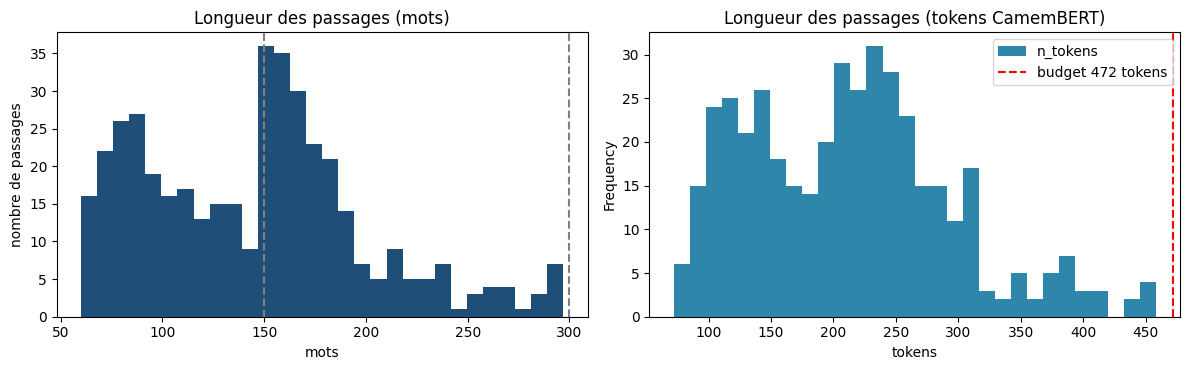

In [11]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(CONFIG["qa_tokenizer"])

budget = CONFIG["qa_max_tokens"] - 40      # 40 tokens réservés à la question et aux tokens spéciaux
def n_tok(t): return len(tok(t, add_special_tokens=False)["input_ids"])

df_pass["n_tokens"] = [n_tok(t) for t in df_pass["texte"]]
print(f"Tokens par mot (moyenne) : {(df_pass['n_tokens'] / df_pass['n_mots']).mean():.2f}")
print(f"Passages au-delà de {budget} tokens avant correction : "
      f"{(df_pass['n_tokens'] > budget).sum()} / {len(df_pass)}")

def scinder(rec):
    # Coupe un passage trop long en deux moitiés équilibrées, sur une frontière de phrase.
    if rec["n_tokens"] <= budget:
        return [rec]
    ph = decouper_phrases(rec["texte"])
    if len(ph) < 2:                       # une seule (très longue) phrase : on coupe au milieu des mots
        mots = rec["texte"].split()
        ph = [" ".join(mots[:len(mots) // 2]), " ".join(mots[len(mots) // 2:])]
    cumul = np.cumsum([len(p.split()) for p in ph])
    i = max(1, int(np.searchsorted(cumul, cumul[-1] / 2)))
    morceaux = [" ".join(ph[:i]), " ".join(ph[i:])]
    return [r for m in morceaux
            for r in scinder({**rec, "texte": m, "n_mots": len(m.split()), "n_tokens": n_tok(m)})]

df_pass = pd.DataFrame([r for rec in df_pass.to_dict("records") for r in scinder(rec)])
# Renumérotation des identifiants après la coupe
df_pass["passage_id"] = df_pass["cours_id"] + "_" + \
    df_pass.groupby("cours_id").cumcount().map("{:03d}".format)
assert (df_pass["n_tokens"] <= budget).all()
print(f"Après correction : {len(df_pass)} passages, tous ≤ {budget} tokens "
      f"(max = {df_pass['n_tokens'].max()})")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
df_pass["n_mots"].plot.hist(bins=30, ax=axes[0], color="#1F4E79")
axes[0].axvline(CONFIG["chunk_min_words"], ls="--", c="grey")
axes[0].axvline(CONFIG["chunk_max_words"], ls="--", c="grey")
axes[0].set(title="Longueur des passages (mots)", xlabel="mots", ylabel="nombre de passages")
df_pass["n_tokens"].plot.hist(bins=30, ax=axes[1], color="#2E86AB")
axes[1].axvline(budget, ls="--", c="red", label=f"budget {budget} tokens")
axes[1].set(title="Longueur des passages (tokens CamemBERT)", xlabel="tokens")
axes[1].legend()
plt.tight_layout()
plt.savefig(CONFIG["fig_dir"] / "longueur_passages.png", dpi=150)
plt.show()

**Sauvegarde et récapitulatif.** Les passages sont enregistrés dans `data/processed/passages.jsonl`. C'est **l'unique source** pour toutes les étapes suivantes : le générateur de base, le LLM et le validateur liront tous ces mêmes passages. Cela garantit que la base de référence et le modèle avancé sont comparés **sur les mêmes données**, comme l'exige l'énoncé.

Le tableau ci-dessous est celui qui sera repris dans la section *Données* de l'article : source, taille et répartition.

In [12]:
with open(CONFIG["processed_dir"] / "passages.jsonl", "w", encoding="utf-8") as f:
    for rec in df_pass.to_dict(orient="records"):
        f.write(json.dumps(rec, ensure_ascii=False) + "\n")

recap = (df_pass.groupby("cours_id")
         .agg(n_passages=("passage_id", "count"), mots_moyens=("n_mots", "mean"),
              tokens_max=("n_tokens", "max"), n_sections=("section", "nunique"))
         .round(0).astype(int)
         .join(sources.set_index("id")[["titre", "auteur", "format", "n_pages", "n_mots_nettoye"]]))
recap.loc["Total"] = [recap["n_passages"].sum(), int(df_pass["n_mots"].mean()), df_pass["n_tokens"].max(),
                      recap["n_sections"].sum(), "", "", "", recap["n_pages"].sum(), recap["n_mots_nettoye"].sum()]
recap

,n_passages,mots_moyens,tokens_max,n_sections,titre,auteur,format,n_pages,n_mots_nettoye
cours_id,,,,,,,,,
C1,130,164,452,68,Programmation en langage C,Anne Canteaut (INRIA),polycopié LaTeX,133,23243
C2,81,151,458,51,Le langage C,Patrick Trau,polycopié,71,12452
C3,88,134,383,71,Programmation C,"M. E. Elhdhili, H. Boucetta",polycopié Word,76,13247
C4,34,127,392,34,Programmation en langage C,"M. Qbadou (ENSET Mohammedia), 2022/2023",polycopié Word,68,5663
C5,55,137,448,43,Initiation au langage C,non indiqué,polycopié LaTeX,52,8145
C6,27,114,445,27,Cours de langage C,Jacquelin Charbonnel (CNRS),diapositives,60,3730
Total,415,145,458,294,,,,460,66480


**Exemple de passage**, ce que recevront le générateur et le validateur :

In [13]:
ex = df_pass[df_pass["section"].str.contains("pointeur", case=False)].iloc[0]
print(f"[{ex.passage_id}] section « {ex.section} » — {ex.n_mots} mots, {ex.n_tokens} tokens\n")
print(ex.texte)

[C1_043] section « Notion de pointeur » — 154 mots, 241 tokens

Un pointeur est un objet (Lvalue) dont la valeur est égale à l’adresse d’un autre objet. On déclare un pointeur par l’instruction: où type est le type de l’objet pointé. Cette déclaration déclare un identificateur, nom-du-pointeur, associé à un objet dont la valeur est l’adresse d’un autre objet de type type. L’identificateur nom-du-pointeur est donc en quelque sorte un identificateur d’adresse. Comme pour n’importe quelle Lvalue, sa valeur est modifiable. Même si la valeur d’un pointeur est toujours un entier (éventuellement un entier long), le type d’un pointeur dépend du type de l’objet vers lequel il pointe. Cette distinction est indispensable à l’interprétation de la valeur d’un pointeur. En effet, pour un pointeur sur un objet de type char, la valeur donne l’adresse de l’octet où cet objet est stocké. Par contre, pour un pointeur sur un objet de type int, la valeur donne l’adresse du premier des 4 octets où l’objet e

---
### Bilan des étapes 0 à 3
- 6 supports de cours PDF sur le langage C, de 6 auteurs différents. Les sources sont citées dans `data/raw/sources.csv`.
- Le texte est extrait et réparé (accents LaTeX, ligatures, espaces). Le code source, les sommaires, les en-têtes et les exercices sont retirés, et chaque règle est comptée.
- Les passages font 150 à 300 mots, sans traverser deux sections. Leur compatibilité avec la limite de 512 tokens de CamemBERT est vérifiée.
- `data/processed/passages.jsonl` est la base commune à la base de référence (étape 4) et au LLM (étape 5).

On passe maintenant à l'étape 4 : la base de référence.

---
# Étape 4 — Base de référence : questions à trous et distracteurs par embeddings

**À quoi sert cette étape ?** L'énoncé exige *une base de référence simple et au moins un modèle avancé, comparés sur les mêmes données avec la même métrique*. La base de référence est le **point de comparaison** : sans elle, on ne peut pas dire si le LLM de l'étape 5 apporte quelque chose. Par exemple, « 70 % des QCM du LLM sont valides » ne veut rien dire seul. « 70 % contre 30 % pour une méthode simple », si.

**La méthode retenue : la question à trous (*cloze*)**, l'approche historique de la génération automatique de QCM (Mitkov et Ha, 2003) :
1. on choisit dans le passage un **terme clé** (la future bonne réponse) ;
2. on prend une **phrase** du passage qui contient ce terme et on remplace le terme par `_____` ;
3. on choisit **trois distracteurs** : des termes du cours *proches par le sens* du terme clé, mais différents.

> Exemple : « Il est parfois utile de passer une fonction comme `_____` d'une autre fonction. » → **paramètre** ✔, plus trois distracteurs.

**Pourquoi cette méthode, et pas un petit modèle de langage ?** La base doit être **simple, sans LLM et transparente**. Chaque décision (quel mot retirer, quels distracteurs choisir) est une règle qu'on peut expliquer. On mesure ainsi ce que l'**intelligence du LLM** apporte, et pas seulement l'écart entre deux LLM.

**Ses limites, connues d'avance**, que la comparaison devra confirmer :
- elle ne teste que la **mémorisation mot à mot** d'une phrase du cours, jamais la compréhension ;
- la phrase est sortie de son contexte et peut être ambiguë ;
- les distracteurs sont choisis sans comprendre la phrase et peuvent ne pas s'y insérer grammaticalement, ou être en réalité corrects.

## 4.1 Échantillon commun de passages

**À quoi ça sert ?** On ne génère pas de QCM sur tous les passages : on fixe un **échantillon commun** de **20 passages par cours, soit 120 passages**. La base de référence **et** le LLM généreront un QCM sur **chacun de ces mêmes passages**, et le validateur les traitera tous.

**Pourquoi un échantillon, et pourquoi celui-ci ?**
- **Coût.** Sur un GPU T4, le LLM met plusieurs secondes par QCM. 120 QCM, c'est faisable en quelques minutes ; plus de 400, ce serait beaucoup plus long sans apporter plus d'information.
- **Comparaison juste.** Les mêmes passages pour les deux méthodes : une différence de qualité ne peut pas venir d'une différence de passages.
- **20 par cours, et non un tirage global.** C1 a environ 130 passages et C6 moins de 30 : un tirage global serait dominé par C1. Avec 20 par cours, on peut comparer les cours entre eux (polycopié contre diapositives).
- **Au moins 80 mots par passage.** En dessous, il y a trop peu de matière pour une question et trois distracteurs, quelle que soit la méthode.
- **Graine fixée** : le même échantillon à chaque exécution.

L'évaluation humaine de l'étape 9 portera sur 60 QCM tirés parmi ceux générés sur cet échantillon.

In [14]:
CONFIG.update({"n_passages_par_cours": 20, "min_mots_passage_qcm": 80})

echantillon = (pd.concat([g.sample(min(CONFIG["n_passages_par_cours"], len(g)), random_state=CONFIG["seed"])
                          for _, g in df_pass[df_pass["n_mots"] >= CONFIG["min_mots_passage_qcm"]]
                          .groupby("cours_id")])
               .sort_values("passage_id").reset_index(drop=True))
echantillon[["passage_id", "cours_id", "section", "n_mots"]].to_csv(
    CONFIG["processed_dir"] / "echantillon.csv", index=False)
print(f"{len(echantillon)} passages dans l'échantillon commun")
echantillon["cours_id"].value_counts().sort_index().to_frame("n_passages").T

120 passages dans l'échantillon commun


cours_id,C1,C2,C3,C4,C5,C6
n_passages,20,20,20,20,20,20


## 4.2 Choix de la bonne réponse : les termes clés par TF-IDF

**À quoi ça sert ?** Trouver dans chaque passage les termes qui le **caractérisent**, c'est-à-dire les notions importantes à faire réviser.

**Pourquoi TF-IDF ?** Le score TF-IDF d'un terme est élevé s'il est **fréquent dans le passage** (TF) mais **rare dans les autres passages** (IDF). « fonction » apparaît partout et a un score faible. « arithmétique des pointeurs » est concentré dans quelques passages et a un score élevé : c'est une notion clé. La méthode est rapide, déterministe et explicable.

**Réglages, et pourquoi :**
- `ngram_range=(1, 2)` : on accepte aussi des termes de deux mots (« bloc dynamique », « fichier source »), fréquents dans un cours technique ;
- `min_df=3` : un terme présent dans moins de 3 passages est souvent un artefact d'extraction ou un mot isolé. Il est écarté, ce qui sert aussi de vivier de distracteurs propres ;
- `max_df=0.3` : un terme présent dans plus de 30 % des passages est trop général pour être une notion clé (« programme », « variable ») ;
- `sublinear_tf=True` : la fréquence est amortie (1 + log tf), pour qu'un mot répété 10 fois ne domine pas tout ;
- **liste de mots vides française** : scikit-learn n'en fournit pas pour le français. On en écrit une, enrichie de mots trop génériques pour être des réponses (« exemple », « permet », « valeur »). Un terme ne peut ni commencer ni finir par un mot vide.

**Pourquoi pas KeyBERT ou un extracteur par embeddings ?** Ils sont plus lourds et moins transparents. Pour une base de référence, TF-IDF est le choix classique, et il suffit.

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

MOTS_VIDES = set('''a à au aux avec ce ces cet cette ceci cela celle celui celles ceux c ça car comme dans de des du d
elle elles en et est être été étant eux il ils je j la le les leur leurs l lui ma mais me même mes moi mon ne n
nos notre nous on ou où par pas pour qu que qui quel quelle quels quelles s sa sans se ses si son sont sur ta te
tes toi ton tu un une unes uns vos votre vous y ont avait sera peut peuvent doit doivent fait faire alors ainsi
aussi autre autres bien chaque donc dont entre ici là lors plus moins non oui sous tout tous toute toutes très
trop deux trois premier première exemple suivant suivante suivants suivantes cas façon manière permet permettent
utilisé utilisée utilisés utiliser utilise également partie fois effet ci après avant ensuite noter cependant
toujours jamais souvent certains certaines plusieurs simple simplement ceux-ci celle-ci celui-ci voici voilà
nombre valeur valeurs'''.split())
RE_TOKEN = r"(?u)\b[a-zA-ZÀ-ÿ][a-zA-ZÀ-ÿ0-9_\-]+\b"

def terme_valide(t: str) -> bool:
    mots = t.split()
    return (mots[0] not in MOTS_VIDES and mots[-1] not in MOTS_VIDES
            and all(len(m) >= 4 for m in mots))

tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), token_pattern=RE_TOKEN,
                        min_df=3, max_df=0.3, sublinear_tf=True)
X_tfidf = tfidf.fit_transform(df_pass["texte"])
vocab = np.array(tfidf.get_feature_names_out())
ligne_de = {pid: i for i, pid in enumerate(df_pass["passage_id"])}

def termes_cles(passage_id: str, k: int = 15) -> list[str]:
    # Les k termes valides de plus fort score TF-IDF dans le passage
    scores = X_tfidf[ligne_de[passage_id]].toarray().ravel()
    out = []
    for j in scores.argsort()[::-1]:
        if scores[j] == 0 or len(out) >= k:
            break
        if terme_valide(vocab[j]):
            out.append(vocab[j])
    return out

ex = echantillon[echantillon["section"].str.contains("pointeur", case=False)].iloc[0]
print(f"Vocabulaire TF-IDF : {len(vocab)} termes")
print(f"Termes clés de {ex.passage_id} (section « {ex.section} ») :", termes_cles(ex.passage_id, 8))

Vocabulaire TF-IDF : 4957 termes
Termes clés de C1_044 (section « Notion de pointeur ») : ['objet adresse', 'objet', 'affectation', 'adresse', 'programmes', 'vers', 'chacun', 'type objet']


## 4.3 Choix des distracteurs : similarité d'embeddings

**À quoi ça sert ?** Un bon distracteur est **plausible** : il appartient au même domaine et ressemble à la bonne réponse, mais il est faux. Pour « paramètre », « variable locale » est plausible, « photosynthèse » ne l'est pas.

**Le vivier de candidats** : les 10 meilleurs termes TF-IDF de **chaque** passage du corpus. Ce sont tous des termes du cours de C, déjà filtrés. On ne tire jamais un distracteur hors du domaine.

**Le choix parmi le vivier** : on représente chaque terme par un **embedding**, un vecteur qui encode le sens. On retient les candidats dont le vecteur est le plus proche de celui de la bonne réponse (similarité cosinus).

**Pourquoi le modèle `paraphrase-multilingual-MiniLM-L12-v2` ?**
- **Multilingue, français inclus**, et entraîné sur des paraphrases : deux expressions de même sens ont des vecteurs proches ;
- **petit** (118 M de paramètres) : il tourne en quelques secondes, même sans GPU ;
- il encode aussi les **termes de plusieurs mots**, contrairement à word2vec ou fastText, qui donnent un vecteur par mot. Le modèle fastText français pèse en plus environ 7 Go.

**Filtres, chacun contre un défaut observé lors de nos essais :**

| Filtre | Défaut évité |
|---|---|
| similarité < 0,85 | un quasi-synonyme serait **aussi une bonne réponse** |
| pas la même famille de mots (5 premières lettres différentes) | `arrêt` contre `arrêté`, `retourne` contre `retournée` : trop faciles à éliminer, ou équivalents |
| même nombre de mots que la réponse | une option de deux mots parmi des options d'un mot se repère sans rien savoir |
| même classe grammaticale approchée (terminaison : *-ment*, *-é/-ée*, *-er/-ir*, *-ent*, sinon nom) | un verbe proposé à la place d'un nom ne s'insère pas dans la phrase |
| absent de la phrase à trous | un distracteur déjà présent dans la phrase serait éliminé d'office |

La classe grammaticale par terminaison est une **approximation volontairement grossière**. Un étiqueteur morphosyntaxique (spaCy) serait plus juste, mais ajouterait une dépendance lourde pour une base qui doit rester simple. C'est une limite de la base de référence.

In [16]:
from sentence_transformers import SentenceTransformer

CONFIG.update({"emb_model": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
               "dist_sim_max": 0.85})
emb_model = SentenceTransformer(CONFIG["emb_model"])

vivier = sorted({t for pid in df_pass["passage_id"] for t in termes_cles(pid, 10)})
E_vivier = emb_model.encode(vivier, normalize_embeddings=True, batch_size=128, show_progress_bar=False)
print(f"Vivier de distracteurs : {len(vivier)} termes du cours")

def famille(t: str) -> set:
    return {m.lower()[:5] for m in t.split()}           # préfixe de 5 lettres ≈ même famille de mots

def classe_gram(t: str) -> str:
    # Classe grammaticale approchée par la terminaison du dernier mot
    w = t.split()[-1].lower()
    for nom, motif in [("adverbe", r"ment$"), ("participe", r"(é|ée|és|ées)$"),
                       ("infinitif", r"(er|ir)$"), ("verbe_pluriel", r"ent$")]:
        if re.search(motif, w):
            return nom
    return "nom"

def choisir_distracteurs(reponse: str, phrase: str, k: int = 3) -> list[str]:
    e = emb_model.encode([reponse], normalize_embeddings=True)[0]
    sims = E_vivier @ e                                   # similarité cosinus (vecteurs normalisés)
    choix = []
    for j in sims.argsort()[::-1]:                        # du plus proche au plus éloigné
        c = vivier[j]
        if (sims[j] >= CONFIG["dist_sim_max"]
                or famille(c) & famille(reponse)
                or len(c.split()) != len(reponse.split())
                or classe_gram(c) != classe_gram(reponse)
                or c in phrase.lower()
                or any(famille(c) & famille(d) for d in choix)):
            continue
        choix.append(c)
        if len(choix) == k:
            break
    return choix

print("Distracteurs pour « paramètre » :", choisir_distracteurs("paramètre", ""))
print("Distracteurs pour « allocation dynamique » :", choisir_distracteurs("allocation dynamique", ""))

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Vivier de distracteurs : 1539 termes du cours
Distracteurs pour « paramètre » : ['niveau', 'évalue', 'analyse']
Distracteurs pour « allocation dynamique » : ['variables automatiques', 'fonction appelante', 'opérations arithmétiques']


## 4.4 Génération des QCM de la base de référence

**Choix de la phrase à trous.** Pour chaque passage, on parcourt les termes clés du meilleur au moins bon. Pour chacun, on cherche une phrase **propre** du passage qui le contient :
- **8 à 35 mots** : assez de contexte, sans que la question devienne illisible ;
- **commence par une majuscule et finit par un point** : c'est une vraie phrase, pas un morceau mal découpé ;
- **aucun reste de code** (`;`, `{`, `=`, `_`, `\`) : la suppression du code à l'étape 2 laisse parfois des phrases tronquées ;
- **le terme y apparaît une seule fois et pas en premier mot** : sinon la réponse resterait visible ailleurs dans la phrase.

Le premier couple (terme, phrase) qui obtient 3 distracteurs donne le QCM. Si aucun ne convient, le passage n'a pas de QCM de base, et on **compte ces échecs** par cause.

**Format de sortie**, identique pour toutes les méthodes (base et LLM) afin que le validateur les traite de la même façon : `qcm_id`, `methode`, `passage_id`, `cours_id`, `question`, `options` (4), `index_correct`, `reponse`. Les options sont **mélangées** avec une graine dépendant du passage. Sinon, la bonne réponse serait toujours en A, et c'est reproductible.

In [17]:
def phrase_propre(p: str) -> bool:
    return (8 <= len(p.split()) <= 35 and p[0].isupper() and p.rstrip().endswith((".", "!", "?"))
            and not re.search(r"[;_\\{}=]", p))

def melanger(options: list, cle: str) -> list:
    options = list(options)
    random.Random(f"{CONFIG['seed']}-{cle}").shuffle(options)
    return options

def qcm_base(passage) -> tuple[dict | None, str]:
    # Renvoie (qcm, "ok") ou (None, cause de l'échec)
    phrases = [p for p in decouper_phrases(passage.texte) if phrase_propre(p)]
    if not phrases:
        return None, "aucune phrase propre"
    terme_trouve = False
    for terme in termes_cles(passage.passage_id):
        for ph in phrases:
            occ = list(re.finditer(r"(?<![\wÀ-ÿ])" + re.escape(terme) + r"(?![\wÀ-ÿ])", ph, flags=re.I))
            if len(occ) != 1 or occ[0].start() == 0:
                continue
            terme_trouve = True
            dis = choisir_distracteurs(terme, ph)
            if len(dis) < 3:
                continue
            m = occ[0]
            reponse = ph[m.start():m.end()]               # forme exacte du texte (majuscules)
            options = melanger([reponse] + dis, passage.passage_id)
            return {"qcm_id": f"BASE_{passage.passage_id}", "methode": "base",
                    "passage_id": passage.passage_id, "cours_id": passage.cours_id,
                    "question": f"Complétez la phrase : « {ph[:m.start()]}_____{ph[m.end():]} »",
                    "options": options, "index_correct": options.index(reponse),
                    "reponse": reponse}, "ok"
    return None, ("pas 3 distracteurs valides" if terme_trouve else "aucun terme clé dans une phrase propre")

resultats = [qcm_base(p) for p in echantillon.itertuples()]
qcm_base_list = [q for q, _ in resultats if q]
causes = pd.Series([c for _, c in resultats], name="résultat")

with open(CONFIG["qcm_dir"] / "qcm_base.jsonl", "w", encoding="utf-8") as f:
    for q in qcm_base_list:
        f.write(json.dumps(q, ensure_ascii=False) + "\n")

print(f"QCM de base produits : {len(qcm_base_list)} / {len(echantillon)} passages "
      f"({100 * len(qcm_base_list) / len(echantillon):.0f} %)\n")
pd.crosstab(echantillon["cours_id"], causes, margins=True, margins_name="Total")

QCM de base produits : 97 / 120 passages (81 %)



résultat,aucune phrase propre,ok,Total
cours_id,,,
C1,1,19,20
C2,1,19,20
C3,0,20,20
C4,2,18,20
C5,2,18,20
C6,17,3,20
Total,23,97,120


**Exemples.** On affiche quelques QCM tirés au hasard (graine fixe), avec la bonne réponse marquée ✔.

In [18]:
def afficher_qcm(q: dict) -> None:
    print(f"[{q['qcm_id']}] {q['question']}")
    for k, o in enumerate(q["options"]):
        print(f"    {'ABCD'[k]}) {o}{'  ✔' if k == q['index_correct'] else ''}")
    print()

for q in random.Random(CONFIG["seed"]).sample(qcm_base_list, 6):
    afficher_qcm(q)

[BASE_C5_014] Complétez la phrase : « Les opérateurs classiques de _____ sont implémentés dans le langage. »
    A) similaire
    B) comparaison  ✔
    C) correspond
    D) équivalentes

[BASE_C1_097] Complétez la phrase : « Ici, il faut préciser par exemple que ces fichiers dépendent aussi de _____.h. »
    A) existe
    B) précisant
    C) produit  ✔
    D) procède

[BASE_C1_011] Complétez la phrase : « Un objet de type int est représenté par un mot “naturel” de la machine utilisée, 32 _____ pour un DEC alpha ou un PC Intel. »
    A) bits  ✔
    B) bit-à-bit
    C) binaires
    D) octets

[BASE_C6_014] Complétez la phrase : « Ecrire un programme de tri: les objets à _____ sont des entiers stockés dans une zone de mémoire allouée dynamiquement. »
    A) trier  ✔
    B) désigner
    C) alléger
    D) parcourir

[BASE_C2_069] Complétez la phrase : « La fonction rend un entier positif dont on se servira par la suite pour accéder au fichier (HANDLE), ou −1 en cas d'_____. »
    A) erreur 

## 4.5 Premier regard sur la base de référence

Ces observations qualitatives sont des **hypothèses**. Elles seront mesurées par le validateur (étapes 7-8) et par l'évaluation humaine (étape 9) :
- **Couverture** : la base ne produit pas de QCM pour tous les passages, et la cause est presque toujours l'absence de phrase propre. Les échecs se concentrent sur les **diapositives (C6)** : écrites en style télégraphique (listes, fragments sans point final), elles n'offrent presque aucune phrase complète à transformer en question à trous. Une méthode par règles dépend de la forme du texte ; on verra si le LLM, qui peut reformuler, s'en sort mieux sur C6.
- **Type de question** : toujours une question à trous, qui ne vérifie que la mémorisation d'une phrase.
- **Distracteurs** : souvent du bon domaine (termes du cours de C), mais choisis sans comprendre la phrase. Certains ne s'y insèrent pas grammaticalement, d'autres pourraient être corrects (le validateur V3 devra les repérer).

C'est exactement le point de comparaison voulu pour le LLM, qui devra produire des questions de compréhension et des distracteurs cohérents avec la phrase.

---
### Bilan de l'étape 4
- Échantillon commun de **120 passages** (20 par cours), enregistré dans `data/processed/echantillon.csv`.
- Base de référence sans LLM : terme clé par TF-IDF, phrase à trous, distracteurs par embeddings multilingues filtrés.
- QCM enregistrés dans `outputs/qcm/qcm_base.jsonl`, au format commun à toutes les méthodes.

On passe maintenant à l'étape 5 : le modèle avancé.

---
# Étape 5 — Modèle avancé : LLM ouvert (prompt few-shot, sortie JSON)

**À quoi sert cette étape ?** Générer un QCM complet (question, bonne réponse, 3 distracteurs) sur **chacun des 120 passages de l'échantillon commun**, avec un modèle de langage ouvert. Ce sont les mêmes passages que pour la base de référence, enregistrés dans le même format, pour une comparaison directe.

Le choix d'un LLM plutôt que d'un modèle seq2seq fine-tuné est justifié en tête du notebook : les jeux FQuAD et PIAF n'ont pas de distracteurs, il n'existe pas de corpus de QCM en français, et un LLM produit de meilleurs distracteurs.

## 5.1 Choix du modèle : Qwen3-4B-Instruct-2507, quantifié en 4 bits

Le projet a d'abord été écrit pour **Qwen2.5-7B-Instruct** (décembre 2024). Les petits modèles sortis depuis font mieux pour deux fois moins de poids, et aucun QCM du LLM n'était encore généré : le changement ne coûte donc rien. La comparaison complète des candidats, licences et sources est dans **`docs/llm/CHOIX_MODELE.md`**.

| Critère | Qwen3-4B-Instruct-2507 | Pourquoi c'est important ici |
|---|---|---|
| Licence | Apache 2.0, **sans formulaire d'accès** | le notebook reste exécutable par n'importe qui, y compris le correcteur |
| Taille | 4,0 milliards de paramètres (3,6 hors embeddings) | ~2,5 Go en 4 bits, contre ~4,2 Go pour un 7 B : marge pour le batch |
| Français | multilingue, gains annoncés sur les langues peu dotées | cours et QCM en français |
| Sortie structurée | mode **non-thinking** : pas de bloc `<think>` à filtrer, JSON direct | un JSON invalide est un QCM perdu (compté en 5.5) |
| Contexte | 262 144 tokens | passage (≤ 460 tokens) + prompt few-shot, large marge |
| Résultats annoncés | MMLU-Pro 69,6 ; GPQA 62,0 ; MMLU-ProX 61,6 ; INCLUDE 60,1 | supérieurs à Qwen2.5-7B pour ~55 % de poids |

**Pourquoi pas un modèle encore plus petit ?** Un 1,7 B (Qwen3-1.7B) suffit pour tester le prompt et le parsing (`QCM_LLM_N=5`), mais produit des QCM plus pauvres. Les modèles de 3 B restent des candidats crédibles : **SmolLM3-3B** (Apache 2.0, français natif, *thinking* désactivable) sert d'ablation francophone, et **Gemma 3 4B IT** est écarté par défaut parce que sa licence (Gemma Terms) n'est pas OSI.

**Pourquoi pas un modèle à experts (Qwen3-30B-A3B) ?** Il calcule moins de FLOPs par token, mais ses 30 milliards de paramètres occupent ~18 Go en 4 bits : il ne tient pas sur une T4 de 15 Go sans déport CPU, donc il serait plus lent ici.

**Pourquoi quantifier en 4 bits (bitsandbytes, NF4) ?** En 16 bits, 4 milliards de paramètres occupent ~8 Go, et 7 milliards ~15 Go, soit toute la mémoire d'une T4. En 4 bits, Qwen3-4B tient dans ~2,5 Go, avec une perte de qualité faible d'après la littérature sur la quantification NF4 (QLoRA, Dettmers et al., 2023).

**Exécution et cache.** Le LLM tourne sur GPU (Colab). Ses sorties sont **mises en cache** dans `outputs/qcm/qcm_llm.jsonl` : une fois générées, les exécutions suivantes les relisent au lieu de relancer le calcul. Chaque QCM enregistre son champ `modele` ; un cache produit par un autre modèle est **refusé** plutôt que réutilisé silencieusement. Pour comparer deux modèles sans mélanger leurs sorties, on donne un fichier de cache distinct :

```bash
QCM_LLM_MODEL=HuggingFaceTB/SmolLM3-3B QCM_LLM_CACHE=outputs/qcm/qcm_llm_smollm3.jsonl
```

Variables reconnues : `QCM_LLM_MODEL`, `QCM_LLM_CACHE`, `QCM_LLM_BRUT`, `QCM_LLM_N`, `QCM_ALLOW_CPU`.


## 5.2 Le prompt : consignes, exemples (*few-shot*) et format JSON

**Consignes système.** Chaque règle répond à un défaut connu des QCM générés, observé dans la littérature ou lors de nos essais, et prépare un test du validateur :

| Consigne | Défaut évité | Test du validateur lié |
|---|---|---|
| Répondable **uniquement** avec le passage | question sur des connaissances extérieures | V1 répondabilité |
| **Une seule** bonne réponse, justifiée par le passage | deux options correctes | V2 unicité |
| 3 distracteurs **faux d'après le passage** mais plausibles | distracteur en réalité vrai | V3 distracteurs faux |
| Pas de « toutes / aucune des réponses », pas de question négative | options impossibles à valider automatiquement | contrôles de forme (étape 6) |
| Question de **compréhension**, pas recopie d'une phrase | simple question à trous, comme la base | évaluation humaine |
| Options courtes et de même forme | la bonne réponse se repère à sa longueur | contrôles de forme |
| La question se comprend **seule** (pas de « d'après le passage », « l'exemple précédent ») | l'étudiant ne voit pas le passage : la question doit être autonome | contrôles de forme |

**Pourquoi des exemples (*few-shot*) ?** Deux exemples complets (passage, puis QCM attendu en JSON) montrent au modèle le format exact et le niveau d'exigence attendus. C'est plus efficace qu'une longue description. Les deux passages d'exemple ont été **rédigés par nous** et ne viennent pas du corpus, pour qu'aucun passage évalué n'apparaisse dans le prompt.

**Pourquoi une sortie JSON ?** On peut la lire automatiquement : chaque champ (question, bonne réponse, distracteurs) arrive à sa place, sans analyser du texte libre. On demande aussi une **justification**, la phrase du passage qui prouve la bonne réponse. Elle sert à l'analyse des erreurs et à l'évaluation humaine. Le validateur ne s'y fie **pas** : c'est une affirmation du modèle, que le validateur doit vérifier par lui-même.

In [19]:
PROMPT_SYSTEME = '''Tu es un enseignant de programmation en langage C. Tu rédiges des questions à choix multiples (QCM) d'examen à partir d'un extrait de cours.

Règles :
1. La question doit pouvoir être résolue UNIQUEMENT avec les informations du passage.
2. Il y a UNE SEULE bonne réponse, et le passage la justifie explicitement.
3. Il y a exactement 3 distracteurs : plausibles pour un étudiant qui n'a pas compris (même thème, même forme que la bonne réponse), mais FAUX d'après le passage.
4. Interdit : « toutes les réponses », « aucune des réponses », questions négatives (« laquelle n'est pas… »).
5. Préfère une question de compréhension à la simple recopie d'une phrase du passage.
6. Options courtes (moins de 15 mots), de longueur et de forme comparables.
7. La question se comprend seule : elle ne mentionne jamais « le passage », « le texte », « l'exemple précédent » ni « ce contexte ».
8. Tout est rédigé en français.

Réponds UNIQUEMENT avec un objet JSON valide, sans texte autour, de la forme :
{"question": "...", "bonne_reponse": "...", "distracteurs": ["...", "...", "..."], "justification": "phrase du passage qui justifie la bonne réponse"}'''

# Exemples rédigés par le groupe (hors corpus) : ils fixent le format et le niveau attendus
EXEMPLES = [
    ("La boucle do...while exécute d'abord le bloc d'instructions, puis évalue la condition. Le corps de "
     "la boucle est donc toujours exécuté au moins une fois, contrairement à la boucle while, qui teste la "
     "condition avant chaque itération. La boucle se termine dès que la condition devient fausse, "
     "c'est-à-dire égale à zéro.",
     {"question": "Quelle propriété distingue la boucle do...while de la boucle while ?",
      "bonne_reponse": "Son corps est toujours exécuté au moins une fois",
      "distracteurs": ["Sa condition est évaluée avant chaque itération",
                       "Elle s'arrête dès que la condition devient vraie",
                       "Son corps n'est exécuté que si la condition est fausse"],
      "justification": "Le corps de la boucle est donc toujours exécuté au moins une fois, contrairement à la boucle while."}),
    ("L'opérateur sizeof renvoie la taille, en octets, d'un type ou d'un objet. Cette taille dépend de la "
     "machine : un int occupe souvent 4 octets, mais la norme garantit seulement qu'un char occupe exactement "
     "1 octet. Comme sizeof est évalué à la compilation, l'expression qu'on lui passe n'est pas exécutée.",
     {"question": "D'après la norme du C, quel type a une taille garantie d'exactement 1 octet ?",
      "bonne_reponse": "char",
      "distracteurs": ["int", "short", "float"],
      "justification": "la norme garantit seulement qu'un char occupe exactement 1 octet."}),
]

def construire_messages(passage: str) -> list[dict]:
    msgs = [{"role": "system", "content": PROMPT_SYSTEME}]
    for texte, qcm in EXEMPLES:
        msgs.append({"role": "user", "content": f"Passage :\n« {texte} »\n\nRédige un QCM sur ce passage."})
        msgs.append({"role": "assistant", "content": json.dumps(qcm, ensure_ascii=False)})
    msgs.append({"role": "user", "content": f"Passage :\n« {passage} »\n\nRédige un QCM sur ce passage."})
    return msgs

print(construire_messages("…texte du passage…")[-1]["content"])

Passage :
« …texte du passage… »

Rédige un QCM sur ce passage.


## 5.3 Lecture et vérification de la sortie JSON

**À quoi ça sert ?** Le LLM ne garantit pas un JSON parfait : texte autour de l'objet, guillemets mal fermés, nombre de distracteurs incorrect… On extrait le premier objet `{…}` de la réponse, puis on vérifie sa **structure** : question non vide, une bonne réponse, exactement 3 distracteurs distincts et différents de la bonne réponse.

Si la sortie est invalide, on fait **une seule nouvelle tentative**, avec un échantillonnage léger (température 0,7) et une graine fixée, pour obtenir une sortie différente. Si elle échoue aussi, le passage n'a pas de QCM LLM. On **compte** ces échecs : le taux de JSON valide est une mesure de fiabilité du générateur, à rapporter dans l'article.

**Pourquoi un décodage glouton (`do_sample=False`) au premier essai ?** Il est **déterministe** (même entrée, même sortie, donc reproductible) et produit les sorties les plus probables, en général les mieux formées. L'effet de la température sur la diversité et la qualité sera étudié dans les ablations (étape 10).

In [20]:
def lire_json(texte: str):
    # Extrait et vérifie le QCM ; renvoie (dict, None) si valide, (None, raison) sinon
    m = re.search(r"\{.*\}", texte, flags=re.S)
    if not m:
        return None, "pas d'objet JSON"
    try:
        d = json.loads(m.group(0))
    except json.JSONDecodeError:
        return None, "JSON mal formé"
    if not all(isinstance(d.get(k), str) and d[k].strip() for k in ("question", "bonne_reponse")):
        return None, "champ manquant"
    dis = d.get("distracteurs")
    if not isinstance(dis, list) or len(dis) != 3 or not all(isinstance(x, str) and x.strip() for x in dis):
        return None, "pas exactement 3 distracteurs"
    options = [d["bonne_reponse"].strip()] + [x.strip() for x in dis]
    if len({o.lower() for o in options}) < 4:
        return None, "options en double"
    return d, None

# Test de la fonction sur des sorties typiques
for essai in ['Voici le QCM : {"question": "Q ?", "bonne_reponse": "a", "distracteurs": ["b", "c", "d"]}',
              '{"question": "Q ?", "bonne_reponse": "a", "distracteurs": ["b", "c"]}',
              '{"question": "Q ?", "bonne_reponse": "a", "distracteurs": ["b", "c", "a"]}']:
    print(lire_json(essai)[1] or "valide", "←", essai[:60])

valide ← Voici le QCM : {"question": "Q ?", "bonne_reponse": "a", "di
pas exactement 3 distracteurs ← {"question": "Q ?", "bonne_reponse": "a", "distracteurs": ["
options en double ← {"question": "Q ?", "bonne_reponse": "a", "distracteurs": ["


## 5.4 Chargement du modèle et génération

**Génération par lots (*batch*) de 8 passages.** Le GPU traite plusieurs prompts en parallèle presque aussi vite qu'un seul, donc la génération est environ 5 fois plus rapide qu'un passage à la fois. Les prompts d'un lot ont des longueurs différentes : on les complète **à gauche** (`padding_side="left"`), pour que le texte généré suive directement chaque prompt.

`max_new_tokens=350` : un QCM en JSON fait environ 120 à 200 tokens. La marge évite de couper une sortie, ce qui la rendrait invalide.

Pour chaque QCM, on enregistre aussi la **sortie brute** du modèle (`llm_brut.jsonl`) et le temps de génération. La sortie brute sert à l'analyse des erreurs de format, le temps à la discussion du coût.

In [23]:
import time, torch, os, sys, importlib, json, subprocess
from pathlib import Path

CONFIG.update({
    "llm_model": os.environ.get("QCM_LLM_MODEL", "Qwen/Qwen3-4B-Instruct-2507"),
    "llm_batch": 8,          # un 4 B en 4 bits permet 16 ; 8 reste sûr sur une T4
    "llm_max_new_tokens": 350,
    "llm_temp_relance": 0.7,
})
CACHE_LLM = Path(os.environ.get("QCM_LLM_CACHE", CONFIG["qcm_dir"] / "qcm_llm.jsonl"))
BRUT_LLM = Path(os.environ.get("QCM_LLM_BRUT", CONFIG["qcm_dir"] / "llm_brut.jsonl"))
GPU = torch.cuda.is_available()
# Sans GPU, la génération n'est autorisée que pour tester le code avec un petit modèle
GENERATION_POSSIBLE = GPU or os.environ.get("QCM_ALLOW_CPU") == "1"

def charger_llm(nom: str):
    from transformers import AutoModelForCausalLM, AutoTokenizer
    tok_llm = AutoTokenizer.from_pretrained(nom, padding_side="left")
    if GPU:
        if importlib.util.find_spec("bitsandbytes") is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "bitsandbytes", "accelerate"], check=True)
        from transformers import BitsAndBytesConfig
        quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                   bnb_4bit_compute_dtype=torch.float16)
        modele = AutoModelForCausalLM.from_pretrained(nom, quantization_config=quant, device_map="auto")
    else:
        modele = AutoModelForCausalLM.from_pretrained(nom, dtype=torch.float32)
    modele.eval()
    return tok_llm, modele

@torch.no_grad()
def generer_lot(tok_llm, modele, passages: list[str], echantillonner: bool = False) -> list[str]:
    prompts = [tok_llm.apply_chat_template(construire_messages(p), tokenize=False, add_generation_prompt=True)
               for p in passages]
    entree = tok_llm(prompts, return_tensors="pt", padding=True).to(modele.device)
    options = {"max_new_tokens": CONFIG["llm_max_new_tokens"], "pad_token_id": tok_llm.pad_token_id}
    if echantillonner:
        options.update(do_sample=True, temperature=CONFIG["llm_temp_relance"], top_p=0.95)
    else:
        options.update(do_sample=False)
    sortie = modele.generate(**entree, **options)
    return tok_llm.batch_decode(sortie[:, entree["input_ids"].shape[1]:], skip_special_tokens=True)

def vers_format_commun(passage, d: dict, essai: int, duree: float) -> dict:
    bonne = d["bonne_reponse"].strip()
    options = melanger([bonne] + [x.strip() for x in d["distracteurs"]], passage.passage_id)
    return {"qcm_id": f"LLM_{passage.passage_id}", "methode": "llm",
            "passage_id": passage.passage_id, "cours_id": passage.cours_id,
            "question": d["question"].strip(), "options": options,
            "index_correct": options.index(bonne), "reponse": bonne,
            "justification": str(d.get("justification", "")).strip(),
            "modele": CONFIG["llm_model"],
            "essai": essai, "duree_s": round(duree, 2)}

def sauver_sorties() -> None:
    # Écrit après chaque lot : une coupure de session Colab ne perd pas le travail déjà fait.
    with open(CACHE_LLM, "w", encoding="utf-8") as f:
        for q in qcm_llm_list:
            f.write(json.dumps(q, ensure_ascii=False) + "\n")
    with open(BRUT_LLM, "w", encoding="utf-8") as f:
        for b in bruts:
            f.write(json.dumps({**b, "modele": CONFIG["llm_model"]}, ensure_ascii=False) + "\n")

# --- Reprise : on relit le cache, puis on ne génère que les passages manquants ---------
qcm_llm_list, bruts = [], []
if CACHE_LLM.exists():
    qcm_llm_list = [json.loads(l) for l in open(CACHE_LLM, encoding="utf-8")]
    bruts = [json.loads(l) for l in open(BRUT_LLM, encoding="utf-8")] if BRUT_LLM.exists() else []
    if qcm_llm_list:
        modeles_du_cache = {q.get("modele") for q in qcm_llm_list}
        if modeles_du_cache != {CONFIG["llm_model"]}:
            # Un cache produit par un autre modèle rendrait la comparaison base/LLM invalide.
            raise SystemExit(
                f"Le cache {CACHE_LLM.name} ne correspond pas au modèle demandé.\n"
                f"  cache   : {sorted(m for m in modeles_du_cache if m) or 'modèle non renseigné (ancien format)'}\n"
                f"  demandé : {CONFIG['llm_model']}\n"
                "Renommer ou supprimer ce fichier, ou choisir un cache distinct avec "
                "QCM_LLM_CACHE=... pour comparer deux modèles sans mélanger leurs sorties.")
    print(f"{len(qcm_llm_list)} QCM déjà en cache ({CACHE_LLM.name}, {CONFIG['llm_model']})")

n_max = int(os.environ.get("QCM_LLM_N", len(echantillon)))
deja_faits = {q["passage_id"] for q in qcm_llm_list}
a_traiter = [p for p in echantillon.head(n_max).itertuples() if p.passage_id not in deja_faits]

if not GENERATION_POSSIBLE:
    print(f"⚠ Pas de GPU : {len(a_traiter)} passage(s) resteraient à générer. "
          "Exécuter l'étape 5 sur Colab, ou déposer le cache dans outputs/qcm/.")
elif not a_traiter:
    print(f"Rien à générer : les {len(deja_faits)} passages demandés sont déjà en cache.")
else:
    set_seed(CONFIG["seed"])
    print(f"Modèle : {CONFIG['llm_model']} (cache : {CACHE_LLM.name}) — "
          f"{len(a_traiter)} passage(s) à générer")
    tok_llm, modele = charger_llm(CONFIG["llm_model"])
    t_debut = time.time()
    for i in range(0, len(a_traiter), CONFIG["llm_batch"]):
        lot = a_traiter[i:i + CONFIG["llm_batch"]]
        t0 = time.time()
        textes = generer_lot(tok_llm, modele, [p.texte for p in lot])
        duree = (time.time() - t0) / len(lot)
        for p, txt in zip(lot, textes):
            d, err = lire_json(txt)
            essai = 1
            if d is None:                                   # une seule relance, avec échantillonnage
                set_seed(CONFIG["seed"])
                txt2 = generer_lot(tok_llm, modele, [p.texte], echantillonner=True)[0]
                d, err2 = lire_json(txt2)
                essai = 2
                bruts.append({"passage_id": p.passage_id, "essai": 1, "sortie": txt, "erreur": err})
                txt, err = txt2, err2
            bruts.append({"passage_id": p.passage_id, "essai": essai, "sortie": txt, "erreur": err})
            if d is not None:
                qcm_llm_list.append(vers_format_commun(p, d, essai, duree))
        sauver_sorties()          # après chaque lot : reprise possible si la session tombe
        print(f"  {min(i + CONFIG['llm_batch'], len(a_traiter))}/{len(a_traiter)} passages traités")
    print(f"Génération terminée en {(time.time() - t_debut) / 60:.1f} min "
          f"({len(qcm_llm_list)} QCM en cache)")
    del modele
    if GPU:
        torch.cuda.empty_cache()

115 QCM déjà en cache (qcm_llm.jsonl, Qwen/Qwen3-4B-Instruct-2507)
Modèle : Qwen/Qwen3-4B-Instruct-2507 (cache : qcm_llm.jsonl) — 5 passage(s) à générer


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  5/5 passages traités
Génération terminée en 1.8 min (115 QCM en cache)


## 5.5 Fiabilité du format et exemples

On mesure d'abord la **fiabilité du générateur** : la part des passages qui donnent un QCM exploitable dès le premier essai, après relance, ou jamais. On regarde aussi le temps moyen par QCM.

In [24]:
if qcm_llm_list:
    df_llm = pd.DataFrame(qcm_llm_list)
    n_ech = len({b["passage_id"] for b in bruts}) if bruts else len(echantillon)   # passages soumis au LLM
    fiab = pd.Series({
        "modèle": df_llm["modele"].iloc[0] if "modele" in df_llm else CONFIG["llm_model"],
        "passages traités": n_ech,
        "QCM valides au 1er essai": int((df_llm["essai"] == 1).sum()),
        "QCM valides après relance": int((df_llm["essai"] == 2).sum()),
        "échecs définitifs": n_ech - len(df_llm),
        "temps moyen par QCM (s)": round(df_llm["duree_s"].mean(), 2),
    })
    display(fiab.to_frame("valeur"))
    erreurs = pd.Series([b["erreur"] for b in bruts if b["erreur"]], dtype=str)
    if len(erreurs):
        print("Erreurs de format rencontrées :", erreurs.value_counts().to_dict())
    print()
    for q in random.Random(CONFIG["seed"]).sample(qcm_llm_list, min(6, len(qcm_llm_list))):
        afficher_qcm(q)
        print(f"    justification : {q['justification'][:160]}\n")
else:
    print("Étape 5 non exécutée (pas de GPU ni de cache).")

,valeur
modèle,Qwen/Qwen3-4B-Instruct-2507
passages traités,120
QCM valides au 1er essai,109
QCM valides après relance,6
échecs définitifs,5
temps moyen par QCM (s),7.79


Erreurs de format rencontrées : {'JSON mal formé': 14, 'pas exactement 3 distracteurs': 12}

[LLM_C5_014] Quelle valeur numérique prend une expression de comparaison évaluée à Vrai ?
    A) 0
    B) 1  ✔
    C) 2
    D) n'importe quelle valeur non nulle

    justification : La valeur des expressions correspondantes est de type numérique (0 ou 1) et repose sur la correspondance entre Faux et 0, Vrai et toute valeur différente de 0 (

[LLM_C1_097] Quel fichier est requis pour compiler les fichiers sources produit.c et main.c ?
    A) produit.o
    B) main.o
    C) produit.h  ✔
    D) Makefile

    justification : Ici, il faut préciser par exemple que ces fichiers dépendent aussi de produit.h.

[LLM_C1_011] Quelle est la taille minimale d'un objet de type long int sur un PC Intel ?
    A) 32 bits  ✔
    B) 16 bits
    C) 64 bits
    D) 8 bits

    justification : un int peut être précédé d’un attribut de précision (short ou long) et/ou d’un attribut de représentation (unsigned). Un objet 

## 5.6 Première comparaison automatique avec la base de référence

Avant le validateur et l'évaluation humaine, trois indicateurs simples comparent les deux générateurs sur les mêmes passages :
- **Couverture** : nombre de passages qui obtiennent un QCM, par cours. La base échoue sur les diapositives (C6) ; le LLM fait-il mieux ?
- **Type de question** : le mot interrogatif (quel, que, pourquoi, comment…) ou « complétez » pour la question à trous. On voit si le LLM pose des questions de compréhension.
- **Bonne réponse recopiée mot pour mot du passage ?** Une réponse *extractive* (présente telle quelle dans le texte) se vérifie facilement par un modèle de questions-réponses extractif. Une réponse *reformulée* demandera la comparaison par similarité prévue dans le validateur V2. Cet indicateur prépare donc l'étape 7.

In [26]:
FIN_MOT = r"(?![a-zà-ÿ])"
TYPES_QUESTION = [  # (motif, étiquette) ; "qu'" n'a pas besoin de fin de mot (suivi d'une lettre)
    (r"pourquoi" + FIN_MOT, "pourquoi"), (r"comment" + FIN_MOT, "comment"), (r"combien" + FIN_MOT, "combien"),
    (r"en quoi" + FIN_MOT, "en quoi"), (r"à quoi" + FIN_MOT, "à quoi"),
    (r"(lequel|laquelle|lesquel(le)?s)" + FIN_MOT, "lequel"), (r"quel(le)?s?" + FIN_MOT, "quel(le)"),
    (r"(que" + FIN_MOT + r"|qu['’])", "que / qu'"),
]

def type_question(q: str) -> str:
    # Mot interrogatif qui apparaît EN PREMIER dans la question (« Dans ce cas, quelle… » -> quel(le))
    q = q.lower()
    if q.startswith("complétez"):
        return "à trous"
    positions = [(m.start(), etiquette) for motif, etiquette in TYPES_QUESTION
                 for m in [re.search(r"(?<![\wà-ÿ])" + motif, q)] if m]
    return min(positions)[1] if positions else "autre"

texte_de = dict(zip(df_pass["passage_id"], df_pass["texte"]))
lignes_cmp = []
for nom, liste in [("base", qcm_base_list), ("llm", qcm_llm_list)]:
    for q in liste:
        lignes_cmp.append({"methode": nom, "cours_id": q["cours_id"], "type": type_question(q["question"]),
                           "reponse_extractive": q["reponse"].lower() in texte_de[q["passage_id"]].lower(),
                           "mots_question": len(q["question"].split())})
df_cmp = pd.DataFrame(lignes_cmp)

print("Couverture (QCM produits sur 20 passages par cours) :")
display(pd.crosstab(df_cmp["cours_id"], df_cmp["methode"], margins=True, margins_name="Total"))
print("Type de question (%) :")
display((pd.crosstab(df_cmp["type"], df_cmp["methode"], normalize="columns") * 100).round(0))
print("Bonne réponse présente mot pour mot dans le passage (%) :")
display((df_cmp.groupby("methode")["reponse_extractive"].mean() * 100).round(0).to_frame("%"))

Couverture (QCM produits sur 20 passages par cours) :


methode,base,llm,Total
cours_id,,,
C1,19,20,39
C2,19,19,38
C3,20,17,37
C4,18,20,38
C5,18,19,37
C6,3,20,23
Total,97,115,212


Type de question (%) :


methode,base,llm
type,,
autre,0.0,1.0
comment,0.0,3.0
pourquoi,0.0,11.0
quel(le),0.0,85.0
à trous,100.0,0.0


Bonne réponse présente mot pour mot dans le passage (%) :


,%
methode,
base,100.0
llm,51.0


---
### Bilan de l'étape 5
- LLM ouvert **Qwen2.5-7B-Instruct** quantifié en 4 bits. Prompt avec 6 consignes, 2 exemples rédigés hors corpus et sortie JSON avec justification.
- Lecture robuste du JSON, une relance en cas d'échec, taux de format valide mesuré.
- QCM dans `outputs/qcm/qcm_llm.jsonl`, au même format que la base. Sorties brutes dans `llm_brut.jsonl`, pour l'analyse des erreurs.
- Première comparaison automatique avec la base : couverture, type de question, réponses extractives.

On passe maintenant à l'étape 6 : les contrôles de forme.

---
# Étape 6 — Contrôles de forme

**À quoi sert cette étape ?** Avant les tests sémantiques du validateur (étape 7), on écarte les QCM qui ont un **défaut de structure**, visible sans comprendre le sens. Par exemple : deux options identiques, « toutes les réponses » parmi les choix, ou une bonne réponse qu'on repère à sa longueur. Ces défauts suffisent à rendre un QCM inutilisable, quel que soit son contenu.

**Pourquoi des règles, et pas un modèle ?** Ces défauts sont **structurels et définis sans ambiguïté**. Une règle les détecte avec certitude, instantanément, et chaque rejet s'explique en une phrase. Les modèles (questions-réponses, NLI) sont réservés à ce qu'une règle ne peut pas juger : le *sens* (étape 7). Filtrer la forme d'abord évite aussi de dépenser du calcul GPU sur des QCM déjà inutilisables.

**Pourquoi rejeter plutôt que corriger ?** On veut **mesurer la qualité des générateurs**. Corriger automatiquement (par exemple raccourcir une option trop longue) masquerait leurs défauts et fausserait la comparaison entre la base et le LLM. La correction automatique serait une extension possible, que nous ne faisons pas ici.

**Les règles et leur justification :**

| Règle | Défaut détecté | Pourquoi c'est un problème |
|---|---|---|
| F1 options distinctes | deux options identiques (à la casse et à la ponctuation près), ou une option contenue mot pour mot dans une autre | deux options identiques laissent 3 choix réels ; si « unsigned char » est contenu dans « unsigned char, signed char », les deux options peuvent être justes en même temps |
| F2 pas d'option « méta » | « toutes les réponses », « aucune des réponses », « A et B », « les deux » | ce n'est pas une réponse sur le cours, et le validateur ne peut pas la vérifier dans le texte |
| F3 question non négative | « laquelle n'est **pas**… », « **sauf** », « est **incorrecte** » | une négation est souvent mal lue par l'étudiant, et mal traitée par les modèles de questions-réponses |
| F4 réponse non visible dans la question | la bonne réponse apparaît mot pour mot dans l'énoncé | on répond sans rien savoir |
| F5 question autonome | « d'après le passage », « le texte », « l'exemple précédent » | l'étudiant ne voit pas le passage |
| F6 options courtes et équilibrées | une option de plus de 15 mots, ou une bonne réponse plus de 2 fois plus longue que la moyenne des distracteurs | une option qui se distingue par sa longueur est un indice classique (*test-wiseness*) : le candidat malin choisit la plus longue, la plus détaillée |
| F7 énoncé bien formé | ni point d'interrogation ni trou `_____`, ou énoncé de moins de 4 mots ou de plus de 60 mots | ce n'est pas une question exploitable |

**Détail important pour F3.** La base de référence recopie une phrase du cours entre guillemets « … », et cette phrase peut contenir une négation (« le compilateur ne vérifie pas… »). Ce n'est pas une question négative. On cherche donc la négation **dans la formulation de la question, en dehors du texte cité entre guillemets**. La règle est la même pour les deux méthodes, ce qui garde la comparaison équitable.

In [27]:
import unicodedata as _ud

def normaliser(t: str) -> str:
    # minuscules, sans accents, sans ponctuation : pour comparer deux options « à la forme près »
    t = _ud.normalize("NFD", t.lower())
    t = "".join(c for c in t if _ud.category(c) != "Mn")
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", t)).strip()

def contient_mots(grand: str, petit: str) -> bool:
    # petit apparaît comme suite de mots entiers dans grand
    return bool(petit) and re.search(r"(?<!\w)" + re.escape(petit) + r"(?!\w)", grand) is not None

# « les deux » ou « A et B » ne sont méta que s'ils forment toute l'option (« compare les deux chaînes » est légitime)
RE_META = re.compile(r"\b(toutes? (les|ces) (reponses|propositions|options)|aucune (des|de ces) (reponses|propositions)|"
                     r"ci dessus)\b|^(les deux|a et b|b et c|a et c|a b et c)$")
RE_NEGATIF = re.compile(r"\b(n est pas|ne sont pas|n a pas|ne peut pas|ne doit pas|n y a pas|ne fait pas|"
                        r"sauf|excepte|incorrecte?s?|fausses?|erronee?s?|n est jamais)\b")
RE_REFERENCE = re.compile(r"\b(le passage|ce passage|du passage|le texte|ce texte|du texte|l extrait|cet extrait|"
                          r"ci dessus|exemple precedent|ce contexte|dans le contexte)\b")
F_REGLES = {
    "F1 options distinctes": "deux options identiques ou imbriquées",
    "F2 pas d'option méta": "« toutes / aucune des réponses »…",
    "F3 question non négative": "négation dans la formulation",
    "F4 réponse non visible": "bonne réponse écrite dans la question",
    "F5 question autonome": "référence au passage / au texte",
    "F6 options équilibrées": "option trop longue ou bonne réponse repérable",
    "F7 énoncé bien formé": "ni ? ni trou, ou longueur anormale",
}

def controles_forme(q: dict) -> dict:
    # Renvoie {règle: True si le QCM présente le défaut}
    opts = [normaliser(o) for o in q["options"]]
    bonne = opts[q["index_correct"]]
    dis = [o for k, o in enumerate(opts) if k != q["index_correct"]]
    question_hors_citation = normaliser(re.sub(r"«[^»]*»", " ", q["question"]))
    question = normaliser(q["question"])
    n_mots = [len(o.split()) for o in q["options"]]
    n_bonne, n_dis = n_mots[q["index_correct"]], np.mean([n for k, n in enumerate(n_mots) if k != q["index_correct"]])
    n_q = len(q["question"].split())
    return {
        "F1 options distinctes": len(set(opts)) < 4 or any(
            i != j and contient_mots(opts[i], opts[j]) for i in range(4) for j in range(4)),
        "F2 pas d'option méta": any(RE_META.search(o) for o in opts),
        "F3 question non négative": bool(RE_NEGATIF.search(question_hors_citation)),
        "F4 réponse non visible": len(bonne) >= 4 and contient_mots(question.replace("_____", " "), bonne),
        "F5 question autonome": bool(RE_REFERENCE.search(question_hors_citation)),
        "F6 options équilibrées": max(n_mots) > 15 or (n_bonne > 2 * n_dis and n_bonne - n_dis >= 4),
        "F7 énoncé bien formé": not ("?" in q["question"] or "_____" in q["question"]) or not 4 <= n_q <= 60,
    }

# Tests unitaires des règles sur des QCM fabriqués, un défaut par cas
def _qcm(question, options, bonne=0):
    return {"question": question, "options": options, "index_correct": bonne}
tests = [
    ("F1", _qcm("Quel type stocke un caractère ?", ["unsigned char", "unsigned char, signed char", "int", "float"])),
    ("F2", _qcm("Quel type stocke un caractère ?", ["char", "int", "float", "Toutes les réponses"])),
    ("F3", _qcm("Laquelle de ces fonctions n'est pas standard ?", ["printf", "scanf", "malloc", "getline"])),
    ("F4", _qcm("Que renvoie la fonction malloc ?", ["malloc", "un entier", "un caractère", "rien"])),
    ("F5", _qcm("D'après le passage, que fait free ?", ["libère", "alloue", "copie", "compare"])),
    ("F6", _qcm("Que fait free ?", ["Elle libère la zone mémoire allouée auparavant par malloc ou calloc",
                                     "copie", "trie", "compare"])),
    ("F7", _qcm("free", ["libère", "alloue", "copie", "compare"])),
    ("aucun", _qcm("Complétez la phrase : « Le compilateur ne vérifie pas les _____. »",
                   ["bornes", "types", "noms", "macros"])),
]
for attendu, q in tests:
    detectes = [r.split()[0] for r, v in controles_forme(q).items() if v]
    print(f"{'OK ' if (detectes == [attendu] or (attendu == 'aucun' and not detectes)) else 'ERR'} "
          f"attendu {attendu:5s} → détecté {detectes}")

OK  attendu F1    → détecté ['F1']
OK  attendu F2    → détecté ['F2']
OK  attendu F3    → détecté ['F3']
OK  attendu F4    → détecté ['F4']
OK  attendu F5    → détecté ['F5']
OK  attendu F6    → détecté ['F6']
OK  attendu F7    → détecté ['F7']
OK  attendu aucun → détecté []


**Application aux QCM des deux générateurs.** Chaque QCM reçoit le résultat des 7 règles. `forme_ok` vaut vrai s'il n'en échoue aucune. Le tableau donne, pour chaque règle et chaque méthode, le **pourcentage de QCM en défaut**. Un QCM peut échouer à plusieurs règles à la fois. Le résultat est enregistré dans `outputs/qcm/controles_forme.csv` et sera repris par le filtre final (étape 8).

In [28]:
tous_qcm = qcm_base_list + qcm_llm_list
df_forme = pd.DataFrame([{"qcm_id": q["qcm_id"], "methode": q["methode"], "cours_id": q["cours_id"],
                          **controles_forme(q)} for q in tous_qcm])
regles = list(F_REGLES)
df_forme["forme_ok"] = ~df_forme[regles].any(axis=1)
df_forme.to_csv(CONFIG["qcm_dir"] / "controles_forme.csv", index=False)

synthese = (df_forme.groupby("methode")[regles + ["forme_ok"]].mean() * 100).round(1).T
synthese.columns = [f"% {c}" for c in synthese.columns]
synthese.index = [f"{r} — {F_REGLES[r]}" if r in F_REGLES else "→ QCM conformes (forme_ok)" for r in synthese.index]
print("Pourcentage de QCM en défaut pour chaque règle :")
display(synthese)
print("Nombre de QCM :", df_forme["methode"].value_counts().to_dict())
if not qcm_llm_list:
    print("(QCM du LLM absents : à générer sur Colab, étape 5.)")

Pourcentage de QCM en défaut pour chaque règle :


,% base,% llm
F1 options distinctes — deux options identiques ou imbriquées,1.0,10.4
F2 pas d'option méta — « toutes / aucune des réponses »…,0.0,0.0
F3 question non négative — négation dans la formulation,0.0,1.7
F4 réponse non visible — bonne réponse écrite dans la question,0.0,0.9
F5 question autonome — référence au passage / au texte,0.0,3.5
F6 options équilibrées — option trop longue ou bonne réponse repérable,0.0,5.2
"F7 énoncé bien formé — ni ? ni trou, ou longueur anormale",0.0,0.0
→ QCM conformes (forme_ok),99.0,79.1


Nombre de QCM : {'llm': 115, 'base': 97}


**Exemples de rejets.** Pour chaque règle qui a rejeté au moins un QCM, on affiche un exemple. On vérifie ainsi qu'une règle rejette de vrais défauts, et pas des QCM corrects. Ces exemples alimenteront l'analyse des erreurs.

In [29]:
par_id = {q["qcm_id"]: q for q in tous_qcm}
for r in regles:
    rejetes_r = df_forme[df_forme[r]]
    if len(rejetes_r):
        q = par_id[rejetes_r.iloc[0]["qcm_id"]]
        print(f"■ {r} ({len(rejetes_r)} QCM)")
        afficher_qcm(q)
if df_forme["forme_ok"].all():
    print("Aucun QCM rejeté par les contrôles de forme.")

■ F1 options distinctes (13 QCM)
[BASE_C4_026] Complétez la phrase : « La _____ d’une fonction permet de préciser son prototype avant de l'utiliser dans le programme. »
    A) précisant
    B) déclaration  ✔
    C) termes
    D) declaration

■ F3 question non négative (2 QCM)
[LLM_C1_127] Quel signe peut causer une ambiguïté dans gdb si l'historique des commandes n'est pas activé ?
    A) ?
    B) :
    C) !  ✔
    D) $

■ F4 réponse non visible (1 QCM)
[LLM_C6_016] Quel type est associé à la déclaration 'F est un pointeur vers une fonction renvoyant un entier' ?
    A) fonction renvoyant un pointeur vers un char
    B) pointeur vers un tableau d'entiers
    C) fonction renvoyant un pointeur vers un entier
    D) pointeur vers une fonction renvoyant un entier  ✔

■ F5 question autonome (4 QCM)
[LLM_C6_003] Quel est un élément requis pour qu'un identificateur soit valide selon le passage ?
    A) Il ne peut pas contenir de chiffre
    B) L'identificateur ne peut pas contenir de '_'
    

## 6.1 Indice de longueur : la bonne réponse est-elle la plus longue ?

La règle F6 attrape les cas extrêmes. Ce test mesure un biais **plus diffus** : un générateur qui détaille davantage la bonne réponse que les distracteurs. Un candidat qui choisit toujours l'option la plus longue répondrait alors juste plus souvent que le hasard. Avec 4 options, **sans biais, la bonne réponse est la plus longue dans environ 25 % des cas**.

Pour savoir si l'écart à 25 % est significatif ou dû au hasard, on fait un **test binomial** : sous l'hypothèse « pas de biais », le nombre de fois où la bonne réponse est la plus longue suit une loi binomiale de paramètre 0,25. Une p-valeur inférieure à 0,05 signale un biais de longueur exploitable par un candidat.

In [30]:
from scipy.stats import binomtest

lignes_long = []
for nom, liste in [("base", qcm_base_list), ("llm", qcm_llm_list)]:
    if not liste:
        continue
    n = len(liste)
    k = sum(max(range(4), key=lambda i: len(q["options"][i])) == q["index_correct"] for q in liste)
    lignes_long.append({"methode": nom, "n_QCM": n, "bonne = plus longue": k,
                        "%": round(100 * k / n, 1),
                        "p-valeur (H0 : 25 %)": round(binomtest(k, n, 0.25).pvalue, 3)})
display(pd.DataFrame(lignes_long).set_index("methode"))

,n_QCM,bonne = plus longue,%,p-valeur (H0 : 25 %)
methode,,,,
base,97,23,23.7,0.816
llm,115,49,42.6,0.000


---
### Bilan de l'étape 6
- 7 règles de forme (F1 à F7), chacune justifiée et **testée unitairement** sur un QCM fabriqué pour l'occasion.
- Les deux générateurs passent les mêmes contrôles. Le résultat par QCM est dans `outputs/qcm/controles_forme.csv`.
- Le biais de longueur est mesuré avec un test binomial contre le hasard (25 %).

Les contrôles de forme ne jugent pas le **sens**. Un QCM bien formé peut avoir une bonne réponse fausse ou un distracteur vrai : c'est le rôle du validateur.

On passe maintenant à l'étape 7 : le validateur automatique, qui juge le sens.

---
# Étape 7 — Validateur automatique : V1, V2, V3

**À quoi sert cette étape ?** C'est le cœur du volet avancé. Les contrôles de forme (étape 6) ne lisent pas le sens. Ici, deux modèles **lisent le passage** et jugent chaque QCM sur les trois tests demandés par le sujet :

| Test | Question posée | Signal utilisé |
|---|---|---|
| **V1 répondabilité** | La question trouve-t-elle sa réponse dans le passage ? | modèle de **questions-réponses extractif** qui sait répondre « pas de réponse » |
| **V2 une seule bonne réponse** | Le passage confirme-t-il la bonne réponse désignée, et mieux que les trois autres options ? | modèle d'**inférence textuelle (NLI)** |
| **V3 aucun distracteur correct** | Un distracteur est-il, lui aussi, clairement confirmé par le passage ? | même modèle NLI |

Le validateur ne connaît **pas la méthode** qui a produit le QCM. Base et LLM sont jugés par exactement les mêmes modèles et les mêmes seuils, ce qui garde la comparaison équitable. On valide **tous** les QCM, même ceux rejetés à l'étape 6 : on peut ainsi étudier chaque test séparément (étapes 8 et 10). La décision finale combinera forme et sens à l'étape 8.

**Pourquoi deux modèles différents ?** Ils répondent à deux questions différentes :
- Un modèle de **questions-réponses** (QA) cherche *où* se trouve la réponse dans le texte, **sans regarder les options**. C'est exactement la définition de V1 : la question est-elle répondable à partir du passage ?
- Un modèle **NLI** dit si un texte (la *prémisse*) **implique** une affirmation (l'*hypothèse*). En formant l'hypothèse « question + option », on obtient pour **chaque option** une probabilité d'être confirmée par le passage. On peut donc comparer les options entre elles (V2) et repérer un distracteur confirmé (V3). Le QA, lui, ne donne qu'une seule réponse et ne compare pas les options.

## 7.1 Choix des modèles

**Modèle de questions-réponses : `deepset/xlm-roberta-base-squad2`.** C'est un XLM-RoBERTa multilingue, entraîné sur **SQuAD 2.0**. Ce jeu de données contient des questions **sans réponse dans le texte** : le modèle apprend à préférer la réponse « vide », portée par le premier token `<s>`, quand le texte ne répond pas. Le score de répondabilité est donc :

$$\text{score}_{V1} = \underbrace{(\text{début}_i + \text{fin}_j)}_{\text{meilleur extrait du passage}} \;-\; \underbrace{(\text{début}_{\langle s\rangle} + \text{fin}_{\langle s\rangle})}_{\text{« pas de réponse »}}$$

Plus il est élevé, plus le modèle préfère un extrait du passage à « pas de réponse ».

*Pourquoi pas le CamemBERT entraîné sur FQuAD et PIAF, prévu au départ ?* Ces jeux de données ne contiennent **que des questions qui ont une réponse**. Le modèle renvoie donc toujours un extrait, même dans un texte sans rapport, et sa confiance ne mesure pas la répondabilité. Un essai préliminaire sur les 97 QCM de la base l'a montré. On pose chaque question à son vrai passage, puis à un passage tiré d'un autre cours, et on regarde si le score sépare les deux cas. L'AUC vaut **0,79 pour CamemBERT** et **0,99 pour le modèle SQuAD 2.0**. Cette comparaison est refaite dans le notebook à l'étape 10 (section 10.3). Un modèle entraîné en anglais fonctionne en français grâce au pré-entraînement multilingue d'XLM-R (transfert inter-langues).

**Modèle NLI : `MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli`.** Il est entraîné sur MNLI et **XNLI**, qui contient du français. Il renvoie trois probabilités : *implication*, *neutre*, *contradiction*. Nous utilisons la probabilité d'implication.

*Pourquoi ce petit modèle (6 couches) plutôt que mDeBERTa-v3, plus précis ?* À cause du **temps de calcul**. Sur le processeur utilisé pour développer ce notebook, mDeBERTa met environ 17 s pour juger les 4 options d'un QCM, contre 0,3 s pour MiniLM. Le notebook doit pouvoir tourner sans GPU (barème : reproductibilité). Le nom du modèle est dans `CONFIG` : sur Colab avec GPU, on peut le remplacer par mDeBERTa, et l'étape 10 mesure ce que cela change.

**Prémisse courte.** Les modèles NLI sont entraînés avec des prémisses d'une ou deux phrases. Un passage de 300 mots dilue le signal et coûte beaucoup plus cher. On donne donc comme prémisse les **2 phrases du passage les plus proches de l'hypothèse**, choisies avec le modèle d'embeddings de l'étape 4 (`k_phrases`).

In [31]:
import torch
from transformers import AutoTokenizer, AutoModelForQuestionAnswering, AutoModelForSequenceClassification

CONFIG.update({
    "qa_model": "deepset/xlm-roberta-base-squad2",
    # Ce dépôt n'a pas de tokenizer « rapide » (fichier tokenizer.json) : on prend celui d'XLM-R de base, identique
    "qa_model_tokenizer": "FacebookAI/xlm-roberta-base",
    "qa_stride": 128,                 # chevauchement des fenêtres si passage + question dépassent 512 tokens
    "qa_max_tokens_reponse": 30,
    "nli_model": os.environ.get("QCM_NLI_MODEL", "MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli"),
    "nli_k_phrases": 2,
})
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_grad_enabled(False)          # inférence seulement : pas de calcul de gradients

tok_qa = AutoTokenizer.from_pretrained(CONFIG["qa_model_tokenizer"])
modele_qa = AutoModelForQuestionAnswering.from_pretrained(CONFIG["qa_model"]).to(DEVICE).eval()
tok_nli = AutoTokenizer.from_pretrained(CONFIG["nli_model"])
modele_nli = AutoModelForSequenceClassification.from_pretrained(CONFIG["nli_model"]).to(DEVICE).eval()
# Position de la classe « implication » : l'ordre des étiquettes varie d'un modèle NLI à l'autre
IDX_IMPLICATION = next(i for i, l in modele_nli.config.id2label.items() if l.lower().startswith("entail"))
print("appareil :", DEVICE, "| étiquettes NLI :", modele_nli.config.id2label)

# Les passages ont été calibrés avec le tokenizer de CamemBERT (étape 3). Celui d'XLM-R découpe un peu différemment :
n_tok_xlmr = df_pass["texte"].map(lambda t: len(tok_qa(t)["input_ids"]))
print(f"Passages au-delà de 472 tokens XLM-R : {(n_tok_xlmr > 472).sum()} / {len(df_pass)} (max {n_tok_xlmr.max()}) "
      f"→ traités par fenêtres glissantes, rien n'est tronqué.")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

... (9 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  428MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

appareil : cuda | étiquettes NLI : {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
Passages au-delà de 472 tokens XLM-R : 6 / 415 (max 504) → traités par fenêtres glissantes, rien n'est tronqué.


**La fonction de questions-réponses, pas à pas.** Le pipeline `question-answering` a disparu des versions récentes de `transformers`. Nous écrivons donc le décodage nous-mêmes, ce qui permet aussi de récupérer le score « pas de réponse » :
1. On encode la paire (question, passage). Si l'ensemble dépasse 512 tokens, le passage est découpé en **fenêtres qui se chevauchent** de 128 tokens : aucune partie du texte n'est perdue.
2. Le modèle donne, pour chaque token, un score de *début* et un score de *fin* de réponse.
3. On cherche le meilleur couple (début *i*, fin *j*) **dans le passage**, avec *i* ≤ *j* et au plus 30 tokens de réponse.
4. Score V1 = score du meilleur extrait − score de « pas de réponse ». Avec plusieurs fenêtres, on garde la meilleure.

In [32]:
def qa_repondre(question: str, passage: str) -> tuple[str, float]:
    # Renvoie (extrait jugé le plus probable, score de répondabilité = extrait − « pas de réponse »)
    enc = tok_qa(question, passage, truncation="only_second", max_length=CONFIG["qa_max_tokens"],
                 stride=CONFIG["qa_stride"], return_overflowing_tokens=True, return_offsets_mapping=True,
                 padding=True, return_tensors="pt")
    offsets = enc.pop("offset_mapping")
    enc.pop("overflow_to_sample_mapping", None)
    sortie = modele_qa(**{k: v.to(DEVICE) for k, v in enc.items()})
    meilleur = ("", -np.inf)
    L, Lmax = offsets.shape[1], CONFIG["qa_max_tokens_reponse"]
    i_, j_ = torch.meshgrid(torch.arange(L), torch.arange(L), indexing="ij")
    hors_intervalle = (j_ < i_) | (j_ - i_ >= Lmax)
    for w in range(offsets.shape[0]):                        # une itération par fenêtre
        debut, fin = sortie.start_logits[w].cpu(), sortie.end_logits[w].cpu()
        score_vide = float(debut[0] + fin[0])                 # token <s> = « pas de réponse »
        dans_passage = torch.tensor([s == 1 for s in enc.sequence_ids(w)])
        S = (debut.masked_fill(~dans_passage, -1e4)[:, None] + fin.masked_fill(~dans_passage, -1e4)[None, :])
        S = S.masked_fill(hors_intervalle, -1e9)
        i, j = divmod(int(S.argmax()), L)
        score = float(S[i, j]) - score_vide
        if score > meilleur[1]:
            meilleur = (passage[int(offsets[w, i, 0]):int(offsets[w, j, 1])], score)
    return meilleur

q0 = qcm_base_list[0]
print(q0["question"], "\n→", qa_repondre(q0["question"], texte_de[q0["passage_id"]]))

Complétez la phrase : « Le C a été conçu en 1972 par Dennis _____ et Ken Thompson, chercheurs aux Bell Labs, afin de développer un système d’exploitation UNIX sur un DEC PDP-11. » 
→ ('Dennis Richie', -5.203657150268555)


**Comment formuler l'hypothèse NLI ?** Deux formulations sont possibles pour une option *o* :
- **(A) phrase complétée** : pour une question à trous, on remplace `_____` par *o* ;
- **(B) question + réponse** : « *question* Réponse : *o*. » Cette formulation marche pour les deux méthodes.

(A) semble plus naturelle, mais elle tombe dans un **piège connu des modèles NLI**, le *biais de recouvrement lexical*. La phrase complétée avec un mauvais mot est presque identique à la phrase du passage, et le modèle conclut à l'implication parce que presque tous les mots se retrouvent. La cellule suivante le montre sur une phrase du cours C1. Sur les 97 QCM de la base, la bonne option obtient la plus forte probabilité d'implication dans **65 %** des QCM avec (A), contre **91 %** avec (B). La mesure est refaite à l'étape 10 (section 10.4). **Nous retenons (B).**

In [33]:
def nli_implication(premisses: list[str], hypotheses: list[str]) -> np.ndarray:
    enc = tok_nli(premisses, hypotheses, truncation="only_first", max_length=256, padding=True, return_tensors="pt")
    return modele_nli(**enc.to(DEVICE)).logits.softmax(-1)[:, IDX_IMPLICATION].cpu().numpy()

phrase = "Une variable temporaire peut également être placée dans un registre de la machine."
question = "Complétez la phrase : « Une variable temporaire peut également être placée dans un _____ de la machine. »"
demo = pd.DataFrame({"option": ["registre", "compte", "répertoire"]})
demo["(A) phrase complétée"] = nli_implication([phrase] * 3, [phrase.replace("registre", o) for o in demo["option"]])
demo["(B) question + réponse"] = nli_implication([phrase] * 3, [f"{question} Réponse : {o}." for o in demo["option"]])
print("Probabilité d'implication (seule « registre » est correcte) :")
demo.round(2)

Probabilité d'implication (seule « registre » est correcte) :


,option,(A) phrase complétée,(B) question + réponse
0,registre,0.99,0.90
1,compte,0.95,0.04
2,répertoire,0.96,0.17


**La fonction NLI complète.** Pour un QCM, on calcule la probabilité d'implication de chacune des 4 options :
1. On découpe le passage en phrases (fonction `decouper_phrases` de l'étape 3), en gardant celles d'au moins 3 mots.
2. Pour chaque option, on construit l'hypothèse (B).
3. On choisit comme prémisse les `k_phrases` = 2 phrases du passage les plus proches de l'hypothèse (similarité cosinus des embeddings), **remises dans l'ordre du texte**.
4. Le modèle NLI renvoie la probabilité d'implication de chaque hypothèse.

In [34]:
def implication_options(q: dict, passage: str) -> list[float]:
    phrases = [p for p in decouper_phrases(passage) if len(p.split()) >= 3] or [passage]
    hyps = [f"{q['question']} Réponse : {o}." for o in q["options"]]
    E = emb_model.encode(phrases + hyps, normalize_embeddings=True, show_progress_bar=False)
    E_ph, E_hyp = E[:len(phrases)], E[len(phrases):]
    premisses = [" ".join(phrases[k] for k in sorted(np.argsort(-(E_ph @ e))[:CONFIG["nli_k_phrases"]]))
                 for e in E_hyp]
    return nli_implication(premisses, hyps).round(4).tolist()

print(q0["options"], "bonne :", q0["index_correct"])
print(implication_options(q0, texte_de[q0["passage_id"]]))

['donnant', 'livre', 'annule', 'Richie'] bonne : 3
[0.6642000079154968, 0.9602000117301941, 0.6459000110626221, 0.9621000289916992]


## 7.2 Calcul des scores pour tous les QCM

Pour chaque QCM, on calcule :
- `qa_extrait` et `qa_score` : la réponse trouvée par le modèle QA dans le **vrai passage**, et le score V1 ;
- `qa_score_neg` : le score V1 de la même question posée à un **passage d'un autre cours**, tiré au hasard de façon reproductible. C'est un **contrôle négatif** : la question n'y a normalement pas de réponse. Il sert à fixer le seuil de V1 (section 7.3) ;
- `implication` : les 4 probabilités d'implication, une par option.

**Cache.** Sur processeur, il faut quelques secondes par QCM. Les scores sont donc enregistrés dans `outputs/qcm/scores_validateur.jsonl`, avec le nom des modèles utilisés. Une nouvelle exécution ne recalcule que les QCM absents du cache, ou ceux dont les modèles ont changé (par exemple après l'arrivée des QCM du LLM).

In [35]:
import time
CACHE_VAL = CONFIG["qcm_dir"] / "scores_validateur.jsonl"
signature = {"qa_model": CONFIG["qa_model"], "nli_model": CONFIG["nli_model"], "nli_k_phrases": CONFIG["nli_k_phrases"]}

cache = {}
if CACHE_VAL.exists():
    for l in open(CACHE_VAL, encoding="utf-8"):
        r = json.loads(l)
        if r["signature"] == signature:
            cache[r["qcm_id"]] = r

ids_par_cours = df_pass.groupby("cours_id")["passage_id"].apply(list).to_dict()
def passage_negatif(q: dict) -> str:
    # Passage d'un AUTRE cours, choisi de façon reproductible (graine = seed + identifiant du QCM)
    autres = [p for c, ids in ids_par_cours.items() if c != q["cours_id"] for p in ids]
    return texte_de[random.Random(f"{CONFIG['seed']}-{q['qcm_id']}").choice(autres)]

a_calculer = [q for q in tous_qcm if q["qcm_id"] not in cache]
print(f"{len(tous_qcm) - len(a_calculer)} QCM déjà dans le cache, {len(a_calculer)} à calculer sur {DEVICE}.")
t0 = time.time()
for n, q in enumerate(a_calculer, 1):
    passage = texte_de[q["passage_id"]]
    extrait, score = qa_repondre(q["question"], passage)
    _, score_neg = qa_repondre(q["question"], passage_negatif(q))
    cache[q["qcm_id"]] = {"qcm_id": q["qcm_id"], "signature": signature, "qa_extrait": extrait,
                          "qa_score": round(score, 3), "qa_score_neg": round(score_neg, 3),
                          "implication": implication_options(q, passage)}
    if n % 25 == 0 or n == len(a_calculer):
        print(f"  {n}/{len(a_calculer)} ({time.time() - t0:.0f} s)")
if a_calculer:
    with open(CACHE_VAL, "w", encoding="utf-8") as f:
        for r in cache.values():
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

df_val = pd.DataFrame([{"qcm_id": q["qcm_id"], "methode": q["methode"], "cours_id": q["cours_id"],
                        "index_correct": q["index_correct"], **cache[q["qcm_id"]]} for q in tous_qcm])
imp = np.array(df_val["implication"].tolist())                  # (n_QCM, 4)
c = df_val["index_correct"].to_numpy()
df_val["imp_bonne"] = imp[np.arange(len(c)), c]
df_val["imp_max_distracteur"] = np.where(np.eye(4, dtype=bool)[c], -1, imp).max(axis=1)
df_val["option_preferee"] = imp.argmax(axis=1)
df_val[["qcm_id", "qa_extrait", "qa_score", "qa_score_neg", "imp_bonne", "imp_max_distracteur"]].head()

97 QCM déjà dans le cache, 115 à calculer sur cuda.
  25/115 (2 s)
  50/115 (4 s)
  75/115 (6 s)
  100/115 (7 s)
  115/115 (8 s)


,qcm_id,qa_extrait,qa_score,qa_score_neg,imp_bonne,imp_max_distracteur
0,BASE_C1_000,Dennis Richie,-5.204,-13.548,0.9621,0.9602
1,BASE_C1_004,options,4.632,-14.806,0.8969,0.8643
2,BASE_C1_010,caractères imprimables,-3.765,-10.783,0.8066,0.0617
3,BASE_C1_011,32 bits,0.306,-13.494,0.9766,0.9451
4,BASE_C1_019,convertie,-4.037,-16.924,0.9654,0.9443


## 7.3 Seuil de V1, fixé par le contrôle négatif

Il faut un seuil sur `qa_score` au-dessus duquel la question est jugée répondable. Nous n'avons pas (encore) d'annotations humaines pour l'ajuster. Le contrôle négatif fournit cependant des exemples dont on **sait** qu'ils sont non répondables : les questions posées à un passage d'un autre cours.

**Règle de calibrage :** le seuil est le **95e centile des scores négatifs**. Par construction, au plus 5 % des questions posées à un passage sans rapport sont acceptées : on fixe le **taux de fausse acceptation**, comme on fixe le risque α d'un test statistique. Ce choix ne dépend d'aucun QCM étiqueté à la main et reste identique pour les deux méthodes. Le centile est dans `CONFIG`, et l'étape 10 étudie la sensibilité à ce choix.

L'**AUC** mesure si le score sépare bien vrais et faux passages : 1 = séparation parfaite, 0,5 = hasard.

Seuil V1 = -1.87 | AUC vrai passage / autre cours = 0.927
  base  AUC = 0.993
  llm   AUC = 0.942


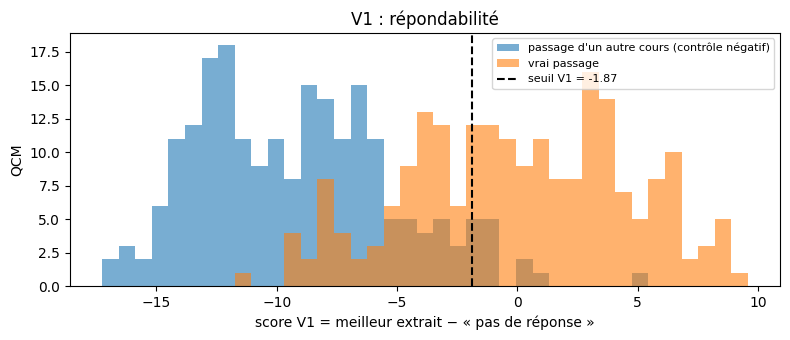

In [36]:
from sklearn.metrics import roc_auc_score
CONFIG.update({"v1_centile_neg": 0.95, "v2_imp_min": 0.5, "v3_imp_max": 0.9})

seuil_v1 = float(np.quantile(df_val["qa_score_neg"], CONFIG["v1_centile_neg"]))
y = np.r_[np.ones(len(df_val)), np.zeros(len(df_val))]
auc = roc_auc_score(y, np.r_[df_val["qa_score"], df_val["qa_score_neg"]])
print(f"Seuil V1 = {seuil_v1:.2f} | AUC vrai passage / autre cours = {auc:.3f}")
for m, g in df_val.groupby("methode"):
    print(f"  {m:5s} AUC = {roc_auc_score(np.r_[np.ones(len(g)), np.zeros(len(g))], np.r_[g['qa_score'], g['qa_score_neg']]):.3f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(min(df_val["qa_score_neg"].min(), df_val["qa_score"].min()), df_val["qa_score"].max(), 40)
ax.hist(df_val["qa_score_neg"], bins=bins, alpha=.6, label="passage d'un autre cours (contrôle négatif)")
ax.hist(df_val["qa_score"], bins=bins, alpha=.6, label="vrai passage")
ax.axvline(seuil_v1, color="k", ls="--", label=f"seuil V1 = {seuil_v1:.2f}")
ax.set(xlabel="score V1 = meilleur extrait − « pas de réponse »", ylabel="QCM", title="V1 : répondabilité")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(CONFIG["fig_dir"] / "v1_controle_negatif.png", dpi=150); plt.show()

## 7.4 Décisions V1, V2, V3

Chaque test **passe** (vrai) ou **échoue** (faux) :
- **V1** passe si `qa_score` ≥ seuil V1.
- **V2** passe si la bonne réponse désignée est l'**option la plus confirmée** par le passage (probabilité d'implication maximale) **et** si cette probabilité atteint au moins `v2_imp_min` = 0,5, c'est-à-dire que le modèle penche pour « implication ». Les deux conditions ensemble traduisent « une seule bonne réponse, et c'est la bonne ».
- **V3** passe si **aucun distracteur** n'atteint `v3_imp_max` = 0,9.

*Pourquoi un seuil plus strict pour V3 (0,9) que pour V2 (0,5) ?* L'essai préliminaire a montré que le petit modèle NLI est **indulgent** : la formulation « question + réponse » reprend les mots de la question, et il donne souvent une implication moyenne à des distracteurs faux. Avec 0,5, V3 rejetterait plus de la moitié des QCM de la base. V3 ne retient donc qu'une implication **franche**. En revanche, V2 compare les options **entre elles**, ce qui neutralise en partie cette indulgence. Ces deux seuils sont des choix de départ, justifiés mais pas optimisés. L'évaluation humaine (étape 9) dira s'ils sont bien placés, et l'étape 10 mesure la sensibilité.

In [37]:
df_val["V1"] = df_val["qa_score"] >= seuil_v1
df_val["V2"] = (df_val["option_preferee"] == df_val["index_correct"]) & (df_val["imp_bonne"] >= CONFIG["v2_imp_min"])
df_val["V3"] = df_val["imp_max_distracteur"] < CONFIG["v3_imp_max"]
df_val["semantique_ok"] = df_val[["V1", "V2", "V3"]].all(axis=1)
df_val = df_val.merge(df_forme[["qcm_id", "forme_ok"]], on="qcm_id")
df_val.drop(columns=["signature"]).to_csv(CONFIG["qcm_dir"] / "validation.csv", index=False)

tests_v = ["V1", "V2", "V3", "semantique_ok"]
taux = (df_val.groupby("methode")[tests_v].mean() * 100).round(1).T
taux.index = ["V1 répondabilité", "V2 une seule bonne réponse", "V3 aucun distracteur correct",
              "→ V1 et V2 et V3"]
print("Pourcentage de QCM qui PASSENT chaque test :")
display(taux)
print("Par cours (% passant V1, V2 et V3) :")
display((df_val.pivot_table(index="cours_id", columns="methode", values="semantique_ok", aggfunc="mean") * 100).round(0))

Pourcentage de QCM qui PASSENT chaque test :


methode,base,llm
V1 répondabilité,44.3,80.9
V2 une seule bonne réponse,89.7,51.3
V3 aucun distracteur correct,69.1,74.8
→ V1 et V2 et V3,25.8,33.0


Par cours (% passant V1, V2 et V3) :


methode,base,llm
cours_id,,
C1,26.0,35.0
C2,16.0,21.0
C3,30.0,47.0
C4,33.0,35.0
C5,28.0,42.0
C6,0.0,20.0


## 7.5 Le validateur détecte-t-il des défauts injectés ?

Sans annotations humaines, on ne connaît pas la **précision** du validateur (ses rejets sont-ils justifiés ?). Elle sera mesurée à l'étape 9. On peut déjà mesurer son **rappel** sur des défauts **fabriqués**, dont on connaît la nature à coup sûr.

**Défaut injecté : clé de correction fausse.** On prend les QCM qui passent V2 et V3, et on déclare comme « bonne réponse » un distracteur tiré au hasard. Le QCM contient alors une bonne réponse marquée fausse (V2 doit échouer) et un « distracteur » qui est en réalité la vraie réponse (V3 devrait échouer). C'est exactement l'erreur qu'un LLM commet quand il se trompe de réponse. Les probabilités d'implication ne dépendent pas de l'option marquée correcte : il suffit de réappliquer les règles, sans relancer les modèles.

**Comment lire le résultat.** Le taux de rejet par V2 vaut 100 % **par construction** : ces QCM passaient V2, donc l'option préférée par le NLI était l'ancienne bonne réponse, et elle ne peut pas être la nouvelle. Le chiffre informatif est celui de **V3**, qui travaille indépendamment de V2 : il mesure la part des cas où la vraie réponse, cachée parmi les distracteurs, est **elle-même** repérée comme « distracteur correct ». C'est le rappel de V3 sur ce type de défaut.

Le défaut « question sans réponse dans le passage » est le contrôle négatif de V1 (section 7.3) : par construction, environ 95 % sont rejetés.

In [38]:
ok = df_val[df_val["V2"] & df_val["V3"]].copy()
rng = np.random.default_rng(CONFIG["seed"])
ok["fausse_cle"] = [rng.choice([k for k in range(4) if k != c]) for c in ok["index_correct"]]
imp_ok = np.array(ok["implication"].tolist())
fk = ok["fausse_cle"].to_numpy()
ok["V2_inj"] = (imp_ok.argmax(axis=1) == fk) & (imp_ok[np.arange(len(fk)), fk] >= CONFIG["v2_imp_min"])
ok["V3_inj"] = np.where(np.eye(4, dtype=bool)[fk], -1, imp_ok).max(axis=1) < CONFIG["v3_imp_max"]
detect = ok.groupby("methode").agg(n=("qcm_id", "count"),
                                   rejete_par_V2=("V2_inj", lambda s: 100 * (~s).mean()),
                                   rejete_par_V3=("V3_inj", lambda s: 100 * (~s).mean()))
detect["rejete_par_V2_ou_V3"] = ok.assign(r=~(ok["V2_inj"] & ok["V3_inj"])).groupby("methode")["r"].mean() * 100
print("Clé de correction fausse injectée : % de QCM corrompus rejetés")
detect.round(1)

Clé de correction fausse injectée : % de QCM corrompus rejetés


,n,rejete_par_V2,rejete_par_V3,rejete_par_V2_ou_V3
methode,,,,
base,63,100.0,77.8,100.0
llm,48,100.0,31.2,100.0


## 7.6 Exemples de décisions

Pour chaque test, un QCM qui échoue, avec ses scores. On lit ainsi *pourquoi* le validateur rejette, et on repère ses erreurs (rejets injustifiés), qui alimenteront l'analyse des erreurs (étape 11).

In [39]:
def afficher_validation(qcm_id: str) -> None:
    r = df_val.set_index("qcm_id").loc[qcm_id]
    afficher_qcm(par_id[qcm_id])
    print(f"    extrait QA : « {r['qa_extrait'][:90]} »  score V1 = {r['qa_score']:.2f} (seuil {seuil_v1:.2f})")
    print(f"    implication par option : { {k: round(float(v), 2) for k, v in zip('ABCD', r['implication'])} }")
    print(f"    V1 {'✔' if r['V1'] else '✘'}   V2 {'✔' if r['V2'] else '✘'}   V3 {'✔' if r['V3'] else '✘'}\n")

for test in ["V1", "V2", "V3"]:
    echecs = df_val[~df_val[test]]
    print(f"■ Échec {test} : {len(echecs)} QCM")
    for _, r in echecs.groupby("methode").head(1).iterrows():
        afficher_validation(r["qcm_id"])
print("■ Un QCM accepté par les trois tests :")
afficher_validation(df_val[df_val["semantique_ok"]].iloc[0]["qcm_id"])

■ Échec V1 : 76 QCM
[BASE_C1_000] Complétez la phrase : « Le C a été conçu en 1972 par Dennis _____ et Ken Thompson, chercheurs aux Bell Labs, afin de développer un système d’exploitation UNIX sur un DEC PDP-11. »
    A) donnant
    B) livre
    C) annule
    D) Richie  ✔

    extrait QA : « Dennis Richie »  score V1 = -5.20 (seuil -1.87)
    implication par option : {'A': 0.66, 'B': 0.96, 'C': 0.65, 'D': 0.96}
    V1 ✘   V2 ✔   V3 ✘

[LLM_C1_011] Quelle est la taille minimale d'un objet de type long int sur un PC Intel ?
    A) 32 bits  ✔
    B) 16 bits
    C) 64 bits
    D) 8 bits

    extrait QA : « 32 bits »  score V1 = -2.05 (seuil -1.87)
    implication par option : {'A': 0.64, 'B': 0.6, 'C': 0.61, 'D': 0.05}
    V1 ✘   V2 ✔   V3 ✔

■ Échec V2 : 66 QCM
[BASE_C1_044] Complétez la phrase : « Nous sommes dans la configuration: _____ valeur i 4831836000 3 p 4831836004 4831836000 *p 4831836000 3 Cela signifie en particulier que toute modification de *p modifie i. »
    A) préciser uns

---
### Bilan de l'étape 7
- **V1** : un modèle de questions-réponses SQuAD 2.0 compare le meilleur extrait du passage à la réponse « pas de réponse ». Le seuil est fixé sans annotation, par un **contrôle négatif** : la même question posée à un passage d'un autre cours.
- **V2 et V3** : un modèle NLI donne, pour chaque option, la probabilité que le passage la confirme. L'hypothèse a la forme « question + réponse », pour éviter le biais de recouvrement lexical, et la prémisse se limite aux 2 phrases les plus proches.
- **Défauts injectés** : une clé de correction fausse est toujours rejetée. Le rejet par V2 est garanti par construction ; à lui seul, V3 en détecte environ les trois quarts (section 7.5).
- **Sur la base de référence**, V1 accepte presque tous les QCM : leur réponse est recopiée du passage. **V3 est le test le plus sévère.** Une partie de ses rejets est justifiée (« octets » ou « bit-à-bit » pour « bits »), d'autres sont de fausses alertes du modèle NLI (« livre » jugé confirmé pour « Dennis _____ »).
- Scores et décisions par QCM dans `outputs/qcm/validation.csv`, cache des scores dans `scores_validateur.jsonl`.

**Limites déjà visibles.** Le modèle NLI est petit et indulgent. Les questions à trous de la base, qui recopient une phrase du cours, sont un cas difficile pour lui. Et le validateur ne voit que le passage : une option vraie en C mais absente du passage sera jugée « non confirmée ». La **précision** des rejets reste à mesurer par l'évaluation humaine.

On passe maintenant à l'étape 8 : le filtrage final et la mesure de l'apport du filtre.

---
# Étape 8 — Filtrage final et mesure de l'apport du filtre

**À quoi sert cette étape ?** On réunit les deux contrôles :
- la **forme** (étape 6, règles F1 à F7) ;
- le **sens** (étape 7, tests V1, V2, V3).

On obtient ainsi la décision finale pour chaque QCM : **accepté** ou **rejeté**, avec le **motif** du rejet. On mesure ensuite ce que le filtre change : combien de QCM il retire, pour quelles raisons, sur quels cours, et si les QCM acceptés sont meilleurs que l'ensemble de départ.

**Règle de décision : un QCM est accepté seulement s'il passe tous les contrôles** (conjonction logique, « ET »). Un seul défaut suffit à rendre un QCM inutilisable en examen : deux bonnes réponses, une réponse absente du cours ou une option en double ne se compensent pas par ailleurs. On n'utilise donc pas de score global pondéré. Une moyenne laisserait passer un QCM très bon sur trois critères mais faux sur le quatrième, et ses poids seraient arbitraires.

**Prix de ce choix :** chaque contrôle ajoute ses propres fausses alertes. Le filtre est donc **sévère** : il privilégie la *précision*, c'est-à-dire des QCM acceptés fiables, au détriment du *volume*. C'est le bon compromis pour un enseignant, qui préfère 60 bonnes questions à 100 questions dont 20 sont fausses. L'étape 10 mesure ce que coûte chaque contrôle en le retirant (ablation).

In [40]:
ORDRE_CONTROLES = ["forme", "V1", "V2", "V3"]
df_filtre = df_val[["qcm_id", "methode", "cours_id", "forme_ok", "V1", "V2", "V3"]].copy()
df_filtre["accepte"] = df_filtre[["forme_ok", "V1", "V2", "V3"]].all(axis=1)

def motifs(r) -> list[str]:
    # Tous les contrôles échoués, avec le détail des règles de forme
    m = [regle.split()[0] for regle in F_REGLES if df_forme_idx.at[r["qcm_id"], regle]]
    return m + [t for t in ["V1", "V2", "V3"] if not r[t]]
df_forme_idx = df_forme.set_index("qcm_id")
df_filtre["motifs"] = df_filtre.apply(motifs, axis=1)
# Premier contrôle échoué dans l'ordre forme → V1 → V2 → V3 : sert seulement à présenter une cascade lisible
df_filtre["premier_echec"] = df_filtre.apply(
    lambda r: next((c for c in ORDRE_CONTROLES if not r["forme_ok" if c == "forme" else c]), "accepté"), axis=1)

# Fichiers de sortie : QCM acceptés, et QCM rejetés avec leurs motifs (pour l'analyse des erreurs)
for nom, masque in [("qcm_acceptes.jsonl", df_filtre["accepte"]), ("qcm_rejetes.jsonl", ~df_filtre["accepte"])]:
    with open(CONFIG["qcm_dir"] / nom, "w", encoding="utf-8") as f:
        for _, r in df_filtre[masque].iterrows():
            f.write(json.dumps({**par_id[r["qcm_id"]], "motifs": r["motifs"]}, ensure_ascii=False) + "\n")

bilan_filtre = df_filtre.groupby("methode").agg(QCM=("qcm_id", "count"), acceptes=("accepte", "sum"))
bilan_filtre["rejetes"] = bilan_filtre["QCM"] - bilan_filtre["acceptes"]
bilan_filtre["taux de rejet (%)"] = (100 * bilan_filtre["rejetes"] / bilan_filtre["QCM"]).round(1)
bilan_filtre

,QCM,acceptes,rejetes,taux de rejet (%)
methode,,,,
base,97,25,72,74.2
llm,115,30,85,73.9


## 8.1 Pourquoi les QCM sont-ils rejetés ?

Deux vues complémentaires :
- **La cascade** applique les contrôles l'un après l'autre (forme → V1 → V2 → V3) et compte combien de QCM chaque étape retire. L'ordre ne change pas la décision finale, puisque tout est combiné par « ET ». Il rend seulement le bilan lisible et additif : les pertes de chaque étape s'additionnent pour donner le total rejeté.
- **Les combinaisons d'échecs** montrent si les contrôles détectent les **mêmes** QCM ou des QCM **différents**. Deux contrôles qui rejettent toujours les mêmes QCM seraient redondants. S'ils se recouvrent peu, chacun apporte quelque chose, et l'étape 10 le confirmera par ablation.

Cascade (nombre de QCM) :


methode,base,llm
retirés par la forme (F1–F7),1,24
puis par V1 (répondabilité),54,16
puis par V2 (une seule bonne réponse),7,37
puis par V3 (aucun distracteur correct),10,8
→ acceptés,25,30


Combinaisons de contrôles échoués :


methode,base,llm
combinaison,,
V1,38,8
aucun échec,25,30
V1 + V3,13,0
V3,10,8
V2 + V3,4,13
V2,3,24
V1 + V2 + V3,2,1
V1 + V2,1,7
forme + V3,1,3


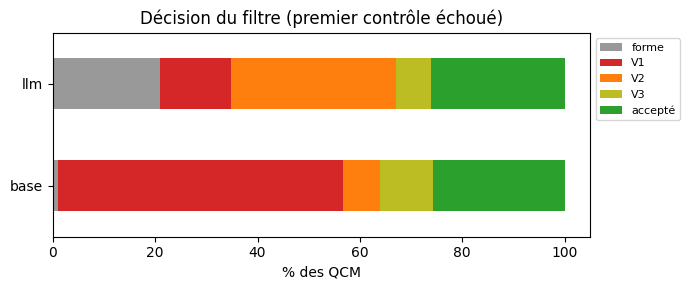

In [41]:
cascade = pd.crosstab(df_filtre["premier_echec"], df_filtre["methode"]).reindex(ORDRE_CONTROLES + ["accepté"]).fillna(0).astype(int)
cascade.index = ["retirés par la forme (F1–F7)", "puis par V1 (répondabilité)", "puis par V2 (une seule bonne réponse)",
                 "puis par V3 (aucun distracteur correct)", "→ acceptés"]
print("Cascade (nombre de QCM) :")
display(cascade)

echecs = df_filtre.assign(combinaison=df_filtre.apply(
    lambda r: " + ".join(c for c in ORDRE_CONTROLES if not r["forme_ok" if c == "forme" else c]) or "aucun échec", axis=1))
print("Combinaisons de contrôles échoués :")
display(pd.crosstab(echecs["combinaison"], echecs["methode"]).sort_values(echecs["methode"].iloc[0], ascending=False))

fig, ax = plt.subplots(figsize=(7, 3))
part = pd.crosstab(df_filtre["methode"], df_filtre["premier_echec"], normalize="index")[
    [c for c in ORDRE_CONTROLES + ["accepté"] if c in df_filtre["premier_echec"].unique()]] * 100
part.plot.barh(stacked=True, ax=ax, color={"forme": "#999999", "V1": "#d62728", "V2": "#ff7f0e",
                                           "V3": "#bcbd22", "accepté": "#2ca02c"})
ax.set(xlabel="% des QCM", ylabel="", title="Décision du filtre (premier contrôle échoué)")
ax.legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.savefig(CONFIG["fig_dir"] / "filtre_motifs.png", dpi=150); plt.show()

## 8.2 Rendement par cours : combien de QCM utilisables pour 20 passages ?

Le taux de rejet seul est trompeur : une méthode qui produit peu de QCM peut rejeter peu, et une méthode qui en produit beaucoup peut rejeter beaucoup tout en livrant davantage de bonnes questions. On regarde donc le **rendement** : le nombre de QCM **acceptés** pour les 20 passages de chaque cours. C'est ce que l'enseignant récupère au final.

In [42]:
rendement = df_filtre.pivot_table(index="cours_id", columns="methode", values="accepte", aggfunc="sum").reindex(
    sorted(echantillon["cours_id"].unique())).fillna(0).astype(int)
rendement.loc["Total"] = rendement.sum()
rendement.columns = [f"{m} : acceptés / {CONFIG['n_passages_par_cours']} passages" for m in rendement.columns]
rendement

,base : acceptés / 20 passages,llm : acceptés / 20 passages
cours_id,,
C1,5,6
C2,3,4
C3,6,6
C4,6,4
C5,5,7
C6,0,3
Total,25,30


## 8.3 Les QCM acceptés sont-ils plus difficiles à deviner ?

Un bon QCM ne doit pas pouvoir se résoudre **sans connaître le cours**, en exploitant un indice de surface. On simule deux « candidats naïfs », qui ne lisent pas le passage :
- **le candidat « plus longue »** choisit l'option la plus longue (indice classique, déjà testé à l'étape 6) ;
- **le candidat « plus cohérente »** choisit l'option la plus proche de la question selon le modèle d'embeddings. Pour une question à trous, c'est le mot qui « va le mieux » dans la phrase. Si les distracteurs sont hors sujet (« donnant », « livre » pour compléter « Dennis _____ »), ce candidat trouve la réponse sans rien savoir du langage C.

Avec 4 options, un candidat qui répond au hasard a **25 %** de réussite. Plus le taux d'un candidat naïf est **proche de 25 %**, moins le QCM laisse d'indices. On compare ce taux sur **tous** les QCM, sur les **acceptés** et sur les **rejetés**. Si le filtre retire surtout des QCM « devinables », le taux baisse chez les acceptés. Un taux **nettement inférieur** à 25 % est aussi un indice, inversé : un candidat malin éliminerait alors l'option désignée par la stratégie naïve. Seuls des taux proches de 25 % signifient « pas d'indice ».

*Limite de cette mesure :* elle n'est pas une évaluation de qualité complète. Un QCM peut être difficile à deviner et pourtant faux. C'est un **indicateur automatique d'appoint**, en attendant l'évaluation humaine.

In [43]:
def candidat_long(q):
    return max(range(4), key=lambda i: len(q["options"][i]))

def candidat_coherent(q):
    E = emb_model.encode([q["question"]] + q["options"], normalize_embeddings=True, show_progress_bar=False)
    return int(np.argmax(E[1:] @ E[0]))

df_filtre["devine_long"] = [candidat_long(par_id[i]) == par_id[i]["index_correct"] for i in df_filtre["qcm_id"]]
df_filtre["devine_coherent"] = [candidat_coherent(par_id[i]) == par_id[i]["index_correct"] for i in df_filtre["qcm_id"]]

lignes = []
for m, g in df_filtre.groupby("methode"):
    for nom, sous in [("tous", g), ("acceptés", g[g["accepte"]]), ("rejetés", g[~g["accepte"]])]:
        lignes.append({"methode": m, "groupe": nom, "n": len(sous),
                       "candidat « plus longue » (%)": round(100 * sous["devine_long"].mean(), 1) if len(sous) else np.nan,
                       "candidat « plus cohérente » (%)": round(100 * sous["devine_coherent"].mean(), 1) if len(sous) else np.nan})
print("Taux de réussite des candidats naïfs (hasard = 25 %) :")
pd.DataFrame(lignes).set_index(["methode", "groupe"])

Taux de réussite des candidats naïfs (hasard = 25 %) :


n  candidat « plus longue » (%)  \
methode groupe                                        
base    tous       97                          23.7   
        acceptés   25                          20.0   
        rejetés    72                          25.0   
llm     tous      115                          42.6   
        acceptés   30                          50.0   
        rejetés    85                          40.0   

                  candidat « plus cohérente » (%)  
methode groupe                                     
base    tous                                 15.5  
        acceptés                             20.0  
        rejetés                              13.9  
llm     tous                                 38.3  
        acceptés                             43.3  
        rejetés                              36.5

## 8.4 Ce que l'évaluation humaine mesurera

Les mesures précédentes décrivent **ce que fait** le filtre. Elles ne disent pas s'il **a raison**. Seul un jugement humain le dit, et c'est l'objet de l'étape 9. Les définitions sont fixées **dès maintenant**, avant de voir les annotations, pour ne pas choisir après coup la mesure la plus flatteuse.

Chaque QCM évalué reçoit un verdict humain : **acceptable**, c'est-à-dire clair, avec une seule bonne réponse et des distracteurs faux, ou **non acceptable**. On calculera :

| Mesure | Définition | Ce qu'elle dit |
|---|---|---|
| Qualité avant filtre | % de QCM acceptables parmi **tous** les QCM | niveau brut du générateur |
| Qualité après filtre | % de QCM acceptables parmi les QCM **acceptés** | ce que reçoit l'enseignant |
| **Apport du filtre** | qualité après − qualité avant (en points) | le gain apporté par la validation |
| Précision des rejets | % de QCM **non acceptables** parmi les **rejetés** | le filtre rejette-t-il à bon escient ? |
| Rappel des défauts | % des QCM non acceptables que le filtre a rejetés | combien de défauts il attrape |

Pour estimer ces mesures avec seulement 60 QCM, l'échantillon sera **stratifié** : il contiendra des QCM acceptés **et** rejetés, des deux méthodes. Un échantillon purement aléatoire contiendrait trop peu de rejetés pour juger la précision des rejets. Les annotateurs ne verront **ni la méthode ni la décision du filtre** (évaluation en aveugle), pour ne pas être influencés.

---
### Bilan de l'étape 8
- Décision finale : accepté si **forme ET V1 ET V2 ET V3**. QCM acceptés dans `outputs/qcm/qcm_acceptes.jsonl`, rejetés avec leurs motifs dans `qcm_rejetes.jsonl`.
- Les motifs de rejet sont détaillés par cascade et par combinaison d'échecs (figure `filtre_motifs.png`), et le rendement est donné par cours.
- Indicateur automatique : les candidats naïfs mesurent si les QCM acceptés sont moins faciles à deviner que l'ensemble. Les effectifs sont petits (quelques dizaines de QCM par groupe) : un écart de quelques points n'est pas significatif à lui seul.
- Les mesures de l'apport du filtre par évaluation humaine sont définies à l'avance.

On passe maintenant à l'étape 9 : l'évaluation humaine, qui dira si le filtre a raison.

---
# Étape 9 — Évaluation humaine (60 QCM) et accord entre évaluateurs

**À quoi sert cette étape ?** Les étapes 6 à 8 disent **ce que fait** le filtre. Seul un jugement humain dit s'il **a raison**, et si les QCM produits sont bons. Le sujet demande :
- une grille d'évaluation sur **60 QCM** (clarté, difficulté, unicité de la bonne réponse) ;
- le **taux de rejet** du filtre ;
- l'**accord entre évaluateurs**.

**Organisation en trois temps :**
1. **Ici, dans le notebook** : tirage de l'échantillon, puis création des grilles vierges et du guide d'annotation dans `data/annotations/`.
2. **Hors du notebook** : les deux membres du binôme remplissent **chacun sa grille, séparément**, sans se concerter.
3. **De retour dans le notebook** : les cellules d'analyse lisent les grilles remplies et calculent l'accord et l'apport du filtre. Tant que les grilles sont vides, elles l'indiquent et passent leur tour.

**Pourquoi deux évaluateurs indépendants ?** Juger un QCM est en partie subjectif (« cette question est-elle claire ? »). Avec un seul évaluateur, on ne sait pas si ses jugements sont **reproductibles**. Avec deux évaluateurs qui ne se concertent pas, on mesure leur **accord**. Si l'accord est faible, c'est la grille qui est floue, et les conclusions de l'évaluation sont fragiles.

## 9.1 La grille d'évaluation

Pour chaque QCM, l'évaluateur voit le **passage du cours**, la question, les 4 options et la bonne réponse **indiquée par le système**. Il remplit trois critères :

| Critère | Valeurs | Définition |
|---|---|---|
| **clarte** | 1, 2, 3 | 1 = incompréhensible ou ambiguë ; 2 = compréhensible avec effort (formulation maladroite, phrase tronquée) ; 3 = claire |
| **difficulte** | 1, 2, 3 | pour un étudiant **qui a étudié ce cours** : 1 = facile (réponse évidente, ou devinable sans le cours) ; 2 = moyenne ; 3 = difficile (demande de bien comprendre) |
| **unicite** | 1, 0 | 1 = **une seule** option est correcte **et** c'est celle indiquée ; 0 = sinon : aucune option correcte, plusieurs options correctes, ou bonne réponse indiquée fausse |

Une colonne `commentaire` libre sert à noter le défaut observé. Ces notes alimenteront l'analyse des erreurs (étape 11).

**Verdict « acceptable », déduit et non demandé.** Un QCM est **acceptable** si `clarte ≥ 2` **et** `unicite = 1` : il est compréhensible, et il a une seule bonne réponse, la bonne. On ne demande pas à l'évaluateur un verdict global « bon / mauvais » en plus. Ce serait un jugement d'ensemble plus subjectif, alors que la règle ci-dessus le déduit de critères précis et identiques pour tous. La difficulté n'entre pas dans le verdict : une question facile reste un QCM valide. Elle sert à comparer les deux méthodes.

**Pourquoi des échelles à 3 niveaux, et pas à 5 ?** Sur 60 QCM, des échelles fines dispersent les jugements : deux évaluateurs donnent facilement 3 et 4 pour la même impression, et l'accord s'effondre sans que les jugements soient vraiment différents. Trois niveaux suffisent pour distinguer « inutilisable / perfectible / bon ».

## 9.2 Échantillon de 60 QCM : stratifié et en aveugle

**Stratifié.** On tire le même nombre de QCM dans chaque case **méthode × décision du filtre** : base acceptés, base rejetés, LLM acceptés, LLM rejetés, soit 15 par case. Un tirage simplement aléatoire suivrait les proportions réelles, environ deux tiers d'acceptés. Il donnerait donc trop peu de **rejetés** pour mesurer la précision des rejets, et le résultat dépendrait de quelques QCM. Le tirage stratifié garantit assez d'exemples dans chaque case. En contrepartie, l'échantillon ne reflète plus les proportions réelles : pour estimer la qualité **avant filtre**, chaque case est **repondérée** par sa part réelle (section 9.5). Si une case contient moins de 15 QCM, on les prend tous et on complète avec les autres cases de la même méthode.

**En aveugle.** Les grilles ne montrent **ni la méthode ni la décision du filtre**, et les QCM y sont dans un ordre aléatoire, sous un identifiant neutre (`EVAL_01`…). Un évaluateur qui sait qu'un QCM a été rejeté y cherche un défaut : c'est le **biais de confirmation**. La correspondance entre identifiants et QCM est dans un fichier séparé, `cle_echantillon.csv`, que les évaluateurs ne doivent **pas ouvrir** avant d'avoir fini.

*Limite de l'aveugle :* les questions à trous de la base (« Complétez la phrase… ») se reconnaissent facilement. On ne cache donc pas complètement la méthode. On cache en revanche la décision du filtre, qui est l'objet principal de la mesure.

**L'échantillon n'est créé que lorsque les QCM des deux méthodes existent.** Le tirer sans les QCM du LLM obligerait à le refaire, et des annotations déjà faites seraient perdues. En attendant, la cellule affiche seulement un **aperçu**, sans rien écrire. Une fois créées, les grilles ne sont **jamais écrasées** par une nouvelle exécution, pour ne pas perdre un travail d'annotation.

In [44]:
CONFIG.update({"n_eval": 60, "evaluateurs": ["A", "B"]})
ANNOT = CONFIG["annot_dir"]
CLE_EVAL = ANNOT / "cle_echantillon.csv"
GRILLES = {e: ANNOT / f"grille_evaluateur_{e}.csv" for e in CONFIG["evaluateurs"]}
COLONNES_A_REMPLIR = ["clarte", "difficulte", "unicite", "commentaire"]

def tirer_echantillon(df: pd.DataFrame, n_total: int, seed: int) -> pd.DataFrame:
    # Même nombre de QCM par case (méthode × accepté) ; une case trop petite est complétée par l'autre case de la méthode
    methodes = sorted(df["methode"].unique())
    par_methode = n_total // len(methodes)
    tirages = []
    for m in methodes:
        g = df[df["methode"] == m]
        acc, rej = g[g["accepte"]], g[~g["accepte"]]
        n_rej = min(len(rej), par_methode // 2)
        n_acc = min(len(acc), par_methode - n_rej)
        n_rej = min(len(rej), par_methode - n_acc)
        tirages += [acc.sample(n_acc, random_state=seed), rej.sample(n_rej, random_state=seed)]
    return pd.concat(tirages).sample(frac=1, random_state=seed).reset_index(drop=True)   # ordre aléatoire

deux_methodes = df_filtre["methode"].nunique() == 2
ech_eval = tirer_echantillon(df_filtre, CONFIG["n_eval"], CONFIG["seed"])
ech_eval["eval_id"] = [f"EVAL_{k + 1:02d}" for k in range(len(ech_eval))]
print("Échantillon (nombre de QCM par case) :")
display(pd.crosstab(ech_eval["methode"], ech_eval["accepte"].map({True: "accepté", False: "rejeté"})))

if CLE_EVAL.exists():
    print(f"Grilles déjà créées ({CLE_EVAL.name} présent) : elles ne sont pas réécrites.")
elif not deux_methodes:
    print("⚠ APERÇU SEULEMENT : les QCM du LLM sont absents (étape 5 à lancer sur Colab). "
          "Aucune grille n'est écrite, pour ne pas devoir refaire des annotations.")
else:
    ech_eval[["eval_id", "qcm_id", "methode", "accepte"]].to_csv(CLE_EVAL, index=False)
    lignes_grille = []
    for _, r in ech_eval.iterrows():
        q = par_id[r["qcm_id"]]
        lignes_grille.append({"eval_id": r["eval_id"], "cours": q["cours_id"], "passage": texte_de[q["passage_id"]],
                              "question": q["question"], **{l: o for l, o in zip("ABCD", q["options"])},
                              "bonne_reponse_indiquee": "ABCD"[q["index_correct"]],
                              **{c: "" for c in COLONNES_A_REMPLIR}})
    for e, chemin in GRILLES.items():
        # séparateur « ; » et BOM UTF-8 : le fichier s'ouvre directement dans Excel en français, accents compris
        pd.DataFrame(lignes_grille).to_csv(chemin, sep=";", index=False, encoding="utf-8-sig")
    print("Grilles écrites :", ", ".join(p.name for p in GRILLES.values()), "+", CLE_EVAL.name)

Échantillon (nombre de QCM par case) :


accepte,accepté,rejeté
methode,,
base,15,15
llm,15,15


Grilles écrites : grille_evaluateur_A.csv, grille_evaluateur_B.csv + cle_echantillon.csv


**Le guide d'annotation** est écrit dans `data/annotations/GUIDE_ANNOTATION.md`. Il reprend les définitions de la section 9.1 avec des exemples. Les deux évaluateurs le lisent **avant** de commencer. Des consignes écrites et identiques pour les deux sont la première condition d'un bon accord.

In [45]:
GUIDE = r'''# Guide d'annotation des QCM

Merci de remplir **votre** grille (`grille_evaluateur_A.csv` ou `grille_evaluateur_B.csv`) **seul·e**, sans en parler avec l'autre évaluateur avant d'avoir terminé.
**N'ouvrez pas `cle_echantillon.csv`** : il indique quelle méthode a produit chaque QCM et si le filtre l'a accepté.

Pour chaque ligne : lisez le **passage**, puis la question, les options A à D et la bonne réponse indiquée.
Jugez le QCM **par rapport au passage**, comme un enseignant qui vérifierait une question d'examen sur ce cours.

## clarte : 1, 2 ou 3
- **3** : la question se comprend du premier coup.
- **2** : compréhensible avec effort (formulation maladroite, faute, phrase tronquée, mot étrange).
- **1** : incompréhensible, ou plusieurs lectures possibles.

## difficulte : 1, 2 ou 3
Pour un étudiant qui **a étudié ce cours** :
- **1** : facile, ou réponse devinable sans connaître le cours (par exemple, distracteurs absurdes).
- **2** : moyenne.
- **3** : difficile, il faut avoir bien compris.

## unicite : 1 ou 0
- **1** : **une seule** option est correcte d'après le passage, **et** c'est la bonne réponse indiquée.
- **0** : aucune option n'est correcte, **ou** plusieurs le sont, **ou** la bonne réponse indiquée est fausse.

Exemple. Question « Complétez : un tableau à deux _____ est un tableau de tableaux », options *size, dimensions, sizeof, tailles*, réponse indiquée *dimensions*.
« tailles » n'est pas strictement synonyme mais pourrait se défendre : si vous hésitez sérieusement, mettez **0** et expliquez en commentaire.

## commentaire (facultatif)
Notez en quelques mots le défaut observé : « deux bonnes réponses », « distracteurs hors sujet », « phrase tronquée », « réponse fausse »…

Remplissez **toutes** les lignes. Enregistrez au même format (CSV, séparateur « ; »).
'''
(ANNOT / "GUIDE_ANNOTATION.md").write_text(GUIDE, encoding="utf-8")
print("Guide écrit :", ANNOT / "GUIDE_ANNOTATION.md")

Guide écrit : /content/TALN/data/annotations/GUIDE_ANNOTATION.md


## 9.3 Lecture et contrôle des grilles remplies

La cellule suivante lit les grilles et **vérifie** les annotations : toutes les lignes remplies, des valeurs autorisées seulement (1-3 pour la clarté et la difficulté, 0/1 pour l'unicité). Une faute de saisie, comme « 4 » ou une case vide, fausserait les calculs sans bruit. On préfère l'arrêter ici en indiquant la ligne en cause.

In [46]:
VALEURS = {"clarte": {1, 2, 3}, "difficulte": {1, 2, 3}, "unicite": {0, 1}}

def lire_grille(chemin: Path) -> pd.DataFrame | None:
    g = pd.read_csv(chemin, sep=";", encoding="utf-8-sig", dtype=str).fillna("")
    remplie = (g[list(VALEURS)].apply(lambda s: s.str.strip()) != "").any(axis=1)
    if not remplie.any():
        return None                                           # grille encore vierge
    erreurs = []
    for col, ok in VALEURS.items():
        v = pd.to_numeric(g[col].str.strip(), errors="coerce")
        for i in g.index[~v.isin(ok)]:
            erreurs.append(f"{g.at[i, 'eval_id']} : {col} = « {g.at[i, col]} » (attendu {sorted(ok)})")
        g[col] = v
    if erreurs:
        raise ValueError(f"{chemin.name} : {len(erreurs)} valeur(s) invalide(s)\n  " + "\n  ".join(erreurs[:15]))
    return g[["eval_id"] + COLONNES_A_REMPLIR]

annotations = {}
for e, chemin in GRILLES.items():
    if chemin.exists():
        g = lire_grille(chemin)
        if g is not None:
            annotations[e] = g
ANNOTATIONS_PRETES = len(annotations) == len(GRILLES)
print("Grilles remplies :", sorted(annotations) or "aucune",
      "" if ANNOTATIONS_PRETES else "→ analyses 9.4 et 9.5 en attente des annotations.")

Grilles remplies : aucune → analyses 9.4 et 9.5 en attente des annotations.


## 9.4 Accord entre évaluateurs

**Pourquoi le kappa, et pas le simple pourcentage d'accord ?** Deux évaluateurs qui répondent au hasard tombent d'accord **par chance** une partie du temps. Si 90 % des QCM ont `unicite = 1`, deux évaluateurs qui cochent presque toujours 1 sont d'accord environ 82 % du temps sans rien juger. Le **kappa de Cohen** retire cet accord attendu par hasard :

$$\kappa = \frac{p_o - p_e}{1 - p_e}$$

où $p_o$ est l'accord observé et $p_e$ l'accord attendu par hasard, calculé d'après la fréquence des réponses de chaque évaluateur. κ = 1 : accord parfait ; κ = 0 : pas mieux que le hasard.

- **unicite** (binaire) : kappa de Cohen simple.
- **clarte** et **difficulte** (ordinales) : kappa **pondéré quadratique**. Un désaccord 2 contre 3 est moins grave qu'un désaccord 1 contre 3. Le kappa simple les compterait pareil, la pondération quadratique pénalise selon le carré de l'écart.

Pour interpréter les valeurs, on suit l'échelle usuelle de Landis et Koch (1977) : < 0,2 faible ; 0,2–0,4 passable ; 0,4–0,6 modéré ; 0,6–0,8 substantiel ; > 0,8 presque parfait. On donne aussi le pourcentage d'accord brut, plus intuitif.

In [47]:
from sklearn.metrics import cohen_kappa_score

def niveau_kappa(k: float) -> str:
    return ("faible" if k < .2 else "passable" if k < .4 else "modéré" if k < .6
            else "substantiel" if k < .8 else "presque parfait")

def accord(a: pd.DataFrame, b: pd.DataFrame) -> pd.DataFrame:
    m = a.merge(b, on="eval_id", suffixes=("_A", "_B"))
    lignes = []
    for col, poids in [("clarte", "quadratic"), ("difficulte", "quadratic"), ("unicite", None)]:
        k = cohen_kappa_score(m[f"{col}_A"], m[f"{col}_B"], weights=poids)
        lignes.append({"critère": col, "kappa": round(k, 3), "pondération": poids or "aucune",
                       "accord brut (%)": round(100 * (m[f"{col}_A"] == m[f"{col}_B"]).mean(), 1),
                       "interprétation": niveau_kappa(k)})
    return pd.DataFrame(lignes).set_index("critère")

if ANNOTATIONS_PRETES:
    display(accord(annotations["A"], annotations["B"]))
else:
    print("En attente des deux grilles remplies.")

En attente des deux grilles remplies.


## 9.5 Qualité des QCM et apport du filtre

**Un verdict par QCM.** Les deux évaluateurs peuvent être en désaccord. On retient comme règle principale l'**accord strict** : un QCM est acceptable si **les deux** évaluateurs le jugent acceptable. Cette règle est prudente : un QCM dont un évaluateur doute n'est pas sûr pour un examen. Pour vérifier que les conclusions ne dépendent pas de cette règle, on donne aussi la variante **indulgente**, où un seul évaluateur suffit.

**Repondération.** L'échantillon contient autant d'acceptés que de rejetés, mais pas la population. Pour chaque méthode, la qualité **avant filtre** est donc une moyenne **pondérée** des deux cases :

$$\text{qualité avant} = w_{acc}\,p_{acc} + w_{rej}\,p_{rej}$$

où $p$ est la part de QCM acceptables dans la case et $w$ la part réelle de la case parmi tous les QCM de la méthode (étape 8). La qualité **après filtre** est simplement $p_{acc}$.

**Intervalles de confiance par bootstrap.** Avec 15 QCM par case, une proportion a une incertitude de plusieurs dizaines de points. On donne donc un **intervalle de confiance à 95 %** par *bootstrap* :
1. on retire au hasard, **avec remise**, les QCM de chaque case ;
2. on recalcule les mesures ;
3. on répète 2 000 fois, et on garde les centiles 2,5 et 97,5.

Le bootstrap ne suppose aucune loi particulière et s'applique tel quel à des mesures composées, comme l'apport du filtre, qui est une différence de moyennes pondérées.

In [48]:
poids_cases = df_filtre.groupby("methode")["accepte"].mean()      # w_acc par méthode (w_rej = 1 - w_acc)

def mesures_filtre(d: pd.DataFrame, w_acc: float) -> dict:
    p_acc = d.loc[d["accepte"], "acceptable"].mean()
    p_rej = d.loc[~d["accepte"], "acceptable"].mean()
    avant = w_acc * p_acc + (1 - w_acc) * p_rej
    defauts_rejetes = (1 - w_acc) * (1 - p_rej)
    defauts_total = defauts_rejetes + w_acc * (1 - p_acc)
    return {"qualité avant filtre": avant, "qualité après filtre": p_acc, "apport du filtre (points)": p_acc - avant,
            "précision des rejets": 1 - p_rej, "rappel des défauts": defauts_rejetes / defauts_total if defauts_total else np.nan}

def bootstrap(d: pd.DataFrame, w_acc: float, n: int = 2000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    cases = [g for _, g in d.groupby("accepte")]
    tirages = [mesures_filtre(pd.concat([g.iloc[rng.integers(0, len(g), len(g))] for g in cases]), w_acc)
               for _ in range(n)]
    t = pd.DataFrame(tirages)
    return pd.DataFrame({"estimation": mesures_filtre(d, w_acc), "IC95 bas": t.quantile(.025), "IC95 haut": t.quantile(.975)})

if ANNOTATIONS_PRETES:
    cle = pd.read_csv(CLE_EVAL)
    A, B = annotations["A"].set_index("eval_id"), annotations["B"].set_index("eval_id")
    accept_A = (A["clarte"] >= 2) & (A["unicite"] == 1)
    accept_B = (B["clarte"] >= 2) & (B["unicite"] == 1)
    for regle, verdict in [("stricte (A et B)", accept_A & accept_B), ("indulgente (A ou B)", accept_A | accept_B)]:
        d = cle.assign(acceptable=cle["eval_id"].map(verdict).astype(float))
        print(f"■ Règle {regle}")
        for m, g in d.groupby("methode"):
            print(f"  méthode {m} (part réelle d'acceptés w_acc = {poids_cases[m]:.2f})")
            display((bootstrap(g, poids_cases[m]) * 100).round(1))
    moy = cle.assign(clarte=cle["eval_id"].map((A["clarte"] + B["clarte"]) / 2),
                     difficulte=cle["eval_id"].map((A["difficulte"] + B["difficulte"]) / 2))
    print("Clarté et difficulté moyennes (moyenne des deux évaluateurs, échelle 1-3) :")
    display(moy.groupby(["methode", "accepte"])[["clarte", "difficulte"]].mean().round(2))
else:
    print("En attente des deux grilles remplies.")

En attente des deux grilles remplies.


**Les tests du validateur sont-ils d'accord avec les évaluateurs ?** On croise maintenant chaque test avec le critère humain qu'il est censé reproduire :
- V2 et V3 visent l'**unicité** de la bonne réponse ;
- la forme vise en partie la **clarté**.

On ne peut pas croiser V1 avec un critère de la grille : les évaluateurs jugent les QCM **avec** le passage, et une question sans réponse dans le passage reçoit `unicite = 0`. V1 est donc évalué à travers l'unicité, comme V2 et V3.

Pour chaque test, on calcule la part des QCM qu'il **rejette** parmi ceux que les deux évaluateurs jugent défectueux sur ce critère (rappel), et la part de ses rejets qui sont des défauts réels (précision). Comme l'échantillon contient beaucoup de QCM rejetés, ces chiffres décrivent le comportement des tests dans l'échantillon, sans repondération. Ils servent à repérer **quel test se trompe le plus**, et donc lequel ajuster à l'étape 10.

On complète par le **filtre complet comme classifieur** du verdict humain : matrice de
confusion 2×2 (bons QCM gardés, mauvais gardés, bons rejetés, mauvais rejetés), précision,
rappel et F1. C'est la mesure demandée par le besoin BF12 de l'analyse des besoins.


In [49]:
if ANNOTATIONS_PRETES:
    d = cle.merge(df_filtre[["qcm_id", "forme_ok", "V1", "V2", "V3"]], on="qcm_id")
    d["unicite_ko"] = d["eval_id"].map((A["unicite"] == 0) & (B["unicite"] == 0))
    d["clarte_ko"] = d["eval_id"].map((A["clarte"] == 1) & (B["clarte"] == 1))
    lignes = []
    for test, critere in [("V1", "unicite_ko"), ("V2", "unicite_ko"), ("V3", "unicite_ko"), ("forme_ok", "clarte_ko")]:
        rejete = ~d[test]
        lignes.append({"test": test, "critère humain": critere.replace("_ko", " défaillante"),
                       "rejets": int(rejete.sum()), "défauts humains": int(d[critere].sum()),
                       "précision (%)": round(100 * d.loc[rejete, critere].mean(), 1) if rejete.any() else np.nan,
                       "rappel (%)": round(100 * rejete[d[critere]].mean(), 1) if d[critere].any() else np.nan})
    display(pd.DataFrame(lignes).set_index("test"))
    # BF12 : le filtre complet comme classifieur du verdict humain « acceptable ».
    # Positifs = QCM jugés acceptables par les deux évaluateurs (règle stricte).
    accept_A = (A["clarte"] >= 2) & (A["unicite"] == 1)
    accept_B = (B["clarte"] >= 2) & (B["unicite"] == 1)
    humain = d["eval_id"].map(accept_A & accept_B).astype(bool)
    filtre = d[["forme_ok", "V1", "V2", "V3"]].all(axis=1)
    vp, fp = int((filtre & humain).sum()), int((filtre & ~humain).sum())
    fn, vn = int((~filtre & humain).sum()), int((~filtre & ~humain).sum())
    precision = vp / (vp + fp) if vp + fp else np.nan
    rappel = vp / (vp + fn) if vp + fn else np.nan
    f1 = 2 * precision * rappel / (precision + rappel) if precision + rappel else np.nan
    display(pd.DataFrame([{
        "vrais positifs (bons gardés)": vp, "faux positifs (mauvais gardés)": fp,
        "faux négatifs (bons rejetés)": fn, "vrais négatifs (mauvais rejetés)": vn,
        "précision (%)": round(100 * precision, 1),
        "rappel (%)": round(100 * rappel, 1),
        "F1 (%)": round(100 * f1, 1),
    }], index=["filtre complet (forme ET V1 ET V2 ET V3)"]))
else:
    print("En attente des deux grilles remplies.")

En attente des deux grilles remplies.


---
### Bilan de l'étape 9
- Grille à 3 critères (clarté, difficulté, unicité), avec un verdict « acceptable » **déduit** par une règle explicite. Le guide d'annotation est dans `data/annotations/GUIDE_ANNOTATION.md`.
- Échantillon de 60 QCM **stratifié** (méthode × décision du filtre) et présenté **en aveugle**. Il n'est créé qu'une fois les QCM du LLM disponibles, et n'est jamais réécrit.
- Accord entre évaluateurs : kappa de Cohen, pondéré pour les critères ordinaux.
- Apport du filtre : qualité avant et après filtre, précision des rejets, rappel des défauts. Les mesures sont **repondérées** et accompagnées d'un intervalle de confiance par bootstrap.

**Marche à suivre :** générer les QCM du LLM sur Colab, réexécuter le notebook pour créer les grilles, faire remplir `grille_evaluateur_A.csv` et `grille_evaluateur_B.csv` par les deux membres du binôme, séparément, puis réexécuter : les sections 9.4 et 9.5 se remplissent alors.

On passe maintenant à l'étape 10 : les ablations et la sensibilité aux seuils.

---
# Étape 10 — Ablations et sensibilité aux seuils

**À quoi sert cette étape ?** Chaque élément du système a été choisi et justifié. Une **ablation** vérifie qu'il sert vraiment : on le retire, ou on le remplace par l'alternative écartée, et on mesure ce qui change. Une **étude de sensibilité** fait varier un seuil pour voir si les conclusions tiennent quand on le déplace un peu, ou si elles reposent sur une valeur choisie au hasard.

**Ce qui est étudié :**

| Section | Élément testé | Alternative |
|---|---|---|
| 10.1 | chaque contrôle du filtre (forme, V1, V2, V3) | filtre sans ce contrôle |
| 10.2 | les trois seuils du validateur | une grille de valeurs autour du seuil choisi |
| 10.3 | modèle QA « SQuAD 2.0 » pour V1 | CamemBERT FQuAD/PIAF (choix initial, sans « pas de réponse ») |
| 10.4 | formulation (B) et prémisse de 2 phrases pour le NLI | formulation (A), prémisse de 1 ou 4 phrases, mDeBERTa (si GPU) |
| 10.5 | décodage glouton du LLM | échantillonnage à température 0,7 et 1,0 (si GPU) |

**Avec quelles mesures ?** On combine des mesures **automatiques**, disponibles tout de suite, et des mesures **humaines**, disponibles une fois les grilles de l'étape 9 remplies :
- **taux d'acceptation** : combien de QCM le filtre laisse passer ;
- **discernement du NLI** : sur les QCM de la **base**, la bonne réponse est recopiée du cours, elle est donc correcte par construction. On mesure à quelle fréquence le NLI préfère la bonne réponse aux trois distracteurs. On ne le mesure pas sur le LLM, dont la bonne réponse n'est pas garantie ;
- **détection d'une clé fausse par V3** : le défaut injecté de l'étape 7 ;
- **AUC du contrôle négatif** pour V1 ;
- **qualité humaine des QCM acceptés**, une fois les annotations disponibles : part de QCM jugés acceptables parmi ceux qu'une variante du filtre accepte.

**Comment estimer la qualité d'une variante avec l'échantillon de l'étape 9 ?** L'échantillon a été stratifié selon la décision du filtre **complet**. Une variante accepte un autre ensemble de QCM. On pondère donc chaque QCM annoté par l'**inverse de sa probabilité d'avoir été tiré** (estimateur de Horvitz-Thompson) : un QCM d'une case de 60 QCM dont on a tiré 15 « représente » 4 QCM. On estime ainsi la qualité de n'importe quel sous-ensemble sans annoter de nouveaux QCM.

In [50]:
imp_all = np.array(df_val["implication"].tolist())
c_all = df_val["index_correct"].to_numpy()
rang = np.arange(len(c_all))
EST_BASE = (df_val["methode"] == "base").to_numpy()

def decisions(centile=None, v2=None, v3=None, controles=("forme", "V1", "V2", "V3"), imp=None) -> pd.Series:
    # Recalcule la décision du filtre à partir des scores en cache, pour d'autres seuils ou sans certains contrôles
    centile = CONFIG["v1_centile_neg"] if centile is None else centile
    v2 = CONFIG["v2_imp_min"] if v2 is None else v2
    v3 = CONFIG["v3_imp_max"] if v3 is None else v3
    imp = imp_all if imp is None else imp
    tests = {"forme": df_val["forme_ok"].to_numpy(),
             "V1": df_val["qa_score"].to_numpy() >= np.quantile(df_val["qa_score_neg"], centile),
             "V2": (imp.argmax(axis=1) == c_all) & (imp[rang, c_all] >= v2),
             "V3": np.where(np.eye(4, dtype=bool)[c_all], -1, imp).max(axis=1) < v3}
    acc = np.ones(len(df_val), dtype=bool)
    for t in controles:
        acc &= tests[t]
    return pd.Series(acc, index=df_val["qcm_id"])

# Vérification : avec les réglages par défaut, on retrouve exactement la décision de l'étape 8
assert (decisions().to_numpy() == df_filtre.set_index("qcm_id").loc[df_val["qcm_id"], "accepte"].to_numpy()).all()

# Qualité humaine d'un ensemble de QCM acceptés (estimateur de Horvitz-Thompson), si les annotations existent
if ANNOTATIONS_PRETES:
    eval_ht = cle.copy()
    eval_ht["acceptable"] = eval_ht["eval_id"].map(accept_A & accept_B).astype(float)
    taille = df_filtre.groupby(["methode", "accepte"]).size()
    tires = eval_ht.groupby(["methode", "accepte"]).size()
    eval_ht["poids"] = [taille[(m, a)] / tires[(m, a)] for m, a in zip(eval_ht["methode"], eval_ht["accepte"])]

def qualite_humaine(acceptes: pd.Series) -> dict:
    if not ANNOTATIONS_PRETES:
        return {}
    d = eval_ht[eval_ht["qcm_id"].map(acceptes)]
    return {m: round(100 * np.average(g["acceptable"], weights=g["poids"]), 1) for m, g in d.groupby("methode")}

def resume(acceptes: pd.Series) -> dict:
    r = {f"% acceptés {m}": round(100 * acceptes[df_val["qcm_id"][df_val["methode"] == m]].mean(), 1)
         for m in sorted(df_val["methode"].unique())}
    r.update({f"qualité humaine {m} (%)": v for m, v in qualite_humaine(acceptes).items()})
    return r
print("Décisions recalculées à partir du cache : identiques à l'étape 8 ✔")

Décisions recalculées à partir du cache : identiques à l'étape 8 ✔


## 10.1 Ablation des contrôles du filtre

On retire **un contrôle à la fois**, puis on compare avec deux références : le filtre complet et l'absence de filtre.
- Si retirer un contrôle **augmente beaucoup le nombre d'acceptés**, ce contrôle rejette des QCM que les autres laissent passer : il n'est pas redondant.
- Une fois les annotations disponibles, la colonne de qualité humaine dit si ces QCM supplémentaires sont **bons**, auquel cas le contrôle rejetait à tort, ou **mauvais**, auquel cas il était utile.

Un contrôle utile est un contrôle dont le retrait **fait baisser la qualité** des acceptés.

In [51]:
TOUS = ("forme", "V1", "V2", "V3")
variantes = {"filtre complet": TOUS, **{f"sans {t}": tuple(x for x in TOUS if x != t) for t in TOUS},
             "forme seule": ("forme",), "aucun filtre": ()}
table_abl = pd.DataFrame({nom: resume(decisions(controles=ctrl)) for nom, ctrl in variantes.items()}).T
if not ANNOTATIONS_PRETES:
    print("(Colonnes de qualité humaine : après les annotations de l'étape 9.)")
table_abl

(Colonnes de qualité humaine : après les annotations de l'étape 9.)


,% acceptés base,% acceptés llm
filtre complet,25.8,26.1
sans forme,25.8,33.0
sans V1,64.9,33.0
sans V2,28.9,47.0
sans V3,36.1,33.0
forme seule,99.0,79.1
aucun filtre,100.0,100.0


## 10.2 Sensibilité aux seuils

On fait varier **un seuil à la fois**, les deux autres restant à leur valeur par défaut (ligne verticale en pointillés) :
- **V1** : le centile du contrôle négatif, de 0,80 à 0,99. Plus il est élevé, plus le seuil est exigeant envers les vrais passages ;
- **V2** : la probabilité d'implication minimale de la bonne réponse, de 0,3 à 0,8 ;
- **V3** : la probabilité d'implication maximale tolérée pour un distracteur, de 0,6 à 0,99.

Pour V3, on ajoute la **détection de la clé fausse** : la part des QCM où, si l'on déclarait un distracteur comme bonne réponse, la vraie réponse serait repérée comme « distracteur correct ». Monter le seuil de V3 accepte plus de QCM, mais détecte moins de clés fausses. La courbe montre ce compromis.

**Ce qu'on cherche :** une zone **plate** autour du seuil choisi. Si un petit déplacement du seuil bouleverse le taux d'acceptation, les conclusions dépendent d'un réglage fragile et il faut le dire.

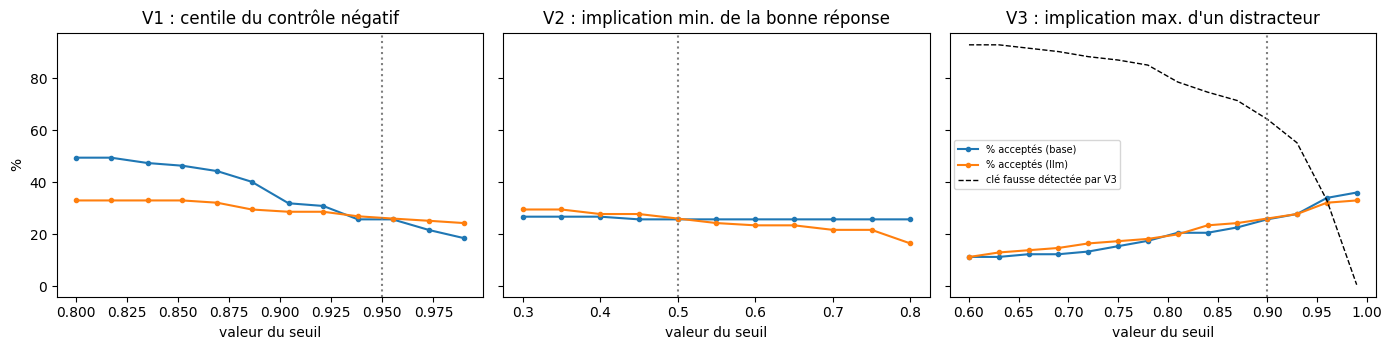

In [52]:
grilles = {"V1 : centile du contrôle négatif": ("centile", np.round(np.linspace(.80, .99, 12), 3), CONFIG["v1_centile_neg"]),
           "V2 : implication min. de la bonne réponse": ("v2", np.round(np.linspace(.3, .8, 11), 2), CONFIG["v2_imp_min"]),
           "V3 : implication max. d'un distracteur": ("v3", np.round(np.linspace(.6, .99, 14), 3), CONFIG["v3_imp_max"])}
methodes = sorted(df_val["methode"].unique())
prefere_bonne = imp_all.argmax(axis=1) == c_all
fausse_cle = np.random.default_rng(CONFIG["seed"]).integers(1, 4, len(c_all))
fausse_cle = (c_all + fausse_cle) % 4                      # un distracteur tiré au hasard, jamais la bonne réponse

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
sens = []
for ax, (titre, (param, valeurs, defaut)) in zip(axes, grilles.items()):
    for m in methodes:
        taux = [100 * decisions(**{param: v})[df_val["qcm_id"][df_val["methode"] == m]].mean() for v in valeurs]
        ax.plot(valeurs, taux, marker="o", ms=3, label=f"% acceptés ({m})")
        sens += [{"seuil": titre, "valeur": v, "methode": m, "% acceptés": round(t, 1)} for v, t in zip(valeurs, taux)]
    if param == "v3":
        detect = [100 * (np.where(np.eye(4, dtype=bool)[fausse_cle], -1, imp_all).max(axis=1)[prefere_bonne] >= v).mean()
                  for v in valeurs]
        ax.plot(valeurs, detect, "k--", lw=1, label="clé fausse détectée par V3")
    ax.axvline(defaut, color="grey", ls=":")
    ax.set(title=titre, xlabel="valeur du seuil")
axes[0].set_ylabel("%")
axes[-1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(CONFIG["fig_dir"] / "sensibilite_seuils.png", dpi=150); plt.show()
pd.DataFrame(sens).to_csv(CONFIG["qcm_dir"] / "sensibilite_seuils.csv", index=False)

In [53]:
if ANNOTATIONS_PRETES:
    # Qualité humaine des acceptés selon le seuil : le seuil par défaut est-il bien placé ?
    lignes = []
    for titre, (param, valeurs, defaut) in grilles.items():
        for v in valeurs[::2]:
            lignes.append({"seuil": titre, "valeur": v, **resume(decisions(**{param: v}))})
    display(pd.DataFrame(lignes).set_index(["seuil", "valeur"]))
else:
    print("Qualité humaine selon le seuil : après les annotations de l'étape 9.")

Qualité humaine selon le seuil : après les annotations de l'étape 9.


## 10.3 et 10.4 Ablations de modèles : calcul des scores

Les sections 10.3 et 10.4 remplacent un modèle ou un réglage du validateur par l'alternative écartée à l'étape 7, et recalculent ses scores :
- **V1 avec CamemBERT FQuAD/PIAF.** Ce modèle ne connaît pas la réponse « pas de réponse ». Son score est donc la **probabilité du meilleur extrait** (début × fin), la confiance que renvoie habituellement le pipeline de questions-réponses ;
- **NLI, formulation (A)** « phrase complétée », pour les questions à trous seulement, puisqu'elle n'a pas de sens pour une question ordinaire ;
- **NLI, prémisse de 1 ou 4 phrases** au lieu de 2 ;
- **NLI mDeBERTa-v3** au lieu de MiniLM, **seulement si un GPU est disponible** : sur processeur, il faudrait environ 30 minutes (étape 7). Sur Colab, il faut moins d'une minute.

Les scores sont mis en cache dans `outputs/qcm/scores_ablation.jsonl`, comme ceux de l'étape 7.

In [54]:
CONFIG.update({"abl_qa_camembert": "etalab-ia/camembert-base-squadFR-fquad-piaf",
               "abl_nli_lent": "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"})
NLI_LENT_POSSIBLE = DEVICE == "cuda" or os.environ.get("QCM_NLI_LENT") == "1"
CACHE_ABL = CONFIG["qcm_dir"] / "scores_ablation.jsonl"
cache_abl = {}
if CACHE_ABL.exists():
    for l in open(CACHE_ABL, encoding="utf-8"):
        r = json.loads(l)
        cache_abl[r["qcm_id"]] = r

# --- Modèle QA écarté : CamemBERT FQuAD/PIAF (même vocabulaire que almanach/camembert-base, dont on prend le tokenizer) ---
tok_cam = AutoTokenizer.from_pretrained(CONFIG["qa_tokenizer"])
modele_cam = AutoModelForQuestionAnswering.from_pretrained(CONFIG["abl_qa_camembert"]).to(DEVICE).eval()

def qa_confiance_camembert(question: str, passage: str) -> float:
    enc = tok_cam(question, passage, truncation="only_second", max_length=CONFIG["qa_max_tokens"], return_tensors="pt")
    dans_passage = torch.tensor([s == 1 for s in enc.sequence_ids(0)])
    sortie = modele_cam(**enc.to(DEVICE))
    p_debut = sortie.start_logits[0].cpu().masked_fill(~dans_passage, -1e4).softmax(-1)
    p_fin = sortie.end_logits[0].cpu().masked_fill(~dans_passage, -1e4).softmax(-1)
    P = torch.triu(p_debut[:, None] * p_fin[None, :])
    P = P - torch.triu(P, diagonal=CONFIG["qa_max_tokens_reponse"])
    return float(P.max())

def implication_variante(q: dict, passage: str, k: int, formulation: str, tok=None, modele=None, idx=None) -> list[float] | None:
    # Comme implication_options (étape 7), avec la taille de prémisse, la formulation et le modèle NLI en paramètres
    tok, modele, idx = tok or tok_nli, modele or modele_nli, IDX_IMPLICATION if idx is None else idx
    if formulation == "A":
        citation = re.search(r"«\s*(.*?)\s*»", q["question"])
        if "_____" not in q["question"] or not citation:
            return None
        hyps = [citation.group(1).replace("_____", o) for o in q["options"]]
    else:
        hyps = [f"{q['question']} Réponse : {o}." for o in q["options"]]
    phrases = [p for p in decouper_phrases(passage) if len(p.split()) >= 3] or [passage]
    E = emb_model.encode(phrases + hyps, normalize_embeddings=True, show_progress_bar=False)
    E_ph, E_hyp = E[:len(phrases)], E[len(phrases):]
    prem = [" ".join(phrases[j] for j in sorted(np.argsort(-(E_ph @ e))[:k])) for e in E_hyp]
    enc = tok(prem, hyps, truncation="only_first", max_length=256, padding=True, return_tensors="pt")
    return modele(**enc.to(DEVICE)).logits.softmax(-1)[:, idx].cpu().numpy().round(4).tolist()

EXPERIENCES = {   # nom -> fonction (q, passage) -> valeur
    "cam_score": lambda q, p: round(qa_confiance_camembert(q["question"], p), 4),
    "cam_score_neg": lambda q, p: round(qa_confiance_camembert(q["question"], passage_negatif(q)), 4),
    "nli_A_k2": lambda q, p: implication_variante(q, p, 2, "A"),
    "nli_B_k1": lambda q, p: implication_variante(q, p, 1, "B"),
    "nli_B_k4": lambda q, p: implication_variante(q, p, 4, "B"),
}
if NLI_LENT_POSSIBLE:
    tok_lent = AutoTokenizer.from_pretrained(CONFIG["abl_nli_lent"])
    modele_lent = AutoModelForSequenceClassification.from_pretrained(CONFIG["abl_nli_lent"]).to(DEVICE).eval()
    idx_lent = next(i for i, l in modele_lent.config.id2label.items() if l.lower().startswith("entail"))
    EXPERIENCES["nli_mdeberta"] = lambda q, p: implication_variante(q, p, 2, "B", tok_lent, modele_lent, idx_lent)
else:
    print("mDeBERTa ignoré (pas de GPU) : exécuter sur Colab pour cette ablation.")

t0, n_calc = time.time(), 0
for q in tous_qcm:
    r = cache_abl.setdefault(q["qcm_id"], {"qcm_id": q["qcm_id"]})
    manquantes = [e for e in EXPERIENCES if e not in r]
    for e in manquantes:
        r[e] = EXPERIENCES[e](q, texte_de[q["passage_id"]])
    n_calc += bool(manquantes)
if n_calc:
    with open(CACHE_ABL, "w", encoding="utf-8") as f:
        for r in cache_abl.values():
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
print(f"Scores d'ablation : {n_calc} QCM calculés ({time.time() - t0:.0f} s), {len(tous_qcm) - n_calc} relus du cache.")
df_abl = pd.DataFrame([cache_abl[q["qcm_id"]] for q in tous_qcm])

config.json:   0%|          | 0.00/515 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] CamembertForQuestionAnswering LOAD REPORT from: etalab-ia/camembert-base-squadFR-fquad-piaf
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

... (8 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Scores d'ablation : 212 QCM calculés (24 s), 0 relus du cache.


## 10.3 V1 : un modèle QA qui sait dire « pas de réponse » est-il nécessaire ?

On compare les deux modèles sur le **contrôle négatif** de l'étape 7 : même question, vrai passage ou passage d'un autre cours. L'**AUC** mesure la probabilité qu'une question posée à son vrai passage obtienne un score plus élevé que posée à un passage sans rapport. On donne aussi le taux de questions acceptées sur le vrai passage quand on fixe, pour chaque modèle, le seuil au 95e centile de ses scores négatifs (la règle de l'étape 7). À taux de fausse acceptation égal (5 %), le meilleur modèle accepte le plus de vraies questions.

In [55]:
lignes = []
for m in methodes:
    g = df_val["methode"] == m
    for nom, pos, neg in [("XLM-R SQuAD 2.0 (retenu)", df_val.loc[g, "qa_score"], df_val.loc[g, "qa_score_neg"]),
                          ("CamemBERT FQuAD/PIAF", df_abl.loc[g.values, "cam_score"], df_abl.loc[g.values, "cam_score_neg"])]:
        y = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
        seuil = np.quantile(neg, CONFIG["v1_centile_neg"])
        lignes.append({"methode": m, "modèle QA": nom, "AUC": round(roc_auc_score(y, np.r_[pos, neg]), 3),
                       "% vraies questions acceptées (5 % de fausses acceptations)": round(100 * (pos >= seuil).mean(), 1)})
pd.DataFrame(lignes).set_index(["methode", "modèle QA"])

AUC  \
methode modèle QA                         
base    XLM-R SQuAD 2.0 (retenu)  0.993   
        CamemBERT FQuAD/PIAF      0.786   
llm     XLM-R SQuAD 2.0 (retenu)  0.942   
        CamemBERT FQuAD/PIAF      0.780   

                                  % vraies questions acceptées (5 % de fausses acceptations)  
methode modèle QA                                                                             
base    XLM-R SQuAD 2.0 (retenu)                                               96.9           
        CamemBERT FQuAD/PIAF                                                   30.9           
llm     XLM-R SQuAD 2.0 (retenu)                                               73.9           
        CamemBERT FQuAD/PIAF                                                   27.8

## 10.4 V2 et V3 : formulation, taille de la prémisse, modèle NLI

Pour chaque variante du NLI, trois mesures :
- **discernement** (QCM de la base) : part des QCM où la bonne réponse obtient la plus forte implication. Le hasard donne 25 % ;
- **% acceptés par V2 et V3**, avec les seuils par défaut ;
- **clé fausse détectée par V3** : défaut injecté de l'étape 7, mesuré sur les QCM où la variante préfère la bonne réponse.

La formulation (A) n'existe que pour les questions à trous, et la comparaison A/B se fait donc sur les QCM de la base. La décision V2/V3 est recalculée avec chaque variante, puis combinée avec la forme et V1, qui restent inchangés, pour donner aussi la qualité humaine une fois les annotations disponibles.

In [56]:
variantes_nli = {"B, 2 phrases (retenu)": imp_all, "A, 2 phrases": "nli_A_k2",
                 "B, 1 phrase": "nli_B_k1", "B, 4 phrases": "nli_B_k4"}
if "nli_mdeberta" in df_abl:
    variantes_nli["B, 2 phrases, mDeBERTa"] = "nli_mdeberta"

lignes = []
for nom, src in variantes_nli.items():
    if isinstance(src, str):
        valeurs = df_abl[src]
        dispo = valeurs.notna().to_numpy()
        imp_v = np.array([v if isinstance(v, list) else [np.nan] * 4 for v in valeurs], dtype=float)
    else:
        imp_v, dispo = src, np.ones(len(src), dtype=bool)
    base_ok = EST_BASE & dispo
    v23 = decisions(controles=("V2", "V3"), imp=np.nan_to_num(imp_v, nan=0.0)).to_numpy()
    pref = (imp_v.argmax(axis=1) == c_all) & dispo
    det = np.where(np.eye(4, dtype=bool)[fausse_cle], -1, np.nan_to_num(imp_v)).max(axis=1)[pref] >= CONFIG["v3_imp_max"]
    ligne = {"variante": nom, "QCM évalués": int(dispo.sum()),
             "discernement base (%)": round(100 * (imp_v[base_ok].argmax(axis=1) == c_all[base_ok]).mean(), 1),
             **{f"% acceptés V2+V3 {m}": round(100 * v23[dispo & (df_val["methode"] == m).to_numpy()].mean(), 1)
                for m in methodes if (dispo & (df_val["methode"] == m).to_numpy()).any()},
             "clé fausse détectée par V3 (%)": round(100 * det.mean(), 1)}
    if ANNOTATIONS_PRETES and dispo.all():
        ligne.update({f"qualité humaine {m} (%)": v for m, v in qualite_humaine(decisions(imp=imp_v)).items()})
    lignes.append(ligne)
pd.DataFrame(lignes).set_index("variante")

,QCM évalués,discernement base (%),% acceptés V2+V3 base,% acceptés V2+V3 llm,clé fausse détectée par V3 (%)
variante,,,,,
"B, 2 phrases (retenu)",212,90.7,64.9,41.7,64.3
"A, 2 phrases",97,64.9,16.5,NaN,95.2
"B, 1 phrase",212,91.8,85.6,39.1,24.8
"B, 4 phrases",212,86.6,54.6,37.4,60.5
"B, 2 phrases, mDeBERTa",212,69.1,21.6,48.7,37.1


## 10.5 Température de génération du LLM

À l'étape 5, le LLM génère en **décodage glouton** (température 0) : il choisit à chaque pas le mot le plus probable. C'est un choix de **reproductibilité**. On peut se demander si un décodage **échantillonné**, plus varié, donnerait des QCM plus intéressants ou au contraire plus d'erreurs. On régénère donc les QCM de `abl_n_passages` = 40 passages à **température 0,7 et 1,0**, puis on les fait passer par **le même filtre**, avec les mêmes contrôles de forme, le même validateur et les mêmes seuils. On compare enfin :
- la part de sorties au **format valide** ;
- le taux de **conformité de forme** ;
- le taux de **passage de V1, V2 et V3** ;
- le taux d'**acceptation** final ;
- la **diversité** des questions : part de mots de la question absents du passage. Plus elle est élevée, plus la question **reformule** au lieu de recopier.

Cette expérience demande un GPU, comme l'étape 5. Sans GPU, elle relit le cache `qcm_llm_temperature.jsonl` s'il existe, sinon elle passe son tour.

In [57]:
CONFIG.update({"abl_temperatures": [0.7, 1.0], "abl_n_passages": int(os.environ.get("QCM_ABL_N", 40))})
CACHE_TEMP = CONFIG["qcm_dir"] / "qcm_llm_temperature.jsonl"

if CACHE_TEMP.exists():
    qcm_temp = [json.loads(l) for l in open(CACHE_TEMP, encoding="utf-8")]
    print(f"{len(qcm_temp)} QCM relus depuis {CACHE_TEMP.name}")
elif GENERATION_POSSIBLE and qcm_llm_list:
    tok_llm, modele = charger_llm(CONFIG["llm_model"])
    sous_ech = list(echantillon.head(CONFIG["abl_n_passages"]).itertuples())
    temp_defaut, qcm_temp = CONFIG["llm_temp_relance"], []
    for T in CONFIG["abl_temperatures"]:
        CONFIG["llm_temp_relance"] = T          # generer_lot (étape 5) lit la température ici
        set_seed(CONFIG["seed"])
        for i in range(0, len(sous_ech), CONFIG["llm_batch"]):
            lot = sous_ech[i:i + CONFIG["llm_batch"]]
            for p, txt in zip(lot, generer_lot(tok_llm, modele, [p.texte for p in lot], echantillonner=True)):
                d, err = lire_json(txt)
                qcm_temp.append({"passage_id": p.passage_id, "temperature": T, "format_ok": d is not None,
                                 **({k: v for k, v in vers_format_commun(p, d, 1, 0.0).items() if k != "duree_s"}
                                    if d is not None else {})})
        print(f"  température {T} : {sum(q['temperature'] == T and q['format_ok'] for q in qcm_temp)}"
              f"/{len(sous_ech)} sorties valides")
    CONFIG["llm_temp_relance"] = temp_defaut
    for q in qcm_temp:
        if q["format_ok"]:
            q["qcm_id"] = f"{q['qcm_id']}_T{q['temperature']}"
            q["methode"] = f"llm_T{q['temperature']}"
    with open(CACHE_TEMP, "w", encoding="utf-8") as f:
        for q in qcm_temp:
            f.write(json.dumps(q, ensure_ascii=False) + "\n")
    del modele
    if GPU:
        torch.cuda.empty_cache()
else:
    qcm_temp = []
    print("Ablation de la température ignorée : elle demande un GPU et les QCM du LLM (étape 5, sur Colab).")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  température 0.7 : 36/40 sorties valides
  température 1.0 : 38/40 sorties valides


In [58]:
if qcm_temp:
    passages_temp = {q["passage_id"] for q in qcm_temp}
    reference = [dict(q, temperature=0.0, format_ok=True) for q in qcm_llm_list if q["passage_id"] in passages_temp]
    n_passages = len(passages_temp)
    # Scores du validateur pour les nouveaux QCM, ajoutés au cache de l'étape 7
    nouveaux = [q for q in qcm_temp if q["format_ok"] and q["qcm_id"] not in cache]
    for q in nouveaux:
        passage = texte_de[q["passage_id"]]
        extrait, score = qa_repondre(q["question"], passage)
        cache[q["qcm_id"]] = {"qcm_id": q["qcm_id"], "signature": signature, "qa_extrait": extrait,
                              "qa_score": round(score, 3), "qa_score_neg": np.nan,
                              "implication": implication_options(q, passage)}
    if nouveaux:
        with open(CACHE_VAL, "w", encoding="utf-8") as f:
            for r in cache.values():
                f.write(json.dumps(r, ensure_ascii=False) + "\n")

    def mots(t):
        return set(normaliser(t).split())
    lignes = []
    for T in [0.0] + CONFIG["abl_temperatures"]:
        groupe = reference if T == 0.0 else [q for q in qcm_temp if q["temperature"] == T]
        valides = [q for q in groupe if q["format_ok"]]
        res = []
        for q in valides:
            s = cache[q["qcm_id"]]
            imp_q = np.array(s["implication"]); c_q = q["index_correct"]
            forme = not any(controles_forme(q).values())
            v1 = s["qa_score"] >= seuil_v1
            v2 = imp_q.argmax() == c_q and imp_q[c_q] >= CONFIG["v2_imp_min"]
            v3 = np.delete(imp_q, c_q).max() < CONFIG["v3_imp_max"]
            nouv = mots(q["question"]) - mots(texte_de[q["passage_id"]])
            res.append({"forme": forme, "V1": v1, "V2": v2, "V3": v3, "accepte": forme and v1 and v2 and v3,
                        "reformulation": len(nouv) / max(1, len(mots(q["question"])))})
        r = pd.DataFrame(res, columns=["forme", "V1", "V2", "V3", "accepte", "reformulation"])  # vide si aucune sortie valide
        lignes.append({"température": "0 (glouton, étape 5)" if T == 0.0 else T,
                       "format valide (%)": round(100 * len(valides) / n_passages, 1),
                       **{f"% {k}": round(100 * r[k].mean(), 1) for k in ["forme", "V1", "V2", "V3", "accepte"]},
                       "QCM acceptés / passages (%)": round(100 * r["accepte"].sum() / n_passages, 1),
                       "mots nouveaux dans la question (%)": round(100 * r["reformulation"].mean(), 1)})
    display(pd.DataFrame(lignes).set_index("température"))

,format valide (%),% forme,% V1,% V2,% V3,% accepte,QCM acceptés / passages (%),mots nouveaux dans la question (%)
température,,,,,,,,
"0 (glouton, étape 5)",97.5,82.1,71.8,48.7,74.4,25.6,25.0,29.1
0.7,90.0,77.8,75.0,58.3,88.9,27.8,25.0,30.4
1.0,95.0,73.7,78.9,55.3,73.7,34.2,32.5,29.6


---
### Bilan de l'étape 10
- **Ablation des contrôles** : la contribution de chaque contrôle au taux d'acceptation se lit directement. Sa contribution à la qualité s'ajoutera avec les annotations, grâce à la pondération de Horvitz-Thompson qui réutilise l'échantillon de l'étape 9.
- **Sensibilité** : courbes du taux d'acceptation pour les trois seuils, et compromis acceptation / détection pour V3 (figure `sensibilite_seuils.png`).
- **Modèles** : AUC de V1 avec ou sans « pas de réponse », et discernement du NLI selon la formulation, la taille de la prémisse et le modèle.
- **Température** du LLM : comparaison glouton / 0,7 / 1,0 sur 40 passages, avec le même filtre (sur GPU).

**Premiers enseignements, sur les QCM de la base :**
- **V3 est le contrôle qui pèse le plus.** Sans lui, 87 % des QCM seraient acceptés, contre 63 %. La forme et V1 ne retirent presque rien de plus que les autres contrôles. Reste à savoir, grâce aux annotations, si ces rejets de V3 sont justifiés.
- **Le modèle QA SQuAD 2.0 est nettement meilleur pour V1.** À 5 % de fausses acceptations, il accepte 97 % des vraies questions, contre 31 % pour CamemBERT FQuAD/PIAF.
- **La formulation (B) l'emporte sur (A).** Avec (A), le NLI ne préfère la bonne réponse que dans 65 % des cas, contre 91 % avec (B). Le taux de clés fausses détectées par (A), plus élevé, est trompeur : la formulation (A) rejette presque tout (84 % des QCM), bons compris.
- **La prémisse de 2 phrases est le meilleur compromis.** Avec 1 phrase, V3 ne détecte plus qu'un quart des clés fausses. Avec 4 phrases, le signal se dilue : le NLI discerne moins bien la bonne réponse et détecte moins de clés fausses.

Plusieurs mesures **attendent encore** soit les annotations humaines, soit un GPU : la qualité humaine des variantes, l'ablation mDeBERTa et la température. Elles se calculent automatiquement quand ces éléments sont disponibles.

On passe maintenant à l'étape 11 : l'analyse des erreurs, les limites et l'éthique.

---
# Étape 11 — Analyse des erreurs, limites et éthique

**À quoi sert cette étape ?** Les chiffres des étapes précédentes disent **combien** de QCM sont rejetés ou acceptés. L'analyse des erreurs dit **pourquoi**. Elle ramène chaque échec à sa **cause**, et seule la cause indique quoi améliorer : l'extraction du texte, le générateur ou le validateur. On termine par les **limites** du travail et ses **enjeux éthiques**.

**Méthode.** On classe les QCM rejetés par **symptôme**, avec des indicateurs automatiques simples. On lit ensuite des exemples de chaque classe pour vérifier que le symptôme correspond bien à une cause. Une fois les annotations disponibles, on étudie en plus les **erreurs du validateur lui-même** : les QCM bons qu'il rejette et les QCM mauvais qu'il accepte.

## 11.1 Typologie des rejets

Chaque QCM rejeté reçoit **une** catégorie : la première de la liste suivante qui s'applique. Les catégories vont de la cause la plus en amont, le texte source, à la plus en aval, le validateur :

| Catégorie | Indicateur automatique | Cause probable |
|---|---|---|
| **texte source dégradé** | moins de 80 % de tokens alphabétiques dans la question (dans la phrase citée, pour une question à trous) | résidus d'extraction PDF : code, adresses, fragments (« -O, -O1, -O2 ») |
| **défaut de forme** | une règle F1–F7 échoue | générateur |
| **réponse introuvable** | V1 échoue | question hors du passage, ou trop vague |
| **bonne réponse non confirmée** | V2 échoue | clé fausse, ou NLI qui préfère une autre option |
| **distracteur proche de la réponse** | V3 échoue, et similarité distracteur–réponse ≥ 0,6 | distracteur synonyme ou de la même famille : sans doute **vraiment** correct |
| **distracteur confirmé sans être proche** | V3 échoue, similarité < 0,6 | **fausse alerte probable** du NLI, indulgent avec la formulation « question + réponse » |

La distinction entre les deux dernières catégories est importante pour l'évaluation du validateur. Un distracteur proche du sens de la réponse (« octets » pour « bits ») peut réellement être défendu par un étudiant. Un distracteur sans rapport (« livre » pour un nom propre) ne l'est pas : si le NLI le juge confirmé, c'est le NLI qui se trompe. Le seuil de 0,6 est indicatif, et la lecture des exemples le vérifie.

In [59]:
SIM_PROCHE = 0.6

def part_alphabetique(question: str) -> float:
    # Part des tokens qui sont des mots (lettres seulement, ponctuation collée tolérée), toutes longueurs confondues.
    # Pour une question à trous, on mesure la phrase citée, qui vient directement de l'extraction PDF.
    t = question.replace("_____", "trou")
    citation = re.search(r"«(.*)»", t)
    el = (citation.group(1) if citation else t).split()
    return sum(bool(re.fullmatch(r"[«(\"“]?[A-Za-zÀ-ÿ'’\-]+[.,:;!?)»\"”]?", e)) for e in el) / max(1, len(el))

def sim_max_distracteur(q: dict, implication: list[float]) -> float:
    # Similarité (embeddings) entre la bonne réponse et le distracteur le plus confirmé par le NLI
    c = q["index_correct"]
    k = max((i for i in range(4) if i != c), key=lambda i: implication[i])
    e = emb_model.encode([q["options"][c], q["options"][k]], normalize_embeddings=True, show_progress_bar=False)
    return float(e[0] @ e[1])

def categorie(r) -> str:
    q = par_id[r["qcm_id"]]
    if part_alphabetique(q["question"]) < 0.8:
        return "texte source dégradé"
    if not r["forme_ok"]:
        return "défaut de forme"
    if not r["V1"]:
        return "réponse introuvable"
    if not r["V2"]:
        return "bonne réponse non confirmée"
    if sim_max_distracteur(q, r["implication"]) >= SIM_PROCHE:
        return "distracteur proche de la réponse"
    return "distracteur confirmé sans être proche"

rejets = df_val[~df_val["qcm_id"].map(df_filtre.set_index("qcm_id")["accepte"])].copy()
rejets["categorie"] = rejets.apply(categorie, axis=1)
ORDRE_CAT = ["texte source dégradé", "défaut de forme", "réponse introuvable", "bonne réponse non confirmée",
             "distracteur proche de la réponse", "distracteur confirmé sans être proche"]
typo = pd.crosstab(rejets["categorie"], rejets["methode"]).reindex(ORDRE_CAT).fillna(0).astype(int)
typo.loc["Total des rejets"] = typo.sum()
rejets[["qcm_id", "methode", "cours_id", "categorie"]].to_csv(CONFIG["qcm_dir"] / "typologie_rejets.csv", index=False)
typo

methode,base,llm
categorie,,
texte source dégradé,2,5
défaut de forme,1,24
réponse introuvable,52,15
bonne réponse non confirmée,7,34
distracteur proche de la réponse,9,3
distracteur confirmé sans être proche,1,4
Total des rejets,72,85


**Un exemple par catégorie.** La lecture confirme ou corrige l'indicateur automatique. Les exemples choisis sont les premiers de chaque catégorie, sans tri, pour ne pas sélectionner les cas les plus parlants.

**À propos de la catégorie « distracteur proche » pour la base.** La base choisit ses distracteurs parmi les **voisins de la réponse** dans l'espace des embeddings (étape 4), en excluant seulement les quasi-synonymes (similarité ≥ 0,85). Presque tous ses distracteurs sont donc « proches » au sens de cet indicateur. Quand V3 la rejette, c'est souvent parce qu'un voisin trop proche est en partie correct (« octets » pour « bits », « déclaration » sous deux orthographes). Il y a là un **compromis** propre au générateur : plus le distracteur est proche, plus il est plausible, mais plus il risque d'être juste. Abaisser le seuil de 0,85 de l'étape 4 rendrait les distracteurs plus sûrs mais plus faciles à éliminer.

In [60]:
for cat in ORDRE_CAT:
    ex = rejets[rejets["categorie"] == cat]
    if len(ex):
        print(f"■ {cat} ({len(ex)} QCM)")
        afficher_validation(ex.iloc[0]["qcm_id"])

■ texte source dégradé (7 QCM)
[BASE_C1_044] Complétez la phrase : « Nous sommes dans la configuration: _____ valeur i 4831836000 3 p 4831836004 4831836000 *p 4831836000 3 Cela signifie en particulier que toute modification de *p modifie i. »
    A) préciser unsigned
    B) pointeurs vers
    C) chemin accès
    D) objet adresse  ✔

    extrait QA : « objet adresse »  score V1 = -2.08 (seuil -1.87)
    implication par option : {'A': 0.85, 'B': 0.96, 'C': 0.38, 'D': 0.96}
    V1 ✘   V2 ✘   V3 ✘

■ défaut de forme (25 QCM)
[BASE_C4_026] Complétez la phrase : « La _____ d’une fonction permet de préciser son prototype avant de l'utiliser dans le programme. »
    A) précisant
    B) déclaration  ✔
    C) termes
    D) declaration

    extrait QA : « déclaration »  score V1 = 1.83 (seuil -1.87)
    implication par option : {'A': 0.95, 'B': 0.97, 'C': 0.9, 'D': 0.96}
    V1 ✔   V2 ✔   V3 ✘

■ réponse introuvable (67 QCM)
[BASE_C1_000] Complétez la phrase : « Le C a été conçu en 1972 par Denni

## 11.2 Erreurs par cours : le poids de l'extraction

On met en regard, pour chaque cours, le **format du document**, la **part du texte retirée** par le nettoyage (étape 2) et le **taux d'acceptation** final. Si les cours les plus dégradés par l'extraction sont aussi ceux qui donnent le moins de QCM acceptés, une part des erreurs vient de **l'amont** du pipeline, et pas des générateurs. Avec seulement 6 cours, ce n'est pas une preuve statistique, seulement une piste à lire avec les exemples.

In [61]:
par_cours = sources.set_index("id")[["format", "%_retire"]].rename(columns={"%_retire": "% du texte retiré"})
for m in methodes:
    g = df_filtre[df_filtre["methode"] == m]
    par_cours[f"QCM produits ({m})"] = g.groupby("cours_id").size()
    par_cours[f"% acceptés ({m})"] = (100 * g.groupby("cours_id")["accepte"].mean()).round(0)
par_cours.fillna(0)

,format,% du texte retiré,QCM produits (base),% acceptés (base),QCM produits (llm),% acceptés (llm)
id,,,,,,
C1,polycopié LaTeX,36.1,19,26.0,20,30.0
C2,polycopié,38.6,19,16.0,19,21.0
C3,polycopié Word,37.3,20,30.0,17,35.0
C4,polycopié Word,51.9,18,33.0,20,20.0
C5,polycopié LaTeX,44.7,18,28.0,19,37.0
C6,diapositives,63.2,3,0.0,20,15.0


## 11.3 Hallucinations du LLM : la justification est-elle dans le passage ?

Le prompt de l'étape 5 demande au LLM une **justification** : une phrase du passage qui prouve la bonne réponse. Si cette justification ne se retrouve pas dans le passage, le LLM l'a **inventée**, et sa bonne réponse est suspecte. On mesure, pour chaque QCM du LLM, la **part des mots de la justification présents dans le passage**. Moins de 50 % signale une justification inventée ou fortement reformulée.

On croise ensuite ce signal avec la décision du validateur. Si les QCM à justification inventée sont plus souvent rejetés, le validateur détecte bien les hallucinations, alors qu'il ne lit **pas** la justification.

In [62]:
if qcm_llm_list:
    def part_dans_passage(justif: str, passage: str) -> float:
        mots_j = [w for w in normaliser(justif).split() if len(w) > 2]
        mots_p = set(normaliser(passage).split())
        return sum(w in mots_p for w in mots_j) / len(mots_j) if mots_j else np.nan
    hal = pd.DataFrame([{"qcm_id": q["qcm_id"],
                         "justif_dans_passage": part_dans_passage(q.get("justification", ""), texte_de[q["passage_id"]])}
                        for q in qcm_llm_list]).merge(df_filtre[["qcm_id", "accepte"]], on="qcm_id")
    hal["justification inventée (< 50 %)"] = hal["justif_dans_passage"] < 0.5
    print(f"Justifications inventées : {hal['justification inventée (< 50 %)'].mean():.0%} des QCM du LLM")
    display((pd.crosstab(hal["justification inventée (< 50 %)"], hal["accepte"].map({True: "accepté", False: "rejeté"}),
                         normalize="index") * 100).round(1))
else:
    print("QCM du LLM absents (étape 5 sur Colab) : analyse des justifications en attente.")

Justifications inventées : 0% des QCM du LLM


accepte,accepté,rejeté
justification inventée (< 50 %),,
False,26.1,73.9


## 11.4 Erreurs du validateur, selon les évaluateurs

Une fois les grilles remplies, on liste les deux types d'erreurs du validateur :
- **faux rejets** : QCM rejetés que **les deux** évaluateurs jugent acceptables. Le filtre fait perdre de bonnes questions ;
- **fausses acceptations** : QCM acceptés que **les deux** évaluateurs jugent non acceptables. Le filtre laisse passer des défauts.

Pour chacun, on affiche les scores du validateur et les commentaires des évaluateurs. C'est la matière la plus utile pour l'article : elle montre des cas concrets où le validateur se trompe, et pourquoi.

In [63]:
if ANNOTATIONS_PRETES:
    d = cle.copy()
    d["humain_ok"] = d["eval_id"].map(accept_A & accept_B)
    d["humain_ko"] = d["eval_id"].map(~accept_A & ~accept_B)
    commentaires = (A["commentaire"].fillna("") + " | " + B["commentaire"].fillna("")).str.strip(" |")
    for titre, masque in [("Faux rejets (rejeté, jugé acceptable)", ~d["accepte"] & d["humain_ok"]),
                          ("Fausses acceptations (accepté, jugé non acceptable)", d["accepte"] & d["humain_ko"])]:
        print(f"■ {titre} : {int(masque.sum())} QCM")
        for _, r in d[masque].head(5).iterrows():
            afficher_validation(r["qcm_id"])
            print(f"    commentaires : {commentaires.get(r['eval_id'], '') or '—'}\n")
    # Catégorie automatique des faux rejets : quelle catégorie de 11.1 contient le plus de rejets injustifiés ?
    fr = rejets.merge(d[["qcm_id", "humain_ok"]], on="qcm_id")
    if len(fr):
        print("Part des rejets jugés acceptables par les deux évaluateurs, par catégorie :")
        display((fr.groupby("categorie")["humain_ok"].agg(["count", "mean"])
                 .rename(columns={"count": "rejets annotés", "mean": "% jugés acceptables"})
                 .assign(**{"% jugés acceptables": lambda t: (100 * t["% jugés acceptables"]).round(1)})))
else:
    print("En attente des grilles remplies (étape 9).")

En attente des grilles remplies (étape 9).


## 11.5 Une limite mesurée : un contrôle négatif plus difficile pour V1

Le seuil de V1 a été calibré sur des questions posées à un passage d'un **autre cours** (étape 7). C'est un contrôle **facile** : un passage sur les fichiers ne ressemble pas à un passage sur les pointeurs. Une question mal ancrée risque plutôt de « trouver » une réponse dans un passage **voisin du même cours**. On refait donc la mesure avec un passage **du même cours**, tiré au hasard, et on compare les AUC. Si l'AUC baisse nettement, V1 distingue moins bien les cas difficiles, et son taux de fausse acceptation réel est **supérieur** aux 5 % annoncés.

In [64]:
def passage_meme_cours(q: dict) -> str:
    autres = [p for p in ids_par_cours[q["cours_id"]] if p != q["passage_id"]]
    return texte_de[random.Random(f"{CONFIG['seed']}-meme-{q['qcm_id']}").choice(autres)]

n_calc = 0
for q in tous_qcm:
    r = cache_abl.setdefault(q["qcm_id"], {"qcm_id": q["qcm_id"]})
    if "qa_score_neg_meme_cours" not in r:
        r["qa_score_neg_meme_cours"] = round(qa_repondre(q["question"], passage_meme_cours(q))[1], 3)
        n_calc += 1
if n_calc:
    with open(CACHE_ABL, "w", encoding="utf-8") as f:
        for r in cache_abl.values():
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

neg_meme = df_val["qcm_id"].map(lambda i: cache_abl[i]["qa_score_neg_meme_cours"])
lignes = []
for m in methodes:
    g = (df_val["methode"] == m).to_numpy()
    pos = df_val.loc[g, "qa_score"]
    for nom, neg in [("autre cours (étape 7)", df_val.loc[g, "qa_score_neg"]), ("même cours", neg_meme[g])]:
        lignes.append({"methode": m, "contrôle négatif": nom,
                       "AUC": round(roc_auc_score(np.r_[np.ones(len(pos)), np.zeros(len(neg))], np.r_[pos, neg]), 3),
                       "% de questions acceptées sur le passage négatif (seuil de l'étape 7)": round(100 * (neg >= seuil_v1).mean(), 1)})
pd.DataFrame(lignes).set_index(["methode", "contrôle négatif"])

AUC  \
methode contrôle négatif               
base    autre cours (étape 7)  0.993   
        même cours             0.992   
llm     autre cours (étape 7)  0.942   
        même cours             0.944   

                               % de questions acceptées sur le passage négatif (seuil de l'étape 7)  
methode contrôle négatif                                                                             
base    autre cours (étape 7)                                                0.0                     
        même cours                                                           0.0                     
llm     autre cours (étape 7)                                                9.6                     
        même cours                                                          11.3

## 11.6 Limites

**Données.**
- 6 supports de cours, un seul sujet (le langage C), une seule langue. Les conclusions ne se généralisent pas telles quelles à d'autres matières, et un cours de mathématiques ou d'histoire poserait d'autres problèmes.
- L'extraction PDF **retire le code** (étape 2). Aucune question ne porte donc sur la lecture d'un programme, alors que c'est essentiel dans un cours de C. Le retrait laisse aussi des phrases orphelines (« par l'instruction : où type est… »), à l'origine d'une partie des rejets.
- Les diapositives (C6), écrites en style télégraphique, produisent peu de passages exploitables.

**Générateurs.**
- La base de référence ne pose que des questions à trous sur un mot ou un groupe de mots : elle teste la mémoire du texte plus que la compréhension.
- Un seul LLM, un seul prompt, sans fine-tuning. Un autre modèle ou un autre prompt pourrait changer le classement des méthodes.

**Validateur.**
- Il ne connaît que **le passage**. Un distracteur vrai en C mais absent du passage est jugé « non confirmé », donc accepté comme distracteur. À l'inverse, une bonne réponse juste mais formulée autrement que dans le passage peut être rejetée.
- Le modèle NLI est **petit** (6 couches) et **indulgent**. V3 produit des fausses alertes, comme les distracteurs confirmés sans être proches de la réponse (section 11.1).
- Le modèle QA est entraîné en **anglais** : il fonctionne en français par transfert, sans garantie sur le vocabulaire technique.
- Les seuils sont **justifiés mais pas optimisés** sur des données annotées. Les optimiser sur les 60 QCM de l'évaluation, puis mesurer la qualité sur ces mêmes QCM, surestimerait les performances (sur-apprentissage). Il faudrait un second jeu annoté.
- Le contrôle négatif de V1 est facile : la section 11.5 montre ce qu'il devient avec des passages du même cours.

**Évaluation.**
- 60 QCM et 2 évaluateurs : les intervalles de confiance sont larges, de l'ordre de ±15 à 20 points par case.
- Les évaluateurs sont **les auteurs du projet**. Même en aveugle, ils peuvent reconnaître la méthode (les questions à trous) et ne sont pas neutres.

**Reproductibilité.** Graines fixées et décodage glouton rendent l'exécution reproductible sur une même machine. Deux sources d'écart restent possibles :
- les calculs sur GPU en 4 bits ne sont pas parfaitement déterministes d'une carte à l'autre ;
- les modèles sur Hugging Face peuvent être mis à jour.

Les caches (`qcm_llm.jsonl`, `scores_*.jsonl`) figent les résultats exacts de cette étude.

## 11.7 Éthique

**Droits d'auteur.** Les supports de cours appartiennent à leurs auteurs. Pour cette raison :
- les PDF ne sont **pas versionnés** ;
- le dépôt est **privé**, car les passages extraits et les QCM contiennent des extraits des cours ;
- `sources.csv` cite chaque auteur.

Une diffusion publique des QCM demanderait l'accord des auteurs.

**Données personnelles.** Les adresses électroniques des auteurs, présentes dans les PDF, sont retirées dès le nettoyage (étape 2). Les grilles d'annotation ne contiennent que des jugements sur des QCM, aucune donnée sur les évaluateurs.

**Usage des QCM en examen.** Un QCM faux pénalise un étudiant qui a juste. Même après filtrage, une part des QCM acceptés reste défectueuse : la section 9.5 la mesure. Le système est donc un **outil d'aide à l'enseignant**, qui doit relire chaque question avant usage. Il ne remplace pas cette relecture. Les questions générées doivent être **signalées comme telles** aux étudiants et à l'institution.

**Biais.** Le LLM et les modèles de validation ont été entraînés sur de grands corpus, surtout anglophones. Ils peuvent mieux traiter certaines formulations que d'autres, et favoriser le vocabulaire le plus courant au détriment des termes propres à un cours.

**Coût environnemental.** Générer 120 QCM avec un modèle de 7 milliards de paramètres demande quelques dizaines de minutes de GPU. La validation tourne sur processeur. C'est modeste à l'échelle d'un projet, mais ce coût se répète à chaque génération et doit être mis en balance avec le temps gagné par l'enseignant.

**Licences des modèles.** Tous les modèles utilisés sont publics. La cellule suivante lit leur licence sur Hugging Face, avec la valeur « non renseignée » si la fiche n'en indique pas ou si le réseau est indisponible.

In [65]:
MODELES_UTILISES = {
    "génération (étape 5)": CONFIG["llm_model"],
    "embeddings (étapes 4, 7, 8)": CONFIG["emb_model"],
    "questions-réponses V1 (étape 7)": CONFIG["qa_model"],
    "NLI V2/V3 (étape 7)": CONFIG["nli_model"],
    "QA écarté (ablation)": CONFIG["abl_qa_camembert"],
    "NLI écarté (ablation, GPU)": CONFIG["abl_nli_lent"],
}
try:
    from huggingface_hub import HfApi
    api = HfApi()
    def licence(nom):
        try:
            info = api.model_info(nom)
            return (info.card_data or {}).get("license") or "non renseignée"
        except Exception:
            return "non renseignée"
except ImportError:
    def licence(nom):
        return "non renseignée"
pd.DataFrame([{"rôle": r, "modèle": m, "licence": licence(m)} for r, m in MODELES_UTILISES.items()]).set_index("rôle")

,modèle,licence
rôle,,
génération (étape 5),Qwen/Qwen3-4B-Instruct-2507,apache-2.0
"embeddings (étapes 4, 7, 8)",sentence-transformers/paraphrase-multilingual-...,apache-2.0
questions-réponses V1 (étape 7),deepset/xlm-roberta-base-squad2,cc-by-4.0
NLI V2/V3 (étape 7),MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli,mit
QA écarté (ablation),etalab-ia/camembert-base-squadFR-fquad-piaf,non renseignée
"NLI écarté (ablation, GPU)",MoritzLaurer/mDeBERTa-v3-base-xnli-multilingua...,mit


---
### Bilan de l'étape 11
- Les rejets sont classés en 6 catégories, du texte source au validateur, avec un exemple lu par catégorie. Le détail par QCM est dans `outputs/qcm/typologie_rejets.csv`.
- Le poids de l'extraction est examiné cours par cours. Les hallucinations du LLM sont repérées par sa justification, et les erreurs du validateur seront listées avec les commentaires des évaluateurs.
- Une limite est mesurée : V1 face à un contrôle négatif plus difficile, des passages du même cours.
- Les limites et les enjeux éthiques sont exposés : droits d'auteur, données personnelles, relecture humaine obligatoire, biais, coût, licences.

---
# Conclusion

Le notebook met en place une chaîne complète, du support de cours PDF au QCM validé :
1. extraction et nettoyage de 6 cours de C ;
2. découpage en passages ;
3. deux générateurs, une base de référence par règles et un LLM ouvert ;
4. un filtre en deux temps : 7 règles de forme, puis un validateur sémantique en trois tests (V1 questions-réponses SQuAD 2.0, V2 et V3 NLI) ;
5. un protocole d'évaluation humaine en aveugle, avec accord entre évaluateurs et mesure de l'apport du filtre ;
6. des ablations et une analyse des erreurs.

Chaque choix est justifié, et les principaux sont vérifiés par une mesure (étapes 7 et 10).

**Reste à faire pour compléter les résultats :**
- générer les QCM du LLM sur Colab (étape 5) ;
- faire remplir les deux grilles d'annotation (étape 9) ;
- réexécuter le notebook : toutes les sections en attente se remplissent automatiquement ;
- rédiger l'article de 7 pages à partir des tableaux et figures produits.

---
# Sauvegarde des résultats (Colab)

Une session Colab peut s'arrêter sans prévenir. Cette cellule range les sorties du
notebook dans un seul zip : caches du LLM, scores du validateur, figures et grilles
d'annotation. Le zip est écrit dans `MyDrive/TALN/` si Drive est monté, sinon dans
`/content`, et il ne contient **aucun PDF de cours** (droits des auteurs).


In [66]:
import zipfile

if EN_COLAB:
    base = Path("/content/drive/MyDrive/TALN") if Path("/content/drive/MyDrive").exists() else Path("/content")
    base.mkdir(parents=True, exist_ok=True)
    archive = base / "sorties_taln.zip"
    motifs = ["outputs/qcm/*", "outputs/figures/*", "data/annotations/*"]
    with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as z:
        for motif in motifs:
            for f in sorted(ROOT.glob(motif)):
                if f.is_file() and f.name != ".gitkeep":
                    z.write(f, f.relative_to(ROOT))
    print(f"{len(z.namelist())} fichiers sauvegardés dans {archive}")
    print("À replacer dans le dépôt local :", archive.name)
else:
    print("Hors Colab : les sorties sont déjà dans outputs/qcm/ et data/annotations/.")


21 fichiers sauvegardés dans /content/sorties_taln.zip
À replacer dans le dépôt local : sorties_taln.zip
